# EatThis: recommending a restaurant when someone avoids gluten

**MIT 15.071 The AI Edge, Project 1. Stella Wong and Nick Whalen.**

## What this project is for

EatThis recommends restaurants for a group. This project is about one case: the group includes someone who avoids gluten, and EatThis should favour restaurants likely to offer that person more options.

**Product scope**

- **Where a restaurant publishes allergen information, use it.** Even then, a dish that is not marked for wheat must not be described as verified gluten-free.
- **Where that information is unavailable, estimate.** A model reads the menu and EatThis ranks restaurants by how many dishes look low-risk. Dietary suitability is clearly labelled as unverified, and the diner is told to confirm with the restaurant.
- **No individual dish is recommended for gluten avoidance from predictions alone.** Step 19 shows why.
- **Gluten only.** This project evaluates gluten avoidance, not other allergies. Ordinary dish recommendations for diners without restrictions are outside the evaluation.

**The primary task is choosing the restaurant.** The models predict, for each dish on a menu, how likely it is to contain gluten. Those dish predictions are not the product. They are the inputs to the restaurant ranking: a menu with many low-risk dishes ranks higher.

**The question.** Can AI help EatThis choose a restaurant with a higher share of dishes likely to be free of gluten? And if so, which approach should it use?

"Approach" means two choices:

- **What the AI looks at:** the name of the dish, a photo of the dish, or both.
- **What kind of model:** a keyword rule, a simple model, or a deep learning model.

We compare dish names, photos and both together on recipes, where every dish has a name, a photo and an ingredient list. We then test the text approaches on real restaurant menus, using the restaurants' own published wheat labels as the answers. Restaurant menus in our test have no photos, which is why only the text approaches go on to that test.

## How the notebook is organised

| Part | Question it answers | Steps |
|---|---|---|
| **1. Data, labels and benchmarks** | What do the models learn from, and how do we know the right answers? | 1 to 7 |
| **2. Predicting gluten from a dish name** | How well do a keyword rule, a simple text model, a fine-tuned language model, and the last two combined tell gluten dishes from the rest? | 8 to 12 |
| **3. Comparing dish names, photos and both** | Does a photo of the dish help, alone or added to the name? | 13 to 15 |
| **4. The restaurant test** | Do the text approaches help pick a restaurant with more suitable dishes? Could they also recommend individual dishes? Includes our recommendation and its limits. | 16 to 21 |
| **5. Additional checks** | Three side questions about model design and learning from menus. | 22 to 24 |
| **6. Save and demo** | | 25 and the demo |

**A note on order.** After the notebook was run, its cells were arranged into this reading order, the text was edited for clarity, and one small helper function was moved to an earlier cell. No result was changed: every table and figure is exactly as the run produced it. The small numbers in square brackets beside the cells show the order in which they originally ran.

## Words used throughout

- **Model:** a program that learns patterns from examples and then makes predictions about new cases.
- **Training:** showing a model many examples with the right answers so that it learns.
- **Risk score:** a model's number between 0 and 1 for a dish. Higher means gluten is more likely. It is not an exact probability.
- **Cut-off:** the risk score at or above which a dish is flagged as likely to contain gluten.
- **Wheat and gluten:** our models predict gluten. Restaurant allergen guides list **wheat**, because wheat is an allergen restaurants must declare, and they do not list gluten. Wheat is the main source of gluten, but barley and rye contain it too. So when we test on restaurants, the closest available answer is "the guide marks this dish as containing wheat". A dish not marked for wheat is not guaranteed gluten-free.

**How to read the results.** This was exploratory work. We made choices while looking at results, including on the test recipes and the restaurant dishes, so the numbers are indications and not guarantees. Training a language model on a GPU also gives slightly different numbers each time it is run.

### How to run it

1. Go to [colab.research.google.com](https://colab.research.google.com), choose **File**, then **Upload notebook**, and pick this file.
2. Choose **Runtime**, then **Change runtime type**, pick **L4 GPU** and click Save.
3. Choose **Runtime**, then **Run all**.
4. Within a few seconds, Step 2 shows a box. Paste your Kaggle key and press Enter.
5. Wait about an hour. Results appear under each grey box as it finishes.

Each grey box is called a **cell**. It holds a short piece of code, which is a set of instructions for the computer. You do not need to change any of them.

When it finishes, choose **File**, then **Download**, then **Download .ipynb** to keep a copy with the results showing. Then choose **Runtime**, then **Disconnect and delete runtime**.

# Part 1. Data, labels and benchmarks

## Step 1. Load the tools

These lines load free, standard toolkits for tables, models and charts.

In [55]:
import ast, copy, glob, itertools, json, math, os, re, time
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.sparse import hstack, csr_matrix
from sklearn.model_selection import train_test_split
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import roc_auc_score

pd.set_option("display.max_colwidth", 90)
np.random.seed(0)

import sklearn, sys as _sys
print(f"Python {_sys.version.split()[0]}, pandas {pd.__version__}, numpy {np.__version__}, scikit-learn {sklearn.__version__}")

Python 3.13.16, pandas 2.2.3, numpy 2.4.6, scikit-learn 1.6.1


## Step 2. Sign in to Kaggle

Kaggle is the website that hosts some of the data. A box appears below. Paste your Kaggle key into it and press **Enter**. What you paste stays hidden and is not saved in this notebook.

A Kaggle key is free: sign in at kaggle.com, open Settings, and under API choose Create New Token. Treat it like a password.

In [56]:
%pip install -q -U kagglehub
from getpass import getpass
import kagglehub

kaggle_key = getpass("Paste your Kaggle key here, then press Enter: ").strip()
os.environ["KAGGLE_API_TOKEN"] = kaggle_key
try:
    from kagglehub.config import set_kaggle_api_token
    set_kaggle_api_token(kaggle_key)
except ImportError:
    pass
del kaggle_key
print("Key received.")

Paste your Kaggle key here, then press Enter: ··········
Kaggle credentials set.
Key received.


## Step 3. Load the recipes

About 13,500 recipes collected from Epicurious. Each has a title, an ingredient list and a photo. They are split later into recipes for training and recipes held back for testing.

Source: *Food Ingredients and Recipe Dataset with Images* (Kaggle).

In [57]:
DATA_URL = "https://raw.githubusercontent.com/NewsAppsUMD/recipe-dataset/main/13k-recipes.csv"

recipes = pd.read_csv(DATA_URL)
recipes = recipes.dropna(subset=["Title"]).reset_index(drop=True)
recipes["ingredients"] = recipes["Cleaned_Ingredients"].apply(ast.literal_eval)

print("Recipes loaded:", len(recipes))
recipes[["Title", "ingredients"]].head(3)

Recipes loaded: 13496


,Title,ingredients
0,Miso-Butter Roast Chicken With Acorn Squash Panzanella,"[1 (3½–4-lb.) whole chicken, 2¾ tsp. kosher salt, divided, plus more, 2 small acorn sq..."
1,Crispy Salt and Pepper Potatoes,"[2 large egg whites, 1 pound new potatoes (about 1 inch in diameter), 2 teaspoons kosh..."
2,Thanksgiving Mac and Cheese,"[1 cup evaporated milk, 1 cup whole milk, 1 tsp. garlic powder, 1 tsp. onion powder, 1..."


## Step 4. Work out the right answer for every recipe

To train a model we need the right answer for each recipe: does it contain gluten? The recipes do not say, so we work it out from each recipe's **ingredient list**.

- `GLUTEN_GROUPS` lists words for ingredients that contain gluten, sorted into **nine groups**: wheat flour; bread and buns; breadcrumbs; pasta and noodles; pastry and dough; cookies, crackers and cake; barley, rye and bulgur; soy sauce and similar; beer. If an ingredient contains one of a group's words, the recipe contains that group.
- `EXCEPTIONS` lists phrases that contain a gluten word but are not gluten, such as "rice flour" or "lentil flour". They are removed first.
- Any ingredient described as gluten-free is ignored.
- A recipe **contains gluten** if at least one group is present.

**The training answers come from ingredient lists.** The list does not need to name every bread in the world, because a naan recipe lists flour among its ingredients and is caught that way. The models then learn from the recipe *names*, so that they can judge a menu item whose ingredients they cannot see. (The keyword rule in Step 8, our benchmark, applies the same word list to dish names.)

These answers come from a rule, not from a laboratory or a dietitian, so some will be wrong.

**How to read the result:** the share of recipes containing gluten, the share containing each group, and a sample to judge whether the answers look sensible.

In [58]:
GLUTEN_GROUPS = {
    'wheat flour': [
        'flour', 'wheat', 'gluten', 'semolina', 'durum', 'farina',
        'spelt', 'farro', 'kamut', 'einkorn', 'triticale', 'matzo',
        'matzoh', 'seitan', 'graham',
    ],
    'bread and buns': [
        'bread', 'toast', 'crostini', 'baguette', 'brioche', 'challah',
        'ciabatta', 'focaccia', 'sourdough', 'pumpernickel', 'flatbread', 'cornbread',
        'pita', 'naan', 'lavash', 'bagel', 'croissant', 'english muffin',
        'bun', 'tortilla', 'stuffing', 'crouton',
    ],
    'breadcrumbs': [
        'breadcrumb', 'panko',
    ],
    'pasta and noodles': [
        'pasta', 'noodle', 'spaghetti', 'linguine', 'fettuccine', 'tagliatelle',
        'pappardelle', 'bucatini', 'capellini', 'angel hair', 'penne', 'rigatoni',
        'ziti', 'fusilli', 'farfalle', 'orecchiette', 'macaroni', 'ditalini',
        'orzo', 'fregola', 'lasagna', 'lasagne', 'ravioli', 'tortellini',
        'gnocchi', 'vermicelli', 'ramen', 'udon', 'soba', 'couscous',
    ],
    'pastry and dough': [
        'puff pastry', 'phyllo', 'filo', 'kataifi', 'pie crust', 'piecrust',
        'pie dough', 'pastry dough', 'pizza dough', 'bread dough', 'wonton', 'gyoza',
        'dumpling wrapper', 'egg roll wrapper',
    ],
    'cookies, crackers and cake': [
        'cracker', 'pretzel', 'biscuit', 'cookie', 'vanilla wafer', 'chocolate wafer',
        'wafer cookie', 'oreo', 'cupcake', 'pancake', 'donut', 'doughnut',
        'angel food cake', 'sponge cake', 'ladyfinger', 'pound cake', 'cake mix', 'pancake mix',
        'bisquick', 'shortbread', 'gingerbread',
    ],
    'barley, rye and bulgur': [
        'barley', 'rye', 'bulgur', 'freekeh', 'malt', 'malted',
    ],
    'soy sauce and similar': [
        'soy sauce', 'teriyaki', 'hoisin',
    ],
    'beer': [
        'beer', 'ale', 'lager', 'stout',
    ],
}

EXCEPTIONS = [
    'rice flour', 'almond flour', 'coconut flour', 'chickpea flour',
    'lentil flour', 'urad flour', 'urad dal flour', 'dal flour', 'pea flour', 'bean flour', 'fava flour',
    'amaranth flour', 'flaxseed flour', 'flax flour', 'peanut flour', 'walnut flour', 'pecan flour',
    'pistachio flour', 'cashew flour', 'sesame flour', 'banana flour', 'lupin flour', 'hemp flour',
    'yam flour', 'mesquite flour', 'masa harina', 'besan',
    'garbanzo flour', 'gram flour', 'corn flour', 'cornflour',
    'masa flour', 'tapioca flour', 'potato flour', 'buckwheat flour',
    'oat flour', 'sorghum flour', 'teff flour', 'cassava flour',
    'quinoa flour', 'millet flour', 'soy flour', 'hazelnut flour',
    'chestnut flour', 'nut flour', 'arrowroot flour', 'plantain flour',
    'mochiko', 'corn tortilla', 'tortilla chip', 'rice noodle',
    'rice stick noodle', 'rice vermicelli', 'glass noodle', 'cellophane noodle',
    'bean thread noodle', 'mung bean noodle', 'shirataki noodle', 'kelp noodle',
    'zucchini noodle', 'sweet potato noodle', 'rice cracker', 'rice cake',
    'rye whiskey', 'rye whisky', 'ginger ale', 'ginger beer',
    'root beer', 'bread-and-butter pickle', 'bread and butter pickle', 'breadfruit',
    'cookie cutter', 'biscuit cutter', 'cookie sheet', 'cookie/biscuit cutter',
    'biscuit or cookie cutter', 'cookie or biscuit cutter', 'cookie scoop', 'cupcake liner',
    'cupcake pan', 'cupcake tin', 'cupcake paper', 'buckwheat pancake mix',
    'rye or bourbon', 'bourbon or rye',
]

def as_pattern(words):
    # Match whole words, with an optional plural ending.
    return re.compile(r"\b(" + "|".join(re.escape(w) + r"(?:s|es)?" for w in words) + r")\b")

GROUP_NAMES = list(GLUTEN_GROUPS)
GROUP_PATTERNS = {g: as_pattern(words) for g, words in GLUTEN_GROUPS.items()}
EXCEPTION_PATTERN = as_pattern(EXCEPTIONS)
GLUTEN_FREE = re.compile(r"gluten[\s-]*free")

def groups_found(lines):
    # Return the set of gluten groups found in a list of ingredient lines.
    parts = [p for l in lines for p in re.split(r",|;|\band\b|\bor\b", str(l).lower())]
    texts = [EXCEPTION_PATTERN.sub(" ", p) for p in parts if not GLUTEN_FREE.search(p)]
    return {g for g, p in GROUP_PATTERNS.items() if any(p.search(t) for t in texts)}

def label(df, ingredient_column):
    # Add one 0/1 column per group, and a gluten column that is 1 if any group is present.
    found = df[ingredient_column].apply(groups_found)
    for g in GROUP_NAMES:
        df[g] = found.apply(lambda s: int(g in s))
    df["gluten"] = df[GROUP_NAMES].max(axis=1)
    return df

recipes = label(recipes, "ingredients")

print(f"Share of recipes containing gluten: {recipes['gluten'].mean():.0%}\n")
print(recipes[GROUP_NAMES].mean().map("{:.1%}".format).to_string())
recipes["groups"] = recipes[GROUP_NAMES].apply(lambda r: ", ".join(g for g in GROUP_NAMES if r[g]), axis=1)
recipes.sample(8, random_state=7)[["Title", "gluten", "groups"]]

Share of recipes containing gluten: 45%

wheat flour                   22.7%
bread and buns                11.1%
breadcrumbs                    2.0%
pasta and noodles              5.8%
pastry and dough               2.6%
cookies, crackers and cake     2.9%
barley, rye and bulgur         1.6%
soy sauce and similar          5.0%
beer                           1.0%


,Title,gluten,groups
2122,Chicken and Root Vegetable Pot Pie,1,"wheat flour, pastry and dough"
2253,Cabbage Stir-Fry With Coconut and Lemon,0,
9759,Belgian Leek Tart with Aged Goat Cheese (Flamiche Aux Poireaux),1,wheat flour
6825,Muesli Bread,0,
11733,Crab and Herb Fettucine,1,pasta and noodles
13447,Golden Pancakes with Pecorino and Prosciutto,1,wheat flour
12050,"Braised Lamb Shanks with Coriander, Fennel, and Star Anise",0,
1803,Autumn Leaves Cupcake Wreath,1,"cookies, crackers and cake"


## Step 5. Check our answers against Epicurious editors

A separate Epicurious collection of about 20,000 recipes carries editors' tags, including "wheat/gluten-free". Why not simply use that tag as the answer? Because it only marks recipes an editor chose to tag. A recipe without the tag is not necessarily one with gluten, and the tag does not exist for the 500,000 extra recipes in Step 7.

So we use it as a check instead: of the recipes the editors tagged gluten-free, how many do our answers also call gluten-free? This checks one side only. It cannot show whether we catch every recipe that does contain gluten.

If the file cannot be loaded, this check is skipped and says so. Nothing later depends on it.

In [59]:
try:
    folder = kagglehub.dataset_download("hugodarwood/epirecipes")
    epi = json.load(open(glob.glob(os.path.join(folder, "**", "full_format_recipes.json"), recursive=True)[0]))
    usable = [r for r in epi if isinstance(r, dict) and r.get("title") and r.get("ingredients") and isinstance(r.get("categories"), list)]
    check = pd.DataFrame({"title": [r["title"].strip() for r in usable],
                          "editor_gluten_free": ["wheat/gluten-free" in [c.lower() for c in r["categories"]] for r in usable],
                          "key_groups": [groups_found(r["ingredients"]) for r in usable]}).drop_duplicates("title")
    tagged = check[check["editor_gluten_free"]]
    agree = tagged["key_groups"].str.len() == 0
    print(f"Tagged gluten-free by editors: {len(tagged):,}")
    print(f"Of those, our key also says no gluten: {agree.sum():,} ({agree.mean():.1%})")
except Exception as problem:
    print("SKIPPED: the label check did not run.", repr(problem)[:120])

Using Colab cache for faster access to the 'epirecipes' dataset.
Tagged gluten-free by editors: 4,357
Of those, our key also says no gluten: 4,174 (95.8%)


## Step 6. Split the recipes into three sets

A model must be judged on recipes it has never seen, in the same way an exam uses new questions.

- **Training set (70%)**: the models learn from these.
- **Validation set (15%)**: used to make choices, such as where to put the cut-off.
- **Test set (15%)**: used to report results.

Some recipes appear more than once. If one copy were in training and another in the test, the test would be too easy. So recipes that share a title, an ingredient list or a photo are kept in the same set.

In [60]:
def normalise(text):
    return re.sub(r"\s+", " ", re.sub(r"[^a-z0-9 ]", " ", str(text).lower())).strip()

parent = list(range(len(recipes)))
def find(i):
    while parent[i] != i:
        parent[i] = parent[parent[i]]
        i = parent[i]
    return i
keys = {"title": recipes["Title"].map(normalise),
        "ingredients": recipes["Cleaned_Ingredients"].map(normalise),
        "photo": recipes["Image_Name"].where(~recipes["Image_Name"].astype(str).str.contains("#NAME"), None)}
for key in keys.values():
    for _, idx in key.dropna().groupby(key.dropna()).groups.items():
        idx = list(idx)
        for j in idx[1:]:
            parent[find(j)] = find(idx[0])
recipes["dup_group"] = [find(i) for i in range(len(recipes))]
group_label = recipes.groupby("dup_group")["gluten"].max()
print(f"{len(recipes)} recipes in {len(group_label)} groups; {int((recipes.groupby('dup_group').size() > 1).sum())} groups have more than one recipe")

train_g, rest_g = train_test_split(group_label.index, test_size=0.30, random_state=42, stratify=group_label.values)
valid_g, test_g = train_test_split(rest_g, test_size=0.50, random_state=42, stratify=group_label.loc[rest_g].values)
recipes["split"] = np.where(recipes["dup_group"].isin(train_g), "train", np.where(recipes["dup_group"].isin(valid_g), "valid", "test"))
train, valid, test = (recipes[recipes["split"] == s] for s in ("train", "valid", "test"))

shared = set(train["Title"].map(normalise)) & set(test["Title"].map(normalise))
print(f"Test titles also found in training after grouping: {len(shared)}")

for name, part in [("Training", train), ("Validation", valid), ("Test", test)]:
    print(f"{name:<11}{len(part):>6} recipes, {part['gluten'].mean():.0%} contain gluten")

13496 recipes in 13278 groups; 180 groups have more than one recipe
Test titles also found in training after grouping: 0
Training     9451 recipes, 45% contain gluten
Validation   2032 recipes, 45% contain gluten
Test         2013 recipes, 46% contain gluten


## Step 7. Add 500,000 extra training recipes

RecipeNLG is a public collection of about 2.2 million recipes with names and ingredients. We draw a random 500,000 of them for the **training** recipes, so the models meet far more dish names. We do not use all 2.2 million because training would take several times longer. Any extra recipe whose name matches a validation or test recipe is removed, which leaves 493,165 extra recipes and 502,616 training recipes in all.

**A limit to note.** The Epicurious recipes were grouped so that duplicates stay in one set (Step 6). The extra recipes were screened against the held-out recipes by title only, so an extra recipe with a different title but the same ingredients as a test recipe would not have been caught.

The download is about 600 MB. If this step fails, the notebook carries on with the Epicurious recipes alone and says so.

In [61]:
EXTRA_RECIPES = 500_000

try:
    nlg_folder = kagglehub.dataset_download("paultimothymooney/recipenlg")
    nlg_file = max(glob.glob(os.path.join(nlg_folder, "**", "*.csv"), recursive=True), key=os.path.getsize)
    extra = pd.read_csv(nlg_file, usecols=["title", "ingredients"]).dropna()
    extra = extra.sample(min(EXTRA_RECIPES, len(extra)), random_state=42)
    held_out = set(pd.concat([valid["Title"], test["Title"]]).map(normalise))
    extra = extra[~extra["title"].map(normalise).isin(held_out)].rename(columns={"title": "Title"})
    def parse_list(s):
        for reader in (json.loads, ast.literal_eval):
            try:
                value = reader(s)
                if isinstance(value, list):
                    return value
            except Exception:
                pass
        return str(s).strip("[]").split('", "')
    extra["ingredient_lines"] = extra["ingredients"].apply(parse_list)
    extra = label(extra, "ingredient_lines")
    print(f"Extra training recipes added: {len(extra):,}, of which {extra['gluten'].mean():.0%} contain gluten")
except Exception as problem:
    extra = train.iloc[0:0]
    print("The extra recipes could not be added, so training uses the Epicurious recipes only.")
    print("Please copy this message to Claude:", repr(problem))

text_train = pd.concat([train[["Title", "gluten"] + GROUP_NAMES], extra[["Title", "gluten"] + GROUP_NAMES]], ignore_index=True)
print(f"Total training recipes for the text model: {len(text_train):,}")

Using Colab cache for faster access to the 'recipenlg' dataset.
Extra training recipes added: 493,165, of which 51% contain gluten
Total training recipes for the text model: 502,616


# Part 2. Predicting gluten from a dish name

**Question.** Given only the name of a dish, as it would appear on a menu, how well can each approach tell dishes that contain gluten from those that do not?

**Four approaches, all reading the same text**

| Approach | What it is |
|---|---|
| **Keyword rule** | Flags a dish only if its name contains an obvious gluten word, such as "bread" or "pasta". It does not learn from examples. This is the benchmark the models must beat. |
| **Simple text model** | Learns from the training recipes which words in a dish name go with gluten ingredients. |
| **Fine-tuned language model** | A deep neural network that already understands language, trained further on our recipes. |
| **Combined model** | The average of the two models' risk scores. |

**Data.** All three models learn from the same training recipes (Steps 6 and 7). They are compared on the same test recipes in Step 12, set beside photos in Part 3, and tested on restaurant dishes in Part 4.

## Step 8. The keyword rule, and how every approach is scored

The keyword rule looks for the gluten words from Step 4 in the **dish name**. "Garlic Bread" is flagged. "Beef and Broccoli Stir-Fry" is not, even though stir-fries usually contain soy sauce, because no gluten word appears in the name. That weakness is the reason to try models.

This cell also sets up the scoring used for every approach.

In [62]:
TARGET_CATCH = 0.95   # each model's cut-off is set to catch 95% of gluten dishes on the validation recipes

def keyword_rule(texts):
    return np.array([int(len(groups_found([t])) > 0) for t in texts])

def odds(p):
    p = np.clip(np.asarray(p, dtype=float), 1e-6, 1 - 1e-6)
    return np.log(p / (1 - p))

def cutoff_for_target(scores, truth):
    gluten_scores = np.sort(np.asarray(scores)[np.asarray(truth) == 1])
    return gluten_scores[int(np.floor((1 - TARGET_CATCH) * len(gluten_scores)))]

def ranking_score(truth, scores):
    # Take one dish with gluten and one without. How often, out of 100, does the model score the gluten dish higher?
    return 100 * roc_auc_score(truth, scores)

def summarize(name, flags, truth, scores=None):
    truth, flags = np.asarray(truth), np.asarray(flags)
    misses = int(((flags == 0) & (truth == 1)).sum())
    false_alarms = int(((flags == 1) & (truth == 0)).sum())
    return {"Approach": name,
            "Gluten dishes caught": 1 - misses / (truth == 1).sum(),
            "False alarm rate": false_alarms / (truth == 0).sum(),
            "Misses per 1,000": 1000 * misses / len(truth),
            "False alarms per 1,000": 1000 * false_alarms / len(truth),
            "Ranking score (out of 100)": ranking_score(truth, scores) if scores is not None else np.nan}

RESULT_FORMAT = {"Gluten dishes caught": "{:.0%}", "False alarm rate": "{:.0%}", "Misses per 1,000": "{:.0f}",
                 "False alarms per 1,000": "{:.0f}", "Ranking score (out of 100)": "{:.1f}"}

examples = ["Garlic Bread", "Beef and Broccoli Stir-Fry", "Chicken Noodle Soup", "Fried Mussels", "Potato Salad"]
pd.DataFrame({"dish": examples, "flagged by the keyword rule": ["yes" if f else "no" for f in keyword_rule(examples)]}).style.hide(axis="index")

dish,flagged by the keyword rule
Garlic Bread,yes
Beef and Broccoli Stir-Fry,no
Chicken Noodle Soup,yes
Fried Mussels,no
Potato Salad,no


## Step 9. The simple text model

**What it does.** It reads only the dish name and works in two steps.

1. **Which gluten ingredients are likely?** The model breaks each dish name into its words and pairs of neighbouring words. From the training recipes it learns how strongly each word goes with each of the nine ingredient groups. For example, recipes with "stir-fry" in the name usually list soy sauce, and recipes with "lasagna" usually list pasta. It gives nine numbers, one per group.
2. **How likely is gluten overall?** A dish contains gluten if at least one group is present, so the nine numbers are merged into a single **risk score**: if any group looks likely, the score is high. The groups overlap (flour, bread and breadcrumbs often go together), so the score is a guide, not an exact probability. The most likely group is kept as the **possible source**.

**What it cannot do.** It only knows words it has met in the training recipes. A dish name it has never seen, such as "künefe", tells it nothing.

**In a little more detail.** Each dish name becomes a checklist of the words it contains, with rare, telling words counting for more than common ones (this weighting is called TF-IDF). For each ingredient group the model learns a weight for every word: positive if recipes with that word usually contain the group, negative if they usually do not. To score a new dish it adds up the weights of the words in the name and converts the total into a number between 0 and 1 (this is called logistic regression). There are no hidden layers, so this is not deep learning.

**How to read the result:** a few example dishes with their risk score and possible source.

In [63]:
vectorizer = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=3, sublinear_tf=True)
X_train = vectorizer.fit_transform(text_train["Title"])
group_models = {g: LogisticRegression(C=3, max_iter=1000).fit(X_train, text_train[g]) for g in GROUP_NAMES}

def text_groups(texts):
    # One column per ingredient group: how likely this dish is to contain that group.
    X = vectorizer.transform([str(t) for t in texts])
    return pd.DataFrame({g: group_models[g].predict_proba(X)[:, 1] for g in GROUP_NAMES})

def gluten_from_groups(groups):
    # High if any one group is likely: 1 minus the chance that none of them is present.
    return 1 - np.prod(1 - groups[GROUP_NAMES].values, axis=1)

def possible_source(groups):
    top = groups[GROUP_NAMES].idxmax(axis=1)
    chance = groups[GROUP_NAMES].max(axis=1)
    return [g if c >= 0.2 else "no clear source" for g, c in zip(top, chance)]

def simple_score(texts):
    return gluten_from_groups(text_groups(texts))

eg = text_groups(examples)
pd.DataFrame({"dish": examples, "risk score": gluten_from_groups(eg), "possible source": possible_source(eg)}) \
  .style.format({"risk score": "{:.2f}"}).hide(axis="index")

dish,risk score,possible source
Garlic Bread,0.97,bread and buns
Beef and Broccoli Stir-Fry,0.96,soy sauce and similar
Chicken Noodle Soup,0.99,pasta and noodles
Fried Mussels,0.54,wheat flour
Potato Salad,0.01,no clear source


## Step 10. The fine-tuned language model (deep learning)

**What it is.** A **language model** is a deep neural network that has already read a very large amount of text, so it starts with a sense of what words mean and how they relate. We use **XLM-RoBERTa**, a free model that was built by reading text in about 100 languages.

**What fine-tuning means.** On its own, the language model knows nothing about gluten. Fine-tuning means continuing to train it on our own examples so that it learns our task. Here the examples are the same training recipes the simple model used: each dish name with its answers from Step 4.

**What it learns to produce.** Ten numbers for each dish name: one for gluten overall, which is its risk score, and one for each of the nine ingredient groups, which give its possible source.

**How it is trained.** The model reads all the training recipes twice. Each full read is called a pass. After each pass we measure it on the validation recipes and keep whichever version did better. These settings were fixed before running and not adjusted afterwards.

This step needs the GPU and takes about 25 minutes. It prints its progress. If no GPU is available it is skipped and the notebook carries on with the simple model alone.

In [64]:
lm_ready = False
try:
    import torch
    from transformers import AutoTokenizer, AutoModelForSequenceClassification, get_linear_schedule_with_warmup

    LANGUAGE_MODEL = "xlm-roberta-base"
    PASSES, BATCH, MAX_LEN, LEARNING_RATE = 2, 128, 32, 3e-5
    LABELS = ["gluten"] + GROUP_NAMES
    device = "cuda" if torch.cuda.is_available() else "cpu"
    if device != "cuda":
        raise RuntimeError("No GPU. Choose Runtime, Change runtime type, L4 GPU, then Run all again.")

    torch.manual_seed(42)
    tokenizer = AutoTokenizer.from_pretrained(LANGUAGE_MODEL)
    net = AutoModelForSequenceClassification.from_pretrained(LANGUAGE_MODEL, num_labels=len(LABELS), ignore_mismatched_sizes=True).to(device)

    def encode(texts):
        return tokenizer([str(t) for t in texts], truncation=True, max_length=MAX_LEN, padding=True, return_tensors="pt")

    def lm_predict(texts, batch=512):
        # One column per label: the model's score for gluten and for each ingredient group.
        net.eval()
        texts, out = list(texts), []
        with torch.no_grad():
            for i in range(0, len(texts), batch):
                enc = {k: v.to(device) for k, v in encode(texts[i:i + batch]).items()}
                with torch.autocast(device_type=device, enabled=(device == "cuda")):
                    logits = net(**enc).logits
                out.append(torch.sigmoid(logits.float()).cpu().numpy())
        return pd.DataFrame(np.vstack(out), columns=LABELS)

    train_texts = text_train["Title"].astype(str).tolist()
    train_labels = torch.tensor(text_train[LABELS].values, dtype=torch.float32)
    steps_per_pass = math.ceil(len(train_texts) / BATCH)
    optimizer = torch.optim.AdamW(net.parameters(), lr=LEARNING_RATE, weight_decay=0.01)
    schedule = get_linear_schedule_with_warmup(optimizer, int(0.06 * PASSES * steps_per_pass), PASSES * steps_per_pass)
    lm_scaler = torch.amp.GradScaler(device, enabled=(device == "cuda"))
    lm_loss = torch.nn.BCEWithLogitsLoss()
    shuffler = torch.Generator().manual_seed(42)

    lm_best, lm_best_state, started = -1, None, time.time()
    for a_pass in range(1, PASSES + 1):
        net.train()
        order = torch.randperm(len(train_texts), generator=shuffler).tolist()
        for step, i in enumerate(range(0, len(order), BATCH), 1):
            idx = order[i:i + BATCH]
            enc = {k: v.to(device) for k, v in encode([train_texts[j] for j in idx]).items()}
            with torch.autocast(device_type=device, enabled=(device == "cuda")):
                logits = net(**enc).logits
            loss = lm_loss(logits.float(), train_labels[idx].to(device))
            optimizer.zero_grad(set_to_none=True)
            lm_scaler.scale(loss).backward()
            lm_scaler.unscale_(optimizer)
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            lm_scaler.step(optimizer)
            lm_scaler.update()
            schedule.step()
            if step % 500 == 0:
                print(f"  pass {a_pass}, step {step} of {steps_per_pass}, {(time.time() - started) / 60:.0f} minutes so far")
        score = ranking_score(valid["gluten"], lm_predict(valid["Title"])["gluten"])
        print(f"Pass {a_pass} finished. Ranking score on validation recipes: {score:.1f}")
        if score > lm_best:
            lm_best, lm_best_state = score, {k: v.detach().cpu().clone() for k, v in net.state_dict().items()}
    net.load_state_dict(lm_best_state)
    lm_ready = True
    print(f"Kept the pass that scored {lm_best:.1f}. Simple text model on the same recipes: {ranking_score(valid['gluten'], simple_score(valid['Title'])):.1f}")
except Exception as problem:
    print("The language model step did not run, so the notebook carries on with the simple model alone.")
    print("Please copy this message to Claude:", repr(problem))

def lm_score(texts):
    return lm_predict(texts)["gluten"].values

[transformers] XLMRobertaForSequenceClassification LOAD REPORT from: xlm-roberta-base
Key                         | Status     | 
----------------------------+------------+-
roberta.pooler.dense.weight | UNEXPECTED | 
roberta.pooler.dense.bias   | UNEXPECTED | 
lm_head.layer_norm.weight   | UNEXPECTED | 
lm_head.bias                | UNEXPECTED | 
lm_head.layer_norm.bias     | UNEXPECTED | 
lm_head.dense.weight        | UNEXPECTED | 
lm_head.dense.bias          | UNEXPECTED | 
classifier.out_proj.weight  | MISSING    | 
classifier.dense.weight     | MISSING    | 
classifier.dense.bias       | MISSING    | 
classifier.out_proj.bias    | MISSING    | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.
- MISSING:	those params were newly initialized because missing from the checkpoint. Consider training on your downstream task.


  pass 1, step 500 of 3927, 1 minutes so far
  pass 1, step 1000 of 3927, 3 minutes so far
  pass 1, step 1500 of 3927, 4 minutes so far
  pass 1, step 2000 of 3927, 6 minutes so far
  pass 1, step 2500 of 3927, 7 minutes so far
  pass 1, step 3000 of 3927, 9 minutes so far
  pass 1, step 3500 of 3927, 10 minutes so far
Pass 1 finished. Ranking score on validation recipes: 92.5
  pass 2, step 500 of 3927, 13 minutes so far
  pass 2, step 1000 of 3927, 14 minutes so far
  pass 2, step 1500 of 3927, 16 minutes so far
  pass 2, step 2000 of 3927, 17 minutes so far
  pass 2, step 2500 of 3927, 19 minutes so far
  pass 2, step 3000 of 3927, 20 minutes so far
  pass 2, step 3500 of 3927, 22 minutes so far
Pass 2 finished. Ranking score on validation recipes: 92.9
Kept the pass that scored 92.9. Simple text model on the same recipes: 91.2


## Step 11. The combined model

**What it does.** For each dish it takes the risk score from the simple text model and the risk score from the fine-tuned language model, and averages them.

**Why this can help.** The two models learn in different ways and make different mistakes. Where one is unsure and the other is confident, the average leans the right way more often than either alone. Nothing new is trained.

This cell also sets each model's **cut-off** on the validation recipes, so that each catches 95% of gluten dishes there. The 95% is our own choice, made because missing gluten is worse than a false alarm. It is not a safety standard.

**How to read the result:** the example dishes with all three risk scores, and each model's cut-off.

In [65]:
def combined_score(texts):
    return (simple_score(texts) + lm_score(texts)) / 2

# name -> (scoring function, column name used for it in the restaurant tables)
MODELS = {"Simple text model": (simple_score, "simple")}
if lm_ready:
    MODELS["Fine-tuned language model"] = (lm_score, "lm")
    MODELS["Combined model"] = (combined_score, "combined")

valid_scores = {name: fn(valid["Title"]) for name, (fn, _) in MODELS.items()}
CUTOFFS = {name: cutoff_for_target(s, valid["gluten"]) for name, s in valid_scores.items()}
for name, cut in CUTOFFS.items():
    print(f"Cut-off for the {name.lower()}: {cut:.2f}")

pd.DataFrame({"dish": examples, **{name: fn(examples) for name, (fn, _) in MODELS.items()}}) \
  .style.format({name: "{:.2f}" for name in MODELS}).hide(axis="index")

Cut-off for the simple text model: 0.23
Cut-off for the fine-tuned language model: 0.16
Cut-off for the combined model: 0.23


dish,Simple text model,Fine-tuned language model,Combined model
Garlic Bread,0.97,0.94,0.95
Beef and Broccoli Stir-Fry,0.96,0.88,0.92
Chicken Noodle Soup,0.99,0.96,0.97
Fried Mussels,0.54,0.70,0.62
Potato Salad,0.01,0.03,0.02


## Step 12. Result on recipes the models have not seen

All four approaches are scored on the test recipes. "Always flag" is added as a reference point: it never misses gluten, but only because it warns about every dish.

**How to read the result**

- **Gluten dishes caught:** of the dishes that truly contain gluten, the share flagged. Higher is better.
- **False alarm rate:** of the dishes without gluten, the share flagged anyway. Lower is better.
- **Misses per 1,000** and **False alarms per 1,000:** the same results per 1,000 dishes screened.
- **Ranking score (out of 100):** take one dish with gluten and one without. How often does the model give the gluten dish the higher risk score? 50 is a coin flip and 100 is perfect. It is not the share of dishes classified correctly. Its technical name is ROC-AUC.

Differences of a few dishes per 1,000 are within what chance alone could produce on about 2,000 test recipes.

In [66]:
truth = test["gluten"].values
test_scores = {name: fn(test["Title"]) for name, (fn, _) in MODELS.items()}
rows = [summarize("Always flag", np.ones(len(test), dtype=int), truth),
        summarize("Keyword rule", keyword_rule(test["Title"]), truth)]
rows += [summarize(name, (s >= CUTOFFS[name]).astype(int), truth, s) for name, s in test_scores.items()]
recipe_results = pd.DataFrame(rows)
print(f"Test recipes: {len(test)}")
recipe_results.style.format(RESULT_FORMAT, na_rep="").hide(axis="index")

Test recipes: 2013


Approach,Gluten dishes caught,False alarm rate,"Misses per 1,000","False alarms per 1,000",Ranking score (out of 100)
Always flag,100%,100%,0,545,
Keyword rule,38%,2%,283,9,
Simple text model,93%,37%,30,199,91.2
Fine-tuned language model,95%,36%,23,198,92.5
Combined model,93%,32%,30,174,92.6


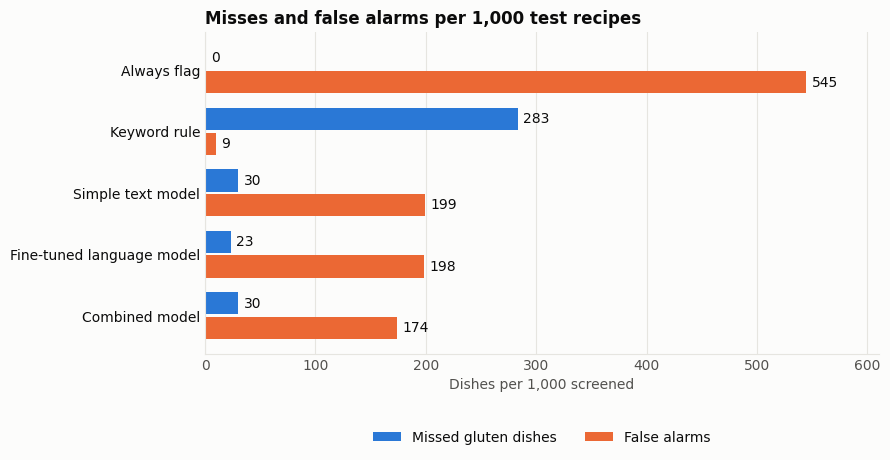

In [67]:
BLUE, ORANGE = "#2a78d6", "#eb6834"
INK, MUTED, GRID, SURFACE = "#0b0b0b", "#52514e", "#e6e5e0", "#fcfcfb"
plt.rcParams.update({"figure.facecolor": SURFACE, "axes.facecolor": SURFACE, "savefig.facecolor": SURFACE,
                     "axes.edgecolor": GRID, "axes.labelcolor": MUTED, "text.color": INK,
                     "xtick.color": MUTED, "ytick.color": MUTED, "font.size": 10,
                     "axes.spines.top": False, "axes.spines.right": False})

def two_bar_chart(table, label_col, title, filename):
    fig, ax = plt.subplots(figsize=(9, 0.8 * len(table) + 0.8))
    y = np.arange(len(table))[::-1]
    b1 = ax.barh(y + 0.2, table["Misses per 1,000"], height=0.36, color=BLUE, label="Missed gluten dishes")
    b2 = ax.barh(y - 0.2, table["False alarms per 1,000"], height=0.36, color=ORANGE, label="False alarms")
    ax.bar_label(b1, fmt="%.0f", padding=4, color=INK)
    ax.bar_label(b2, fmt="%.0f", padding=4, color=INK)
    ax.set_yticks(y)
    ax.set_yticklabels(table[label_col], color=INK)
    ax.set_xlabel("Dishes per 1,000 screened")
    ax.set_xlim(0, table[["Misses per 1,000", "False alarms per 1,000"]].values.max() * 1.12)
    ax.xaxis.grid(True, color=GRID, linewidth=0.8)
    ax.set_axisbelow(True)
    ax.tick_params(length=0)
    ax.legend(frameon=False, loc="upper center", bbox_to_anchor=(0.5, -0.2), ncol=2)
    ax.set_title(title, loc="left", fontweight="bold")
    plt.tight_layout()
    plt.savefig(filename, dpi=200)
    plt.show()

two_bar_chart(recipe_results, "Approach", "Misses and false alarms per 1,000 test recipes", "chart1_recipes.png")

# Part 3. Comparing dish names, photos and both

**Question.** Part 2 used only the dish name. If a dish also has a photo, does the photo help, alone or added to the name?

**Data.** Every Epicurious recipe comes with a photo, so on recipes we can compare the name, the photo and both together on the same dishes.

**What follows from the answer.** Steps 13 to 15 show that the name carries far more information than the photo. Restaurant menus in our test have no photos in any case. So the text approaches are the ones taken on to the restaurant test in Part 4.

## Step 13. A ready-made image network

**Question.** Does a photo of the dish, on its own, reveal anything about gluten?

**Data.** These steps are trained and tested only on recipes with a usable photo.

**What we did.** We used **MobileNetV2**, a free image network that has already learned to recognise objects from over a million everyday photos. We left it frozen. It summarises each photo as 1,280 numbers describing shapes, textures and colours. A small model per ingredient group then learns from those numbers, in the same two-step way as the text model.

Downloading the photos (about 250 MB) and summarising them takes a few minutes.

In [78]:
import torch
from PIL import Image
from torchvision.models import mobilenet_v2, MobileNet_V2_Weights
from torchvision import transforms

device = "cuda" if torch.cuda.is_available() else "cpu"
photo_folder = kagglehub.dataset_download("pes12017000148/food-ingredients-and-recipe-dataset-with-images")
photo_by_name = {os.path.splitext(os.path.basename(p))[0]: p for p in glob.glob(os.path.join(photo_folder, "**", "*.jpg"), recursive=True)}
recipes["photo_path"] = recipes["Image_Name"].map(photo_by_name)

WEIGHTS = MobileNet_V2_Weights.DEFAULT
image_model = mobilenet_v2(weights=WEIGHTS)
image_model.classifier = torch.nn.Identity()
image_model = image_model.eval().to(device)
prepare_photo = WEIGHTS.transforms()

class DishPhotos(torch.utils.data.Dataset):
    def __init__(self, paths):
        self.paths = list(paths)
    def __len__(self):
        return len(self.paths)
    def __getitem__(self, i):
        try:
            return prepare_photo(Image.open(self.paths[i]).convert("RGB")), 1
        except Exception:
            return prepare_photo(Image.new("RGB", (224, 224))), 0

def photo_numbers(paths):
    loader = torch.utils.data.DataLoader(DishPhotos(paths), batch_size=64, num_workers=2)
    rows, readable = [], []
    with torch.no_grad():
        for batch, ok in loader:
            rows.append(image_model(batch.to(device)).cpu().numpy())
            readable.append(ok.numpy())
    return np.vstack(rows), np.concatenate(readable).astype(bool)

with_photo = recipes[recipes["photo_path"].notna()].copy()
P, readable = photo_numbers(with_photo["photo_path"])
with_photo, P = with_photo[readable], P[readable]
is_train, is_valid, is_test = ((with_photo["split"] == s).values for s in ("train", "valid", "test"))
answer = with_photo["gluten"].values

photo_models = {g: make_pipeline(StandardScaler(), LogisticRegression(C=0.001, max_iter=3000)).fit(P[is_train], with_photo.loc[is_train, g]) for g in GROUP_NAMES}
photo_score = gluten_from_groups(pd.DataFrame({g: photo_models[g].predict_proba(P)[:, 1] for g in GROUP_NAMES}))
print(f"Recipes with a usable photo: {len(with_photo)} (training {is_train.sum()}, validation {is_valid.sum()}, test {is_test.sum()})")
print(f"Frozen photo model, ranking score on validation recipes: {ranking_score(answer[is_valid], photo_score[is_valid]):.1f}")

Using Colab cache for faster access to the 'food-ingredients-and-recipe-dataset-with-images' dataset.
Recipes with a usable photo: 13466 (training 9429, validation 2031, test 2006)
Frozen photo model, ranking score on validation recipes: 74.1


## Step 14. Fine-tuning the image network

**Question.** The frozen network was built to recognise everyday objects, not ingredients. Does it do better if we let it adjust to our dish photos?

**What we did.** We fine-tuned MobileNetV2: its last three building blocks (of 19) and a new final layer were trained further on our training photos, so the network could learn what pastry, breading or noodles look like. The learned weights of the earlier blocks, which detect edges and textures, were kept fixed. (A technical detail: those earlier blocks keep running averages of the images they see, and these averages did update during training.)

With about 9,400 training photos there is a risk that the network memorises them instead of learning general patterns. Three guards against that:

1. Only the last three blocks and the final layer are retrained.
2. Each photo is shown slightly altered (cropped, flipped) every time.
3. After each pass through the photos we check the validation photos, keep the best version, and stop when it has not improved for two passes.

This needs the GPU, about five to ten minutes. Without a GPU it is skipped.

**How to read the result:** the ranking score on validation photos after each pass.

In [79]:
photo_ft_ready = False
if device != "cuda":
    print("No GPU, so fine-tuning the image network is skipped.")
else:
    train_look = transforms.Compose([transforms.RandomResizedCrop(224, scale=(0.7, 1.0)), transforms.RandomHorizontalFlip(),
                                     transforms.ToTensor(), transforms.Normalize([0.485, 0.456, 0.406], [0.229, 0.224, 0.225])])

    class LabelledPhotos(torch.utils.data.Dataset):
        def __init__(self, frame, look):
            self.paths = frame["photo_path"].tolist()
            self.labels = frame[GROUP_NAMES].values.astype("float32")
            self.look = look
        def __len__(self):
            return len(self.paths)
        def __getitem__(self, i):
            return self.look(Image.open(self.paths[i]).convert("RGB")), self.labels[i]

    torch.manual_seed(0)
    ft_model = mobilenet_v2(weights=WEIGHTS)
    ft_model.classifier = torch.nn.Sequential(torch.nn.Dropout(0.3), torch.nn.Linear(1280, len(GROUP_NAMES)))
    for p in ft_model.features.parameters():
        p.requires_grad = False
    for block in ft_model.features[-3:]:
        for p in block.parameters():
            p.requires_grad = True
    ft_model = ft_model.to(device)

    photo_optimiser = torch.optim.Adam([{"params": ft_model.classifier.parameters(), "lr": 1e-3},
                                        {"params": [p for b in ft_model.features[-3:] for p in b.parameters()], "lr": 1e-4}])
    photo_loss = torch.nn.BCEWithLogitsLoss()
    train_loader = torch.utils.data.DataLoader(LabelledPhotos(with_photo[is_train], train_look), batch_size=64, shuffle=True, num_workers=2)

    def ft_groups(paths):
        ft_model.eval()
        out = []
        with torch.no_grad():
            for batch, _ in torch.utils.data.DataLoader(DishPhotos(paths), batch_size=128, num_workers=2):
                out.append(torch.sigmoid(ft_model(batch.to(device))).cpu().numpy())
        return pd.DataFrame(np.vstack(out), columns=GROUP_NAMES)

    photo_best, photo_best_state, patience = 0, None, 0
    for a_pass in range(1, 9):
        ft_model.train()
        for photos, labels in train_loader:
            photo_optimiser.zero_grad()
            loss = photo_loss(ft_model(photos.to(device)), labels.to(device))
            loss.backward()
            photo_optimiser.step()
        score = ranking_score(answer[is_valid], gluten_from_groups(ft_groups(with_photo.loc[is_valid, "photo_path"])))
        print(f"Pass {a_pass}: ranking score on validation photos {score:.1f}")
        if score > photo_best:
            photo_best, photo_best_state, patience = score, copy.deepcopy(ft_model.state_dict()), 0
        else:
            patience += 1
            if patience == 2:
                print("No improvement for two passes, so training stops here.")
                break
    ft_model.load_state_dict(photo_best_state)
    photo_ft_score = gluten_from_groups(ft_groups(with_photo["photo_path"]))
    photo_ft_ready = True

Pass 1: ranking score on validation photos 71.0
Pass 2: ranking score on validation photos 72.5
Pass 3: ranking score on validation photos 73.3
Pass 4: ranking score on validation photos 74.0
Pass 5: ranking score on validation photos 74.2
Pass 6: ranking score on validation photos 74.0
Pass 7: ranking score on validation photos 73.8
No improvement for two passes, so training stops here.


## Step 15. Text and photo together, and the photo results

**Question.** Does adding the photo to the dish name beat the dish name alone?

**What we did.** A small final model learns, on the validation recipes, how much weight to give the simple text model's score and how much to give the best photo model's score, and blends them. A weight near zero means that input adds little.

**Comparison.** On the test recipes that have photos: the photo models alone, the simple text model alone, and the blend. The fine-tuned language model and the combined model from Part 2 are shown on the same recipes for reference. All figures in this table, including the text models' figures, are measured on the same recipes with photos, so they differ slightly from Step 12.

**How to read the result.** Compare the ranking scores first: photo alone, name alone, both. Then look at the blend's trade-off. Adding the photo lowers false alarms a little, but it also misses slightly more gluten dishes, so it is not better on every measure.

In [80]:
best_photo = photo_ft_score if photo_ft_ready else photo_score
photo_text = {name: fn(with_photo["Title"]) for name, (fn, _) in MODELS.items()}
blend_inputs = np.column_stack([odds(photo_text["Simple text model"]), odds(best_photo)])
blender = LogisticRegression(max_iter=1000).fit(blend_inputs[is_valid], answer[is_valid])
blend_score = blender.predict_proba(blend_inputs)[:, 1]
print(f"Weight on the dish name: {blender.coef_[0][0]:.2f}.  Weight on the photo: {blender.coef_[0][1]:.2f}")

photo_scores = {"Photo, frozen image network": photo_score}
if photo_ft_ready:
    photo_scores["Photo, fine-tuned image network"] = photo_ft_score
photo_scores["Simple text model"] = photo_text["Simple text model"]
photo_scores["Simple text model and photo, blended"] = blend_score
for name in MODELS:
    if name != "Simple text model":
        photo_scores[name + " (text only, for reference)"] = photo_text[name]
photo_results = pd.DataFrame([summarize(name, (s[is_test] >= cutoff_for_target(s[is_valid], answer[is_valid])).astype(int), answer[is_test], s[is_test])
                              for name, s in photo_scores.items()])
print(f"Test recipes with photos: {is_test.sum()}")
photo_results.style.format(RESULT_FORMAT, na_rep="").hide(axis="index")

Weight on the dish name: 1.12.  Weight on the photo: 0.43
Test recipes with photos: 2006


Approach,Gluten dishes caught,False alarm rate,"Misses per 1,000","False alarms per 1,000",Ranking score (out of 100)
"Photo, frozen image network",94%,74%,27,405,73.5
"Photo, fine-tuned image network",95%,74%,22,404,75.4
Simple text model,93%,37%,30,199,91.1
"Simple text model and photo, blended",93%,32%,32,175,91.7
"Fine-tuned language model (text only, for reference)",95%,36%,23,198,92.6
"Combined model (text only, for reference)",93%,32%,30,173,92.6


# Part 4. The restaurant test

**Question.** Do the text approaches from Part 2 help EatThis recommend a restaurant with more dishes a gluten-avoiding diner can eat?

**Why text only.** The restaurant menus in our test have no photos, so the photo approaches from Part 3 could not be tested here. This does not mean photos lost a restaurant comparison. They were never in one.

**Data.** Nine restaurant chains publish allergen guides that say, for every item, whether it contains wheat. That gives us the right answers. We hide the answers, ask each approach to judge every dish from its name alone, and then compare. No restaurant item was used to train the models in Part 2.

**Comparison.** The same four text approaches as Part 2, on the same dishes, with the cut-offs already set in Step 11.

## Step 16. The restaurant dishes

| Restaurant | Guide used |
|---|---|
| Tatte Bakery & Café | Allergen & Nutritional Information, Fall 2026 |
| Panera Bread | Allergen Guide, valid for 4 November 2026 |
| Boudin Bakery | Master Allergen List, Q4 2026 |
| Pret A Manger (US) | Allergen Guide, November 2026 |
| Così | Ingredient Information for USA Restaurants, 2026 |
| CAVA | Nutrition and Allergen Guide |
| Au Bon Pain | Café Menu guide with allergens, menu last updated October 2017 |
| Sweetgreen | Nutrition page for the Fenway restaurant, read on 11 November 2026 |
| Chipotle (UK) | Allergens and ingredients statement |

Links are in `data/SOURCES.md` in the repository. The Au Bon Pain guide is several years old: its newer menu file (Fall 2022) gives nutrition only and no allergens, so it could not be used as an answer key.

### Which items count as a dish

The guides list everything a kitchen stocks, so each item was given one type by reading its name and the guide's headings. No model score was used.

- **Dish:** a prepared item a diner orders to eat on its own. This includes meals, sandwiches, salads, soups, single pastries and baked goods, and sides eaten on their own such as fries or a fruit cup. **Dishes are what we analyse.**
- **Component:** dressings, sauces, spreads, condiments, toppings, add-ons, proteins chosen for a build-your-own bowl, plain bread and loaves, and packaged snacks. Chipotle's guide lists only ingredients, so all of it falls here and it contributes no dishes.
- **Drink.**
- **Catering or retail pack.**

We extracted and cleaned this list ourselves: stray headings were removed, a few names that wrapped over two lines were repaired, and sizes of the same dish were merged. Every change is recorded in `data/restaurant_item_changes.csv`. The list was not independently reviewed.

**How to read the result:** the number of items of each type at each restaurant.

In [68]:
RESTAURANT_ITEMS = [
    # (restaurant, item name, contains wheat per the guide: 1 yes, 0 no, item type)
    ('Au Bon Pain', 'Asiago Cheese Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Cinnamon Raisin Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Everything Bagel', 1, 'dish'),
    ('Au Bon Pain', 'French Toast Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Honey Sprouted Grain Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Jalapeno Cheddar Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Plain Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Sesame Seed Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Whole Wheat Skinny Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Brownie Bites', 1, 'dish'),
    ('Au Bon Pain', 'Chewy Marshmallow Bar', 0, 'dish'),
    ('Au Bon Pain', 'Chocolate and Crème Torsade', 1, 'dish'),
    ('Au Bon Pain', 'Chocolate Chip Brownie', 1, 'dish'),
    ('Au Bon Pain', 'Chocolate Chip Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Chocolate Dipped Cranberry Almond Coconut Macaroon', 1, 'dish'),
    ('Au Bon Pain', 'Chunky Peanut Butter Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Cinnamon Swirl Roll', 1, 'dish'),
    ('Au Bon Pain', 'Classic Oatmeal Raisin Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Double Chocolate Cupcake', 1, 'dish'),
    ('Au Bon Pain', 'Double Chocolate Mudslide Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Energy Cookie', 1, 'dish'),
    ('Au Bon Pain', 'English Toffee Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Gingerbread Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Gluten Free Chocolate Chip Brownie', 0, 'dish'),
    ('Au Bon Pain', 'Iced Lemon Pound Cake', 1, 'dish'),
    ('Au Bon Pain', 'Marble Pound Cake', 1, 'dish'),
    ('Au Bon Pain', 'Mini Chocolate Chip Cookies', 1, 'dish'),
    ('Au Bon Pain', 'Palmier', 1, 'dish'),
    ('Au Bon Pain', 'Pecan Meltaway', 1, 'dish'),
    ('Au Bon Pain', 'Pecan Roll', 1, 'dish'),
    ('Au Bon Pain', 'Raspberry Filled Shortbread Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Red Velvet Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Red Velvet Cupcake', 1, 'dish'),
    ('Au Bon Pain', 'Shortbread Tree Cookie', 1, 'dish'),
    ('Au Bon Pain', 'White Chocolate Macadamia Cookie', 1, 'dish'),
    ('Au Bon Pain', 'Almond Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Apple and Cinnamon Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Bacon & Cheddar Kolache', 1, 'dish'),
    ('Au Bon Pain', 'Chocolate Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Ham and Cheese Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Plain Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Raspberry Cheese Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Spinach and Cheese Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Sweet Cheese CroisBun', 1, 'dish'),
    ('Au Bon Pain', 'Sweet Cheese Croissant', 1, 'dish'),
    ('Au Bon Pain', 'Apple Danish', 1, 'dish'),
    ('Au Bon Pain', 'Mixed Berry Strudel', 1, 'dish'),
    ('Au Bon Pain', 'Sweet Cheese Danish', 1, 'dish'),
    ('Au Bon Pain', 'Blueberry Muffin', 1, 'dish'),
    ('Au Bon Pain', 'Corn Muffin', 1, 'dish'),
    ('Au Bon Pain', 'Cranberry Orange Muffin', 1, 'dish'),
    ('Au Bon Pain', 'Double Chocolate Chunk Muffin', 1, 'dish'),
    ('Au Bon Pain', 'Raisin Bran Muffin', 1, 'dish'),
    ('Au Bon Pain', 'Berry Pomegranate Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Berry Sensation Yogurt Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Fresh Fruit Smoothie with Bananas, Pineapple and', 0, 'drink'),
    ('Au Bon Pain', 'Fresh Fruit Smoothie with Bananas, Watermelon and', 0, 'drink'),
    ('Au Bon Pain', 'Fresh Fruit Smoothie with Mixed Fruit', 0, 'drink'),
    ('Au Bon Pain', 'Frozen Caramel Latte', 0, 'drink'),
    ('Au Bon Pain', 'Frozen Mocha Latte', 0, 'drink'),
    ('Au Bon Pain', 'Mango Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Mango Wave Fresh Fruit Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'South Beach Yogurt Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Strawberry Banana Yogurt Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Strawberry Passion Fresh Fruit Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Strawberry Smoothie', 0, 'drink'),
    ('Au Bon Pain', 'Butter Pecan Latte', 0, 'drink'),
    ('Au Bon Pain', 'Caffe Americano', 0, 'drink'),
    ('Au Bon Pain', 'Caffe Latte', 0, 'drink'),
    ('Au Bon Pain', 'Caffe Milano', 0, 'drink'),
    ('Au Bon Pain', 'Cappuccino', 0, 'drink'),
    ('Au Bon Pain', 'Caramel Macchiato', 0, 'drink'),
    ('Au Bon Pain', 'Chai Latte', 0, 'drink'),
    ('Au Bon Pain', 'Espresso - Double Shot', 0, 'drink'),
    ('Au Bon Pain', 'Hot Chocolate', 0, 'drink'),
    ('Au Bon Pain', 'Iced Butter Pecan Latte', 0, 'drink'),
    ('Au Bon Pain', 'Iced Caffe Americano', 0, 'drink'),
    ('Au Bon Pain', 'Iced Caffe Latte', 0, 'drink'),
    ('Au Bon Pain', 'Iced Caffe Milano', 0, 'drink'),
    ('Au Bon Pain', 'Iced Caramel Macchiato', 0, 'drink'),
    ('Au Bon Pain', 'Iced Chai Latte', 0, 'drink'),
    ('Au Bon Pain', 'Iced Decaf French Roast Coffee', 0, 'drink'),
    ('Au Bon Pain', 'Iced French Roast Coffee', 0, 'drink'),
    ('Au Bon Pain', 'Iced French Vanilla Coffee', 0, 'drink'),
    ('Au Bon Pain', 'Iced Mocha Latte', 0, 'drink'),
    ('Au Bon Pain', 'Iced Vanilla Latte', 0, 'drink'),
    ('Au Bon Pain', 'Mocha Latte', 0, 'drink'),
    ('Au Bon Pain', 'Vanilla Latte', 0, 'drink'),
    ('Au Bon Pain', 'Vanilla Latte with Sugar Free Syrup', 0, 'drink'),
    ('Au Bon Pain', 'Whipped Cream Topping', 0, 'component'),
    ('Au Bon Pain', 'Caffeine Free Diet Coke', 0, 'drink'),
    ('Au Bon Pain', 'Coke', 0, 'drink'),
    ('Au Bon Pain', 'Coke Zero', 0, 'drink'),
    ('Au Bon Pain', 'Diet Coke', 0, 'drink'),
    ('Au Bon Pain', 'FUZE Raspberry Iced Tea', 0, 'drink'),
    ('Au Bon Pain', 'Homestyle Lemonade', 0, 'drink'),
    ('Au Bon Pain', 'Iced Black Tea', 0, 'drink'),
    ('Au Bon Pain', 'Orange Juice', 0, 'drink'),
    ('Au Bon Pain', 'Peach Iced Tea', 0, 'drink'),
    ('Au Bon Pain', 'PowerAde Mountain Blast', 0, 'drink'),
    ('Au Bon Pain', 'Sprite', 0, 'drink'),
    ('Au Bon Pain', 'Sprite Zero', 0, 'drink'),
    ('Au Bon Pain', 'Strawberry Lemonade', 0, 'drink'),
    ('Au Bon Pain', 'Sweet Tea', 0, 'drink'),
    ('Au Bon Pain', 'Tropical Green Iced Tea', 0, 'drink'),
    ('Au Bon Pain', 'Vitamin Water Zero - Squeezed', 0, 'drink'),
    ('Au Bon Pain', 'Vitamin Water Zero - XXX', 0, 'drink'),
    ('Au Bon Pain', 'Asiago Breadstick', 1, 'component'),
    ('Au Bon Pain', 'Ciabatta', 1, 'component'),
    ('Au Bon Pain', 'Country White Bread', 1, 'component'),
    ('Au Bon Pain', 'Everything Breadstick', 1, 'component'),
    ('Au Bon Pain', 'Multigrain Baguette', 1, 'component'),
    ('Au Bon Pain', 'Rustic Baguette', 1, 'component'),
    ('Au Bon Pain', 'Semolina', 1, 'component'),
    ('Au Bon Pain', 'Sprouted Grain Roll', 1, 'component'),
    ('Au Bon Pain', 'Tortilla Wrap', 1, 'component'),
    ('Au Bon Pain', 'Whole Wheat Tortilla Wrap', 1, 'component'),
    ('Au Bon Pain', 'Egg Whites and Cheddar on Skinny Wheat Bagel', 1, 'dish'),
    ('Au Bon Pain', 'Egg Whites, Cheddar & Avocado on Skinny Wheat Bagel', 1, 'dish'),
    ('Au Bon Pain', 'French Toast Omelet Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Signature Farmhouse Omelet', 1, 'dish'),
    ('Au Bon Pain', 'Smoked Salmon Wasabi', 1, 'dish'),
    ('Au Bon Pain', 'The Good Egg', 1, 'dish'),
    ('Au Bon Pain', 'Avocado BLT', 1, 'dish'),
    ('Au Bon Pain', 'Black Angus Roast Beef and Cheddar', 1, 'dish'),
    ('Au Bon Pain', 'BLT', 1, 'dish'),
    ('Au Bon Pain', 'Herb Chicken Salad Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Tuna Salad Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Turkey and Swiss Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Black Angus Steak and Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Margherita', 1, 'dish'),
    ('Au Bon Pain', 'Classic Grilled Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Country Grilled Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Ham & 2 Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Mayan Chicken Harvest Hot Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Newport Turkey Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Vegetarian Harvest Hot Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Teriyaki Steak Harvest Hot Wrap', 1, 'dish'),
    ('Au Bon Pain', 'The Holiday Gobbler', 1, 'dish'),
    ('Au Bon Pain', 'Chipotle Black Bean Burger with Avocado Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Chipotle Turkey & Avocado', 1, 'dish'),
    ('Au Bon Pain', 'Turkey Club', 1, 'dish'),
    ('Au Bon Pain', 'Two Tomato Caprese', 1, 'dish'),
    ('Au Bon Pain', 'Two Tomato Caprese with Chicken', 1, 'dish'),
    ('Au Bon Pain', 'Warm Chicken Avocado Sandwich', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Caesar Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Garden & Avocado Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Harvest Turkey Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Napa Chicken with Avocado Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Thai Peanut Chicken Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Veggie & Hummus Wrap', 1, 'dish'),
    ('Au Bon Pain', 'Mayan Chicken Harvest Hot Bowl', 0, 'dish'),
    ('Au Bon Pain', 'Mediterranean Chicken Harvest Hot Bowl', 0, 'dish'),
    ('Au Bon Pain', 'Roasted Vegetarian Harvest Hot Bowl', 0, 'dish'),
    ('Au Bon Pain', 'Teriyaki Steak Harvest Hot Bowl', 1, 'dish'),
    ('Au Bon Pain', 'Adobo Chicken', 0, 'dish'),
    ('Au Bon Pain', 'Asian Rice with Edamame & Carrots', 0, 'dish'),
    ('Au Bon Pain', 'Beef & Broccoli', 0, 'dish'),
    ('Au Bon Pain', 'Black Beans & Rice', 0, 'dish'),
    ('Au Bon Pain', 'Broccoli Chicken Pasta Alfredo', 1, 'dish'),
    ('Au Bon Pain', 'Brown Rice', 0, 'dish'),
    ('Au Bon Pain', 'Bruschetta Wings', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Dumplings', 1, 'dish'),
    ('Au Bon Pain', 'Chipotle Wings', 1, 'dish'),
    ('Au Bon Pain', 'Corn Bread', 1, 'dish'),
    ('Au Bon Pain', 'Garlic Bread', 1, 'dish'),
    ('Au Bon Pain', 'Honey & Herb Carrots', 0, 'dish'),
    ('Au Bon Pain', 'Meatballs in Marinara Sauce with Penne', 1, 'dish'),
    ('Au Bon Pain', 'Mediterranean Rice', 0, 'dish'),
    ('Au Bon Pain', 'Pork Carnitas', 0, 'dish'),
    ('Au Bon Pain', 'Pulled BBQ Pork', 0, 'dish'),
    ('Au Bon Pain', 'Red Beans & Rice', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Corn & Jalapenos', 0, 'dish'),
    ('Au Bon Pain', 'Roasted Mediterranean Vegetables', 0, 'dish'),
    ('Au Bon Pain', 'Sesame Green Beans', 0, 'dish'),
    ('Au Bon Pain', 'Smothered Beans', 0, 'dish'),
    ('Au Bon Pain', 'Southwest Wings', 1, 'dish'),
    ('Au Bon Pain', 'Stuffing', 1, 'dish'),
    ('Au Bon Pain', 'Sweet & Sour Wings', 1, 'dish'),
    ('Au Bon Pain', 'Tomato Asiago Rice', 0, 'dish'),
    ('Au Bon Pain', 'Turkey & Gravy', 1, 'dish'),
    ('Au Bon Pain', 'Vegetable Lasagna', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Potatoes', 0, 'dish'),
    ('Au Bon Pain', 'Sausage with Peppers and Onions', 1, 'dish'),
    ('Au Bon Pain', 'Scrambled Eggs', 1, 'dish'),
    ('Au Bon Pain', 'Scrambled Eggs, Ham & Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Warm Apple Bake', 1, 'dish'),
    ('Au Bon Pain', 'Classic Oatmeal', 0, 'dish'),
    ('Au Bon Pain', 'Superfood Cranberry Almond Hot Cereal', 0, 'dish'),
    ('Au Bon Pain', "Baked! Lay's ® Original Potato Crisps", 0, 'component'),
    ('Au Bon Pain', 'Bon To Go - Caprese Chicken', 0, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Cheese & Fruit', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Egg, Veggie & Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Fruit, Eggs & Nuts', 0, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Hard Boiled Eggs', 0, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Herb Chicken Salad', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Hummus', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Hummus, Veggie & Taboule', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Smoked Salmon', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Southwest Chicken', 1, 'dish'),
    ('Au Bon Pain', 'Bon To Go - Turkey & Swiss', 1, 'dish'),
    ('Au Bon Pain', 'Chocolate Covered Almonds', 0, 'component'),
    ('Au Bon Pain', 'Food Should Taste Good ® All Natural Multigrain Chips', 0, 'component'),
    ('Au Bon Pain', 'Fresh Grapes', 0, 'dish'),
    ('Au Bon Pain', 'Fresh Watermelon', 0, 'dish'),
    ('Au Bon Pain', 'Fruit Cup', 0, 'dish'),
    ('Au Bon Pain', 'Housemade Granola', 0, 'dish'),
    ('Au Bon Pain', 'Kettle Cooked BBQ Potato Chips', 0, 'component'),
    ('Au Bon Pain', 'Kettle Cooked Original Potato Chips', 0, 'component'),
    ('Au Bon Pain', 'Kettle Cooked Sea Salt & Vinegar Potato Chips', 0, 'component'),
    ('Au Bon Pain', 'Mixed Nuts', 0, 'component'),
    ('Au Bon Pain', 'Muesli', 0, 'dish'),
    ('Au Bon Pain', 'Skinny Pop® Popcorn', 0, 'component'),
    ('Au Bon Pain', 'Snyder’s of Hanover ® Mini Pretzels', 1, 'component'),
    ('Au Bon Pain', 'Blueberry Yogurt & Wild Blueberry Parfait', 0, 'dish'),
    ('Au Bon Pain', 'Cranberry Crunch & Honey Parfait', 0, 'dish'),
    ('Au Bon Pain', 'Greek Vanilla Yogurt & Wild Blueberry Parfait', 0, 'dish'),
    ('Au Bon Pain', 'Caesar Asiago', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Caesar Asiago', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Cobb with Avocado', 0, 'dish'),
    ('Au Bon Pain', 'Harvest Turkey', 0, 'dish'),
    ('Au Bon Pain', 'Side Garden', 0, 'dish'),
    ('Au Bon Pain', 'Southwest Chicken', 1, 'dish'),
    ('Au Bon Pain', 'Thai Peanut Chicken Salad', 1, 'dish'),
    ('Au Bon Pain', 'Vegetarian Deluxe', 0, 'dish'),
    ('Au Bon Pain', 'ABP Croutons', 1, 'component'),
    ('Au Bon Pain', 'Avocado Greek Yogurt Dressing', 0, 'component'),
    ('Au Bon Pain', 'Balsamic Vinaigrette Dressing', 0, 'component'),
    ('Au Bon Pain', 'Bleu Cheese Dressing', 0, 'component'),
    ('Au Bon Pain', 'Caesar Dressing', 0, 'component'),
    ('Au Bon Pain', 'Lite Buttermilk Ranch Dressing', 0, 'component'),
    ('Au Bon Pain', 'Lite Citrus Lime Vinaigrette', 0, 'component'),
    ('Au Bon Pain', 'Lite Lemon Shallot Vinaigrette', 0, 'component'),
    ('Au Bon Pain', 'Lite Olive Oil Vinaigrette', 0, 'component'),
    ('Au Bon Pain', 'Southwest Vinaigrette', 0, 'component'),
    ('Au Bon Pain', 'Thai Peanut Dressing', 1, 'component'),
    ('Au Bon Pain', 'Asparagus & Pea Soup', 1, 'dish'),
    ('Au Bon Pain', 'Baked Stuffed Potato Soup', 1, 'dish'),
    ('Au Bon Pain', 'Barley and Creamy Lentil Soup', 1, 'dish'),
    ('Au Bon Pain', 'Black Bean Soup', 0, 'dish'),
    ('Au Bon Pain', 'Broccoli Cheddar Soup', 1, 'dish'),
    ('Au Bon Pain', 'Butternut Squash & Apple', 0, 'dish'),
    ('Au Bon Pain', 'Chicken and Dumpling Soup', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Florentine Soup', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Gumbo Soup', 1, 'dish'),
    ('Au Bon Pain', 'Chicken Noodle Soup', 1, 'dish'),
    ('Au Bon Pain', 'Clam Chowder', 1, 'dish'),
    ('Au Bon Pain', 'Corn and Green Chili Bisque', 1, 'dish'),
    ('Au Bon Pain', 'Corn Chowder', 1, 'dish'),
    ('Au Bon Pain', 'Cream of Chicken and Wild Rice Soup', 1, 'dish'),
    ('Au Bon Pain', 'Curried Rice and Lentil Soup', 0, 'dish'),
    ('Au Bon Pain', 'Five Onion Soup', 1, 'dish'),
    ('Au Bon Pain', 'French Moroccan Tomato Lentil Soup', 0, 'dish'),
    ('Au Bon Pain', 'French Onion Soup', 1, 'dish'),
    ('Au Bon Pain', 'Garden Vegetable Soup', 0, 'dish'),
    ('Au Bon Pain', 'Harvest Pumpkin Soup', 1, 'dish'),
    ('Au Bon Pain', 'Italian Wedding Soup', 1, 'dish'),
    ('Au Bon Pain', 'Lemon Orzo Chicken Soup', 1, 'dish'),
    ('Au Bon Pain', 'Lobster & Corn Bisque', 1, 'dish'),
    ('Au Bon Pain', 'Minestrone with Basil', 1, 'dish'),
    ('Au Bon Pain', 'Pasta e Fagioli Soup', 1, 'dish'),
    ('Au Bon Pain', 'Potato Leek Soup', 1, 'dish'),
    ('Au Bon Pain', 'Red Beans, Italian Sausage and Rice Soup', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Eggplant Soup', 0, 'dish'),
    ('Au Bon Pain', 'Roasted Red Pepper & Gouda Soup', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Tomato & Fennel Soup', 0, 'dish'),
    ('Au Bon Pain', 'Roasted Tomato, Chicken & Orzo', 1, 'dish'),
    ('Au Bon Pain', 'Slow Cooked Smokey Chicken & Sausage', 1, 'dish'),
    ('Au Bon Pain', 'Southwest Tortilla Soup', 0, 'dish'),
    ('Au Bon Pain', 'Split Pea with Ham Soup', 1, 'dish'),
    ('Au Bon Pain', 'Swiss Chard and Three Bean Soup', 0, 'dish'),
    ('Au Bon Pain', 'Tomato Basil Bisque', 1, 'dish'),
    ('Au Bon Pain', 'Turkey, Kale & Wild Rice Soup', 1, 'dish'),
    ('Au Bon Pain', 'Tuscan White Bean Soup', 0, 'dish'),
    ('Au Bon Pain', 'Vegetable Beef & Barley', 1, 'dish'),
    ('Au Bon Pain', 'Vegetarian Chili', 0, 'dish'),
    ('Au Bon Pain', 'Vegetarian Minestrone Soup', 1, 'dish'),
    ('Au Bon Pain', 'Wild Mushroom Bisque', 1, 'dish'),
    ('Au Bon Pain', 'Beef and Vegetable Stew', 1, 'dish'),
    ('Au Bon Pain', 'Chicken and Vegetable Stew', 1, 'dish'),
    ('Au Bon Pain', 'Macaroni and Cheese', 1, 'dish'),
    ('Au Bon Pain', 'Roasted Poblano Chicken Stew', 0, 'dish'),
    ('Au Bon Pain', 'Steak & Wild Rice Soup', 0, 'dish'),
    ('Au Bon Pain', 'Turkey Chili', 1, 'dish'),
    ('Boudin', 'BLTA', 1, 'dish'),
    ('Boudin', 'California Veggie', 1, 'dish'),
    ('Boudin', 'Caprese (Vegetarian)', 1, 'dish'),
    ('Boudin', 'Catalan (Vegan)', 1, 'dish'),
    ('Boudin', 'Catalan (Vegetarian)', 1, 'dish'),
    ('Boudin', 'Chicken Salad', 1, 'dish'),
    ('Boudin', 'Crispy Chicken Caesar Wrap', 1, 'dish'),
    ('Boudin', 'Crispy Chicken Parm', 1, 'dish'),
    ('Boudin', 'Deluxe French Dip', 1, 'dish'),
    ('Boudin', 'Grilled Brie with Apples & Fig Jam', 1, 'dish'),
    ('Boudin', 'Hot Chicken Pesto Sandwich', 1, 'dish'),
    ('Boudin', 'Italian Classic', 1, 'dish'),
    ('Boudin', 'Prosciutto & Pestos Sandwich', 1, 'dish'),
    ('Boudin', 'Sourdough French Dip', 1, 'dish'),
    ('Boudin', 'The Great Grilled Cheese', 1, 'dish'),
    ('Boudin', 'The Great with Bacon', 1, 'dish'),
    ('Boudin', 'Toasted Chicken Club', 1, 'dish'),
    ('Boudin', 'Tuna Salad', 1, 'dish'),
    ('Boudin', 'Tuna Melt', 1, 'dish'),
    ('Boudin', 'Turkey and Havarti', 1, 'dish'),
    ('Boudin', 'Turkey Avocado', 1, 'dish'),
    ('Boudin', 'Turkey Cranberry', 1, 'dish'),
    ('Boudin', 'The Classic Ribeye Cheesesteak', 1, 'dish'),
    ('Boudin', 'The Bold Ribeye Cheesesteak', 1, 'dish'),
    ('Boudin', 'Rustic Stuffing Turkey Cranberry', 1, 'dish'),
    ('Boudin', 'Thanksgiving Turkey Melt on Rustic Stuffing Bread', 1, 'dish'),
    ('Boudin', 'Asian Citrus Chicken Salad', 1, 'dish'),
    ('Boudin', 'Chicken, Apple, Walnut Salad', 0, 'dish'),
    ('Boudin', 'Crispy Chicken Avo Salad', 1, 'dish'),
    ('Boudin', 'Little Gem Cobb Salad', 1, 'dish'),
    ('Boudin', 'Mixed Greens (Side Salad)', 1, 'dish'),
    ('Boudin', 'Mixed Greens (Side Salad, No Croutons)', 0, 'dish'),
    ('Boudin', 'Traditional Caesar Salad', 1, 'dish'),
    ('Boudin', 'Add On Grilled All-Natural Chicken Breast', 0, 'component'),
    ('Boudin', 'Add On Crispy Fried Chicken Breast', 1, 'component'),
    ('Boudin', 'Green Goddess Chicken With Avocado Protein Bowl', 0, 'dish'),
    ('Boudin', 'Harvest Chicken Protein Bowl', 0, 'dish'),
    ('Boudin', 'Mediterranean Chicken W/ Lemon Hummus Protein Bowl', 0, 'dish'),
    ('Boudin', 'Broccoli Cheddar', 0, 'dish'),
    ('Boudin', 'Butternut Squash', 0, 'dish'),
    ('Boudin', 'Chili', 0, 'dish'),
    ('Boudin', 'Clam Chowder', 0, 'dish'),
    ('Boudin', 'Rustic Tomato', 1, 'dish'),
    ('Boudin', 'Cheese Pizza', 1, 'dish'),
    ('Boudin', 'Chicken Fingers & French Fries', 1, 'dish'),
    ('Boudin', 'Grilled Cheese', 1, 'dish'),
    ('Boudin', 'Mac & Cheese', 1, 'dish'),
    ('Boudin', 'Turkey Sandwich', 1, 'dish'),
    ('Boudin', 'All Meat', 1, 'dish'),
    ('Boudin', 'Cheesy Garlic Bread', 1, 'dish'),
    ('Boudin', 'Classic Pepperoni', 1, 'dish'),
    ('Boudin', 'Crowd Pleaser (50/50)', 1, 'dish'),
    ('Boudin', 'Four Cheese', 1, 'dish'),
    ('Boudin', 'Hawaiian Pizza', 1, 'dish'),
    ('Boudin', "Papa Steve's Original Style Pizza Bread", 1, 'dish'),
    ('Boudin', 'Sausage & Pepperoni', 1, 'dish'),
    ('Boudin', 'Four Cheese Pinsa Romana', 1, 'dish'),
    ('Boudin', 'Pepperoni Pinsa Romana', 1, 'dish'),
    ('Boudin', 'Prosciutto Bianca Pinsa Romana', 1, 'dish'),
    ('Boudin', 'Sausage & Pepperoni Hot Honey Pinsa Romana', 1, 'dish'),
    ('Boudin', 'Cookies & Cream', 1, 'drink'),
    ('Boudin', 'Dark Chocolate', 0, 'drink'),
    ('Boudin', 'Sea Salt Caramel', 0, 'drink'),
    ('Boudin', 'Strawberry', 0, 'drink'),
    ('Boudin', '*Seasonal* - Pumpkin Spice', 0, 'drink'),
    ('Boudin', 'Asiago Cheese', 1, 'component'),
    ('Boudin', 'Brioche (Buns & Rolls)', 1, 'component'),
    ('Boudin', 'Cinnamon Raisin', 1, 'component'),
    ('Boudin', 'Corn Rye', 1, 'component'),
    ('Boudin', 'English Muffins', 1, 'component'),
    ('Boudin', 'Pinsa Crust - 4 Pack', 1, 'catering or retail pack'),
    ('Boudin', 'Schiacciata Flatbread', 1, 'component'),
    ('Boudin', 'Sourdough (Loaves, Rolls, Baguettes, Lunch Boxes, Critters & Seasonal Shapes)', 1, 'component'),
    ('Boudin', 'Sweet Cinnamon Delight', 1, 'component'),
    ('Boudin', 'Multigrain (Loaves & Lunch Boxes)', 1, 'component'),
    ('Boudin', 'House Fries', 0, 'dish'),
    ('Boudin', 'Spicy Buttermilk Ranch Fries', 0, 'dish'),
    ('Boudin', 'Balsamic Dressing', 0, 'component'),
    ('Boudin', 'Basil Pesto Sauce', 0, 'component'),
    ('Boudin', 'Caesar Dressing', 0, 'component'),
    ('Boudin', 'Calabrian Chili Hot Honey', 0, 'component'),
    ('Boudin', 'Citrus, Garlic, & Herb Caesar Dressing', 0, 'component'),
    ('Boudin', 'Dijon Mustard', 0, 'component'),
    ('Boudin', 'Garlic Aioli Spread', 0, 'component'),
    ('Boudin', 'Honey Mustard', 0, 'component'),
    ('Boudin', 'Horseradish Mayo', 0, 'component'),
    ('Boudin', 'Lemon Hummus Dressing', 0, 'component'),
    ('Boudin', 'Lemon Vinaigrette Dressing', 0, 'component'),
    ('Boudin', 'Mayo', 0, 'component'),
    ('Boudin', 'Pesto Balsamic Dressing', 0, 'component'),
    ('Boudin', 'Pesto Mayo', 0, 'component'),
    ('Boudin', 'Ranch Dressing', 0, 'component'),
    ('Boudin', 'Romesco Sauce', 0, 'component'),
    ('Boudin', 'Spicy Asian Dressing', 1, 'component'),
    ('Boudin', 'Spicy Crema', 0, 'component'),
    ('Boudin', 'Sundried Tomato Spread', 0, 'component'),
    ('Boudin', 'Bacon & Cheddar on English Muffin', 1, 'dish'),
    ('Boudin', 'Cali-Style Bacon Breakfast Burrito', 1, 'dish'),
    ('Boudin', 'Cali-Style Veggie Breakfast Burrito', 1, 'dish'),
    ('Boudin', 'Granola & Greek Yogurt Parfait', 0, 'dish'),
    ('Boudin', 'Ham & Swiss on Croissant', 1, 'dish'),
    ('Boudin', 'Bacon', 0, 'component'),
    ('Boudin', 'Fruit Cup', 0, 'dish'),
    ('Boudin', 'Sourdough Toast', 1, 'component'),
    ('Boudin', 'English Muffin', 1, 'component'),
    ('Boudin', 'Multigrain Toast', 1, 'component'),
    ('Boudin', 'Traditional Deli Feast', 1, 'catering or retail pack'),
    ('Boudin', 'Ultimate Deli Feast', 1, 'catering or retail pack'),
    ('Boudin', 'Duo Salad', 1, 'catering or retail pack'),
    ('Boudin', 'Sausage Frittata Tray', 0, 'catering or retail pack'),
    ('Boudin', 'Vegetarian Frittata Tray', 0, 'catering or retail pack'),
    ('Boudin', 'Vegetarian Frittata Breakfast Sandwich', 1, 'catering or retail pack'),
    ('Boudin', 'Vegan Breakfast Burrito', 1, 'catering or retail pack'),
    ('Boudin', 'Ham & Swiss Breakfast Sandwich on English Muffin', 1, 'catering or retail pack'),
    ('Boudin', 'Egg & Cheddar Breakfast Sandwich on English Muffin', 1, 'catering or retail pack'),
    ('Boudin', 'Chicken & Waffle Breakfast Sandwich', 1, 'catering or retail pack'),
    ('Boudin', 'Oatmeal (Includes condiments)', 0, 'catering or retail pack'),
    ('Boudin', 'Simple Seasoned Eggs', 0, 'catering or retail pack'),
    ('Boudin', 'Avocado Toast Tray', 1, 'catering or retail pack'),
    ('Boudin', 'Bagel - Blueberry', 1, 'dish'),
    ('Boudin', 'Bagel - Cinnamon Raisin', 1, 'dish'),
    ('Boudin', 'Bagel - Onion', 1, 'dish'),
    ('Boudin', 'Bagel - Plain', 1, 'dish'),
    ('Boudin', 'Bagel - Sesame', 1, 'dish'),
    ('Boudin', 'Bar - Cookies & Cream', 1, 'dish'),
    ('Boudin', 'Bar - Double Fudge Brownie', 1, 'dish'),
    ('Boudin', 'Bar - "Gluten Friendly" Raspberry Almond Shortbread', 0, 'dish'),
    ('Boudin', 'Bar - Peanut Butter Crunch', 1, 'dish'),
    ('Boudin', 'Bar - Salted Caramel Pretzel Brownie', 1, 'dish'),
    ('Boudin', 'Chocolate Chip Banana Bread - Loaf & Mini', 1, 'dish'),
    ('Boudin', 'Cookie - Oatmeal Raisin Spice', 1, 'dish'),
    ('Boudin', 'Cookie - Peanut Butter', 1, 'dish'),
    ('Boudin', 'Cookie - Semi-Sweet Chocolate Chip', 1, 'dish'),
    ('Boudin', 'Cookie - Snickerdoodle', 1, 'dish'),
    ('Boudin', 'Cookie - The Royale', 0, 'dish'),
    ('Boudin', 'Cookie - White Chocolate Macadamia Nut', 1, 'dish'),
    ('Boudin', 'Croissant - Almond Lg. & Mini (NorCal & SoCal)', 1, 'dish'),
    ('Boudin', 'Croissant - Butter Lg. & Mini (NorCal & SoCal)', 1, 'dish'),
    ('Boudin', 'Croissant - Chocolate Lg. & Mini (NorCal & SoCal)', 1, 'dish'),
    ('Boudin', 'Loaf - Banana Pecan', 1, 'dish'),
    ('Boudin', 'Loaf - Marble Chocolate Chip', 1, 'dish'),
    ('Boudin', 'Loaf - Seasonal Pumpkin Swirl', 1, 'dish'),
    ('Boudin', 'Mini Coffee Cake', 1, 'dish'),
    ('Boudin', 'Morning Bun Lg. & Mini', 1, 'dish'),
    ('Boudin', 'Muffin - Banana Walnut', 1, 'dish'),
    ('Boudin', 'Muffin - Blueberry', 1, 'dish'),
    ('Boudin', 'Muffin - Iced Lemon Poppyseed', 1, 'dish'),
    ('Boudin', 'Scone - Artisan Blueberry', 1, 'dish'),
    ('Boudin', 'Scone - Artisan Cinnamon', 1, 'dish'),
    ('Boudin', 'Fruits & Cheese Tray', 1, 'catering or retail pack'),
    ('Boudin', 'California Vegetable Tray', 0, 'catering or retail pack'),
    ('Boudin', 'Antipasti', 1, 'dish'),
    ('Boudin', 'Ham & Swiss', 1, 'catering or retail pack'),
    ('Boudin', 'Pesto Roast Beef', 1, 'catering or retail pack'),
    ('Boudin', 'Roast Beef & Cheddar', 1, 'catering or retail pack'),
    ('Boudin', 'Catering Pesto Chicken', 1, 'catering or retail pack'),
    ('Boudin', '*Sandwiches Prepared on Gluten Free Bread', 0, 'catering or retail pack'),
    ('Boudin', 'Mini California Veggie', 1, 'catering or retail pack'),
    ('Boudin', 'Mini Chicken Salad', 1, 'catering or retail pack'),
    ('Boudin', 'Mini Ham & Swiss', 1, 'catering or retail pack'),
    ('Boudin', 'Mini Italiano', 1, 'catering or retail pack'),
    ('Boudin', 'Mini Roast Beef & Cheddar', 1, 'catering or retail pack'),
    ('Boudin', 'Mini Turkey Havarti', 1, 'catering or retail pack'),
    ('CAVA', 'Greek Goddess Steak Salad', 0, 'dish'),
    ('CAVA', 'Greek Goddess Salmon Bowl', 0, 'dish'),
    ('CAVA', 'Spicy Lamb + Avocado Bowl', 0, 'dish'),
    ('CAVA', 'Steak + Harissa Bowl', 0, 'dish'),
    ('CAVA', 'Harissa Avocado Bowl', 0, 'dish'),
    ('CAVA', 'Chicken + Rice Bowl', 0, 'dish'),
    ('CAVA', 'Greek Salad Bowl', 0, 'dish'),
    ('CAVA', 'Falafel Crunch Bowl', 1, 'dish'),
    ('CAVA', 'Salmon + Yogurt Dill Bowl', 0, 'dish'),
    ('CAVA', 'Pomegranate Glazed Salmon Bowl', 0, 'dish'),
    ('CAVA', 'Spicy Chicken + Avocado Pita', 1, 'dish'),
    ('CAVA', 'Steak + Feta Pita', 1, 'dish'),
    ('CAVA', 'Greek Chicken Pita', 1, 'dish'),
    ('CAVA', 'Brown Rice', 0, 'component'),
    ('CAVA', 'Saffron Basmati Rice', 0, 'component'),
    ('CAVA', 'Black Lentils', 0, 'component'),
    ('CAVA', 'Super Greens', 0, 'component'),
    ('CAVA', 'Arugula', 0, 'component'),
    ('CAVA', 'Baby Spinach', 0, 'component'),
    ('CAVA', 'Romaine', 0, 'component'),
    ('CAVA', 'Power Greens', 0, 'component'),
    ('CAVA', 'Braised Lamb', 0, 'component'),
    ('CAVA', 'Grilled Chicken', 0, 'component'),
    ('CAVA', 'Falafel', 1, 'component'),
    ('CAVA', 'Grilled Steak', 0, 'component'),
    ('CAVA', 'Harissa Honey Chicken', 0, 'component'),
    ('CAVA', 'Roasted Vegetables', 0, 'component'),
    ('CAVA', 'Spicy Lamb Meatballs', 0, 'component'),
    ('CAVA', 'Glazed Salmon', 0, 'component'),
    ('CAVA', 'Kids Saffron Basmati Rice', 0, 'component'),
    ('CAVA', 'Kids Brown Rice', 0, 'component'),
    ('CAVA', 'Kids Black Lentils', 0, 'component'),
    ('CAVA', 'Kids Chicken', 0, 'component'),
    ('CAVA', 'Kids Harissa Honey Chicken', 0, 'component'),
    ('CAVA', 'Kids Falafel', 1, 'component'),
    ('CAVA', 'Kids Spicy Lamb Meatballs', 0, 'component'),
    ('CAVA', 'Kids Roasted Vegetables', 0, 'component'),
    ('CAVA', 'Kids Braised Lamb', 0, 'component'),
    ('CAVA', 'Kids Grilled Steak', 0, 'component'),
    ('CAVA', 'Kids Pita Chips', 1, 'component'),
    ('CAVA', 'Shredded Romaine', 0, 'component'),
    ('CAVA', 'Pita Crisps', 1, 'component'),
    ('CAVA', 'Sumac Cabbage Slaw', 0, 'component'),
    ('CAVA', 'Tomato + Onion', 0, 'component'),
    ('CAVA', 'Persian Cucumber', 0, 'component'),
    ('CAVA', 'Tomato + Cucumber', 0, 'component'),
    ('CAVA', 'Kalamata Olives', 0, 'component'),
    ('CAVA', 'Fiery Broccoli', 0, 'component'),
    ('CAVA', 'Pickled Onions', 0, 'component'),
    ('CAVA', 'Salt-Brined Pickles', 0, 'component'),
    ('CAVA', 'Crumbled Feta', 0, 'component'),
    ('CAVA', 'Fire-Roasted Corn', 0, 'component'),
    ('CAVA', 'Avocado', 0, 'component'),
    ('CAVA', 'Tzatziki', 0, 'component'),
    ('CAVA', 'Hummus', 0, 'component'),
    ('CAVA', 'Roasted Eggplant', 0, 'component'),
    ('CAVA', 'Crazy Feta®', 0, 'component'),
    ('CAVA', 'Harissa', 0, 'component'),
    ('CAVA', 'Red Pepper Hummus', 0, 'component'),
    ('CAVA', 'Greek Goddess', 0, 'component'),
    ('CAVA', 'Balsamic Date Vinaigrette', 0, 'component'),
    ('CAVA', 'Yogurt Dill', 0, 'component'),
    ('CAVA', 'Lemon Herb Tahini', 0, 'component'),
    ('CAVA', 'Greek Vinaigrette', 0, 'component'),
    ('CAVA', 'Skhug', 0, 'component'),
    ('CAVA', 'Hot Harissa Vinaigrette', 0, 'component'),
    ('CAVA', 'Garlic Dressing', 0, 'component'),
    ('CAVA', 'Side Pita', 1, 'component'),
    ('CAVA', 'Pita Chips', 1, 'component'),
    ('CAVA', 'Harissa BBQ Pita Chips', 1, 'component'),
    ('CAVA', 'Greyston Chocolate Chip Blondie', 1, 'dish'),
    ('CAVA', 'Greyston Brownie', 1, 'dish'),
    ('CAVA', 'Whisked! Apricot Honey (DMV)', 1, 'dish'),
    ('CAVA', 'Whisked! Salted Dark Chocolate Oat Cookie', 1, 'dish'),
    ('CAVA', 'Classic Lemonade', 0, 'drink'),
    ('CAVA', 'Classic Lemonade (CA)', 0, 'drink'),
    ('CAVA', 'Pomegranate Apple', 0, 'drink'),
    ('CAVA', 'Unsweetened Black Tea', 0, 'drink'),
    ('CAVA', 'Sweet Tea', 0, 'drink'),
    ('CAVA', 'Jasmine Green Tea', 0, 'drink'),
    ('CAVA', 'Cucumber Mint Lime', 0, 'drink'),
    ('CAVA', 'Blueberry Lavender', 0, 'drink'),
    ('CAVA', 'Maine Root Soda (Fountain)', 0, 'drink'),
    ('CAVA', 'Maine Root Soda (Bottled)', 0, 'drink'),
    ('CAVA', 'Spindrift Grapefruit', 0, 'drink'),
    ('CAVA', 'Spindrift Raspberry Lime', 0, 'drink'),
    ('CAVA', 'Spindrift Lemon', 0, 'drink'),
    ('CAVA', 'Spindrift Half Tea + Half Lemon', 0, 'drink'),
    ('CAVA', 'Chocolate Milk', 0, 'drink'),
    ('CAVA', '1% Milk', 0, 'drink'),
    ('CAVA', 'Honest Apple Juice', 0, 'drink'),
    ('Chipotle (UK)', 'Soft Flour Tortilla (Burrito & Taco)', 1, 'component'),
    ('Chipotle (UK)', 'Hard Shell Taco (Crispy Corn Taco)', 0, 'component'),
    ('Chipotle (UK)', 'Coriander-Lime Rice (White)', 0, 'component'),
    ('Chipotle (UK)', 'Coriander-Lime Rice (Brown)', 0, 'component'),
    ('Chipotle (UK)', 'Beans (Black)', 0, 'component'),
    ('Chipotle (UK)', 'Beans (Pinto)', 0, 'component'),
    ('Chipotle (UK)', 'Fajita Vegetables', 0, 'component'),
    ('Chipotle (UK)', 'Barbacoa', 0, 'component'),
    ('Chipotle (UK)', 'Carnitas', 0, 'component'),
    ('Chipotle (UK)', 'Steak', 0, 'component'),
    ('Chipotle (UK)', 'Sofritas (braised tofu)', 0, 'component'),
    ('Chipotle (UK)', 'Fresh Tomato Salsa', 0, 'component'),
    ('Chipotle (UK)', 'Chilli-Corn Salsa', 0, 'component'),
    ('Chipotle (UK)', 'Roasted Tomato Green-Chilli Salsa', 0, 'component'),
    ('Chipotle (UK)', 'Roasted Tomato Red-Chilli Salsa', 0, 'component'),
    ('Chipotle (UK)', 'Monterey Jack Cheese', 0, 'component'),
    ('Chipotle (UK)', 'Sour Cream', 0, 'component'),
    ('Chipotle (UK)', 'Guacamole', 0, 'component'),
    ('Chipotle (UK)', 'Romaine Lettuce', 0, 'component'),
    ('Chipotle (UK)', 'Tortilla Chips', 0, 'component'),
    ('Chipotle (UK)', 'Chipotle Honey Vinaigrette', 0, 'component'),
    ('Chipotle (UK)', 'Tabasco®', 0, 'component'),
    ('Cosi', 'Bowl, Adobo Chicken with Avocado', 0, 'dish'),
    ('Cosi', 'Bowl, Spicy Meatless Chorizo', 1, 'dish'),
    ('Cosi', 'Bowl, Shanghai Chicken', 1, 'dish'),
    ('Cosi', 'Bowl, Falafel & Harissa Hummus', 1, 'dish'),
    ('Cosi', 'Orange Juice, Large', 0, 'drink'),
    ('Cosi', 'Hard Boiled Eggs', 0, 'dish'),
    ('Cosi', 'Fruit Cup', 0, 'dish'),
    ('Cosi', 'Bagel, Asiago (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Jalepeno (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Multi-Grain (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Plain (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Cinnamon Raisin (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Seasame (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Everything (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bagel, Poppy (Just Bagels)', 1, 'dish'),
    ('Cosi', 'Bread Slice, Original* (Corporate)', 1, 'component'),
    ('Cosi', 'Bread Slice, Multi Grain* (Corporate)', 1, 'component'),
    ('Cosi', 'Bread Slice, Original* (Franchisee)', 1, 'component'),
    ('Cosi', 'Bread Slice, Multi Grain* (Franchisee)', 1, 'component'),
    ('Cosi', 'Croissant, Butter*', 1, 'dish'),
    ('Cosi', 'Crumb Cake, Butter*', 1, 'dish'),
    ('Cosi', 'Loaf, Lemon Pound Cake*', 1, 'dish'),
    ('Cosi', 'Loaf, Marble Pound Cake*', 1, 'dish'),
    ('Cosi', 'Muffin, Blueberry', 1, 'dish'),
    ('Cosi', 'Muffin, Lemon Cranberry', 1, 'dish'),
    ('Cosi', 'Muffin, Double Chocolate Chip', 1, 'dish'),
    ('Cosi', 'Muffin, Apple Cinnamon', 1, 'dish'),
    ('Cosi', 'Scone, Blueberry*', 1, 'dish'),
    ('Cosi', 'Scone, Orange Cranberry*', 1, 'dish'),
    ('Cosi', 'Cream Cheese, Low-fat', 0, 'component'),
    ('Cosi', 'Cream Cheese, Plain', 0, 'component'),
    ('Cosi', 'Cream Cheese, Veggie', 0, 'component'),
    ('Cosi', 'Brownie Bites, Blondie', 1, 'dish'),
    ('Cosi', 'Brownie Bites, Chocolate Chunk*', 1, 'dish'),
    ('Cosi', 'Brownie, Blondie*', 1, 'dish'),
    ('Cosi', 'Brownie, Chocolate Chunk*', 1, 'dish'),
    ('Cosi', 'Cookie, Chocolate Chip*', 1, 'dish'),
    ('Cosi', 'Blueberry Smash Lemonade', 0, 'drink'),
    ('Cosi', 'Iced Tea', 0, 'drink'),
    ('Cosi', 'Iced Tea, Raspberry', 0, 'drink'),
    ('Cosi', 'Lemonade', 0, 'drink'),
    ('Cosi', 'Mojito Lemonade', 0, 'drink'),
    ('Cosi', 'Café Americano', 0, 'drink'),
    ('Cosi', 'Cappuccino', 0, 'drink'),
    ('Cosi', 'Caramel Latte', 0, 'drink'),
    ('Cosi', 'Chai Tea Latte', 0, 'drink'),
    ('Cosi', 'Coffee', 0, 'drink'),
    ('Cosi', 'Espresso', 0, 'drink'),
    ('Cosi', 'Hot Chocolate', 0, 'drink'),
    ('Cosi', 'Latte', 0, 'drink'),
    ('Cosi', 'Mocha', 0, 'drink'),
    ('Cosi', 'Shot in the Dark', 0, 'drink'),
    ('Cosi', 'White Hot Chocolate', 0, 'drink'),
    ('Cosi', 'Cheese', 1, 'dish'),
    ('Cosi', 'Margherita Chicken', 1, 'dish'),
    ('Cosi', 'Margherita', 1, 'dish'),
    ('Cosi', 'Pepperoni', 1, 'dish'),
    ('Cosi', 'Kids Flatbread Cheese Pizza', 1, 'dish'),
    ('Cosi', 'Kids Flatbread Pepperoni Pizza', 1, 'dish'),
    ('Cosi', 'Kids Grape Cup', 0, 'dish'),
    ('Cosi', 'Kids Grilled Cheese', 1, 'dish'),
    ('Cosi', 'Kids Ham & Cheese', 1, 'dish'),
    ('Cosi', 'Kids Mac & Cheese', 1, 'dish'),
    ('Cosi', 'Kids Peanut Butter & Jelly', 1, 'dish'),
    ('Cosi', 'Kids Turkey Sandwich', 1, 'dish'),
    ('Cosi', 'Roasted Chicken', 0, 'component'),
    ('Cosi', 'Turkey', 0, 'component'),
    ('Cosi', 'Tofu', 0, 'component'),
    ('Cosi', 'Tuna Salad', 0, 'component'),
    ('Cosi', 'Southwest Adobo Chicken', 0, 'dish'),
    ('Cosi', 'Caesar', 1, 'dish'),
    ('Cosi', 'Caesar - Chicken', 1, 'dish'),
    ('Cosi', 'Cobb', 0, 'dish'),
    ('Cosi', 'Mediterranean Salad', 0, 'dish'),
    ('Cosi', 'Mandarin Chicken', 1, 'dish'),
    ('Cosi', 'Signature', 0, 'dish'),
    ('Cosi', 'Salad Dressing (Portion Only)', 0, 'component'),
    ('Cosi', 'Dressing - Adobo Vinaigrette', 0, 'component'),
    ('Cosi', 'Dressing - Caesar', 0, 'component'),
    ('Cosi', 'Dressing - Ginger Sesame', 1, 'component'),
    ('Cosi', 'Dressing - Cosi® Vinaigrette (Balsamic Vinaigrette)', 0, 'component'),
    ('Cosi', 'Dressing - Green Goddess', 0, 'component'),
    ('Cosi', 'Dressing - Sherry Shallot', 0, 'component'),
    ('Cosi', 'Bacon Turkey Cheddar', 1, 'dish'),
    ('Cosi', 'Pesto Chicken Melt', 1, 'dish'),
    ('Cosi', 'Fiery Chipotle Chicken Melt', 1, 'dish'),
    ('Cosi', 'Buffalo Chicken', 1, 'dish'),
    ('Cosi', 'Old World Italiano', 1, 'dish'),
    ('Cosi', 'Chicken Noodle', 1, 'dish'),
    ('Cosi', 'Fire Roasted Vegetable', 0, 'dish'),
    ('Cosi', 'French Onion Soup', 1, 'dish'),
    ('Cosi', 'Italian Wedding Soup', 1, 'dish'),
    ('Cosi', 'Macaroni & Cheese', 1, 'dish'),
    ('Cosi', 'Mediterranean Lentil', 0, 'dish'),
    ('Cosi', 'New England Clam Chowder', 0, 'dish'),
    ('Cosi', 'Turkey Chili', 1, 'dish'),
    ('Cosi', 'Tomato Basil', 0, 'dish'),
    ('Cosi', 'Chicken & Dumpling', 1, 'dish'),
    ('Panera', 'Asiago Cheese', 1, 'dish'),
    ('Panera', 'Asiago Everything', 1, 'dish'),
    ('Panera', 'Blueberry', 1, 'dish'),
    ('Panera', 'Chocolate Chip', 1, 'dish'),
    ('Panera', 'Cinnamon Crunch', 1, 'dish'),
    ('Panera', 'Cinnamon Swirl & Raisin', 1, 'dish'),
    ('Panera', 'Everything', 1, 'dish'),
    ('Panera', 'Multigrain Bagel Flat', 1, 'dish'),
    ('Panera', 'Plain', 1, 'dish'),
    ('Panera', 'Sesame', 1, 'dish'),
    ('Panera', 'Plain Cream Cheese Spread', 0, 'component'),
    ('Panera', 'Honey Walnut Cream Cheese Spread', 0, 'component'),
    ('Panera', 'Honey Pecan Cream Cheese Spread', 0, 'component'),
    ('Panera', 'Artisan Ciabatta- Loaf', 1, 'component'),
    ('Panera', 'Black Pepper Focaccia - Round Loaf', 1, 'component'),
    ('Panera', 'Classic White - Loaf', 1, 'component'),
    ('Panera', 'Country Rustic Sourdough - XL Loaf', 1, 'component'),
    ('Panera', 'Croissant', 1, 'dish'),
    ('Panera', 'French Baguette', 1, 'component'),
    ('Panera', 'Sourdough Bread Bowl', 1, 'component'),
    ('Panera', 'Tomato Basil - Miche', 1, 'component'),
    ('Panera', 'Whole Grain Lahvash Wrap', 1, 'component'),
    ('Panera', 'Italian Stuffer Roll - Retail whole', 1, 'component'),
    ('Panera', 'Brownie', 1, 'dish'),
    ('Panera', 'Cookie- Candy', 1, 'dish'),
    ('Panera', 'Cookie- Chocolate Chipper (Large & Petites)', 1, 'dish'),
    ('Panera', 'Cookie - Chocolate Coconut Macaroon', 1, 'dish'),
    ('Panera', 'Cookie - Coconut Macaroon', 1, 'dish'),
    ('Panera', 'Cookie - Dubai Style Chocolate Pistachio', 1, 'dish'),
    ('Panera', 'Cookie- Iced Shaped Shortbread- Pumpkin & Mitten', 1, 'dish'),
    ('Panera', 'Cookie- Kitchen Sink', 1, 'dish'),
    ('Panera', 'Cookie- Oatmeal Raisin with Berries', 1, 'dish'),
    ('Panera', 'Pastry - Cranberry Orange Loaf Slice - Naturally Flavored', 1, 'dish'),
    ('Panera', 'Muffin- Blueberry', 1, 'dish'),
    ('Panera', 'Muffie- Chocolate Chip', 1, 'dish'),
    ('Panera', 'Pastry - Almond', 1, 'dish'),
    ('Panera', 'Pastry - Asiago Croissant Twists', 1, 'dish'),
    ('Panera', 'Pastry - Cherry', 1, 'dish'),
    ('Panera', 'Pastry- Chocolate Croissant', 1, 'dish'),
    ('Panera', 'Pastry- Cinnamon Roll', 1, 'dish'),
    ('Panera', 'Pastry - Pumpkin Spice Cinnamon Roll', 1, 'dish'),
    ('Panera', 'Pastry- Pecan Braid', 1, 'dish'),
    ('Panera', 'Scone- Orange (Large & Mini)', 1, 'dish'),
    ('Panera', 'Cookie - PB & J', 1, 'dish'),
    ('Panera', 'Pastry - Cinnamon Croissant Bites with White Icing', 1, 'dish'),
    ('Panera', 'Add on - White Icing Portion Cup', 0, 'component'),
    ('Panera', 'Pastry - Cocoa Marshmallow Flavored Cake Slice', 1, 'dish'),
    ('Panera', 'Asiago Everything Bagel Stack - Wake-up BLT', 1, 'dish'),
    ('Panera', 'Asiago Bagel Stack - Farmhouse Duo', 1, 'dish'),
    ('Panera', 'Bacon, Egg & Cheese on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Bacon, Egg & Cheese on Croissant', 1, 'dish'),
    ('Panera', 'Bacon Double Take on Black Pepper Focaccia', 1, 'dish'),
    ('Panera', 'Chipotle Chicken, Egg & Avo on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Egg & Cheese on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Egg & Cheese on Croissant', 1, 'dish'),
    ('Panera', 'Egg Styles - Scrambled Egg or Egg White', 0, 'component'),
    ('Panera', 'Garden Avo & Egg White on Multigrain Bagel Flat', 1, 'dish'),
    ('Panera', 'Ham Croissant Benny', 1, 'dish'),
    ('Panera', 'Ham, Egg & Cheese on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Sausage, Egg & Cheese on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Sausage, Egg & Cheese on Croissant', 1, 'dish'),
    ('Panera', 'Steak & Wake on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Four Cheese Souffle', 1, 'dish'),
    ('Panera', 'Spinach & Bacon Souffle', 1, 'dish'),
    ('Panera', 'Fruit Cup', 0, 'dish'),
    ('Panera', 'Hard Boiled Eggs', 0, 'dish'),
    ('Panera', 'Parfait- Greek Yogurt with Berries', 0, 'dish'),
    ('Panera', 'Steel Cut Oatmeal with Strawberries & Pecans', 0, 'dish'),
    ('Panera', 'Steel Cut Oatmeal with Strawberries - Without Pecans', 0, 'dish'),
    ('Panera', 'Asian Sesame with & without Chicken', 1, 'dish'),
    ('Panera', 'Stuffer - Asian Sesame with & without Chicken', 1, 'dish'),
    ('Panera', 'Asian Sesame with & without Chicken - Without Almonds', 1, 'dish'),
    ('Panera', 'Stuffer - Asian Sesame with & without Chicken - without Almonds', 1, 'dish'),
    ('Panera', 'Caesar with & without Chicken', 1, 'dish'),
    ('Panera', 'Stuffer - Caesar with & without Chicken', 1, 'dish'),
    ('Panera', 'Stuffer - Farmhouse Crunch', 1, 'dish'),
    ('Panera', 'Farmhouse Crunch Salad - without almonds', 0, 'dish'),
    ('Panera', 'Stuffer - Farmhouse Crunch - without almonds', 1, 'dish'),
    ('Panera', 'Fuji Apple with & without Chicken', 0, 'dish'),
    ('Panera', 'Stuffer - Fuji Apple with & without Chicken', 1, 'dish'),
    ('Panera', 'Fuji Apple with & without Chicken - Without Pecans', 0, 'dish'),
    ('Panera', 'Stuffer - Fuji Apple with & without Chicken - without Pecans', 1, 'dish'),
    ('Panera', 'Greek with & without Chicken', 0, 'dish'),
    ('Panera', 'Stuffer - Greek with & without Chicken', 1, 'dish'),
    ('Panera', 'Green Goddess Cobb with Chicken', 0, 'dish'),
    ('Panera', 'Stuffer - Green Goddess Cobb with Chicken', 1, 'dish'),
    ('Panera', 'Ranch Parm BLT', 1, 'dish'),
    ('Panera', 'Stuffer - Ranch Parm BLT', 1, 'dish'),
    ('Panera', 'Southwest Chicken Ranch', 0, 'dish'),
    ('Panera', 'Stuffer - Southwest Chicken Ranch', 1, 'dish'),
    ('Panera', 'Ultimate Garden Steak Salad', 1, 'dish'),
    ('Panera', 'Stuffer - Ultimate Garden Steak', 1, 'dish'),
    ('Panera', 'Harvest Medley with and without Chicken', 1, 'dish'),
    ('Panera', 'Stuffer- Harvest Medley with and without Chicken', 1, 'dish'),
    ('Panera', 'Harvest Medley with and without Chicken - No Pecans', 1, 'dish'),
    ('Panera', 'Stuffer- Harvest Medley with and without Chicken - No Pecans', 1, 'dish'),
    ('Panera', 'All-In Veggie', 1, 'dish'),
    ('Panera', 'Sesame Ginger Chicken', 1, 'dish'),
    ('Panera', 'Sesame Ginger Chicken - No Almonds', 1, 'dish'),
    ('Panera', 'Carnitas Elote', 0, 'dish'),
    ('Panera', 'Asiago Bagel Stack - Spicy Steak', 1, 'dish'),
    ('Panera', 'Bacon Turkey Bravo on Tomato Basil', 1, 'dish'),
    ('Panera', 'Chicken Bacon Rancher on Black Pepper Focaccia', 1, 'dish'),
    ('Panera', 'Chipotle Chicken Avo Melt on Round Black Pepper Focaccia', 1, 'dish'),
    ('Panera', 'Ciabatta Cheesesteak', 1, 'dish'),
    ('Panera', 'Cranberry Walnut Chicken Salad on Country Rustic', 1, 'dish'),
    ('Panera', 'Grilled Cheese on Classic White Loaf', 1, 'dish'),
    ('Panera', 'Grilled Chicken & Avo BLT on Country Rustic Sourdough', 1, 'dish'),
    ('Panera', 'Mediterranean Veggie on Tomato Basil', 1, 'dish'),
    ('Panera', 'Pickle Spear for cold sandwiches', 0, 'component'),
    ('Panera', 'Smokehouse BBQ Chicken on Artisan Ciabatta', 1, 'dish'),
    ('Panera', 'Toasted Frontega Chicken on Black Pepper Focaccia', 1, 'dish'),
    ('Panera', 'Toasted Italiano on Baguette', 1, 'dish'),
    ('Panera', 'Tomato Basil BLT on Tomato Basil Miche', 1, 'dish'),
    ('Panera', 'Toasted Caprese Focaccia', 1, 'dish'),
    ('Panera', 'Tuna Salad on Country Rustic Sourdough', 1, 'dish'),
    ('Panera', 'Turkey & Cheddar on Country Rustic Sourdough', 1, 'dish'),
    ('Panera', 'Spicy Fiesta Chicken on Ciabatta', 1, 'dish'),
    ('Panera', 'Catering- Ham & Cheddar on Country Rustic', 1, 'catering or retail pack'),
    ('Panera', 'Ciabatta Dipper - French', 1, 'dish'),
    ('Panera', 'Ciabatta Dipper - Chicken Pesto', 1, 'dish'),
    ('Panera', 'Dressing - Asian Sesame vinaigrette', 0, 'component'),
    ('Panera', 'Sauce - Balsamic Glaze', 0, 'component'),
    ('Panera', 'Sauce - Balsamic Vinaigrette', 0, 'component'),
    ('Panera', 'Sauce - Bravo Signature', 0, 'component'),
    ('Panera', 'Dressing - Caesar', 0, 'component'),
    ('Panera', 'Sauce - Cheese Hollandaise', 0, 'component'),
    ('Panera', 'Sauce - Chipotle Aioli', 0, 'component'),
    ('Panera', 'Dressing - Creamy Garden Herb', 0, 'component'),
    ('Panera', 'Sauce - Creamy Basil Pesto', 0, 'component'),
    ('Panera', 'Dressing - Farmhouse Ranch', 0, 'component'),
    ('Panera', 'Sauce - Garlic Aioli', 0, 'component'),
    ('Panera', 'Dressing - Greek', 0, 'component'),
    ('Panera', 'Sauce - Green Chile Salsa Verde', 0, 'component'),
    ('Panera', 'Dressing - Green Goddess', 0, 'component'),
    ('Panera', 'Spread- Hummus', 0, 'component'),
    ('Panera', 'Sauce - Mayonnaise', 0, 'component'),
    ('Panera', 'Dressing - Sesame Ginger', 1, 'component'),
    ('Panera', 'Dressing - White Balsamic Apple Flavored Vinaigrette', 0, 'component'),
    ('Panera', 'Dressing - Zesty Smoky Lemon Vinaigrette', 1, 'component'),
    ('Panera', 'Dipper - Creamy Tomato - Dipper Portion', 0, 'component'),
    ('Panera', 'Dipper - Bistro French Onion - Dipper Portion', 1, 'component'),
    ('Panera', 'Additional Pump of Caramel Syrup', 0, 'component'),
    ('Panera', 'Additional Pump of Chocolate Sauce', 0, 'component'),
    ('Panera', 'Additional Pump of Chocolatey Hazelnut Flavored Syrup', 0, 'component'),
    ('Panera', 'Additional Pump of Madagascar Vanilla Syrup or Cane Sugar Syrup', 0, 'component'),
    ('Panera', 'Additional Shot of Pumpkin Spice Sauce', 0, 'component'),
    ('Panera', 'Additional Pump of Snickerdoodle Syrup', 0, 'component'),
    ('Panera', 'Additional Pump of White Chocolate and Peppermint Flavored Sauce', 0, 'component'),
    ('Panera', 'Additional Pump of White Chocolate and Pistachio Flavored Sauce', 0, 'component'),
    ('Panera', 'Agave Lemonade', 0, 'drink'),
    ('Panera', 'Americano', 0, 'drink'),
    ('Panera', 'Blackberry Hibiscus Iced Tea - Naturally Flavored Herbal Tea', 0, 'drink'),
    ('Panera', 'Cafe Frozen Java', 0, 'drink'),
    ('Panera', 'Caffe Latte (espresso - Hot or Iced)', 0, 'drink'),
    ('Panera', 'Cappuccino (espresso)', 0, 'drink'),
    ('Panera', 'Caramel Latte (espresso - Hot or Iced)', 0, 'drink'),
    ('Panera', 'Chai Tea Latte (Hot or Iced)', 0, 'drink'),
    ('Panera', 'Cherry Lime Fresca', 0, 'drink'),
    ('Panera', 'Coffee/Decaf Coffee (Hot or Iced)', 0, 'drink'),
    ('Panera', 'Dragonfruit Sunset Energy Refresher - Naturally Flavored', 0, 'drink'),
    ('Panera', 'Hot Tea Bags', 0, 'drink'),
    ('Panera', 'Iced Teas - Unsweetened / Sweetened / Passion Papaya Naturally Flavored Green Tea', 0, 'drink'),
    ('Panera', 'Island Mango Energy Refresher - Naturally Flavored - With Dragon Fruit', 0, 'drink'),
    ('Panera', 'Island Mango Energy Refresher - Naturally Flavored - With Pineapple', 0, 'drink'),
    ('Panera', 'Madagascar Vanilla Latte (espresso - Hot or Iced)', 0, 'drink'),
    ('Panera', 'Mango Smoothie with Greek Yogurt (Frozen)', 0, 'drink'),
    ('Panera', 'Mocha Latte (espresso - Hot or Iced)', 0, 'drink'),
    ('Panera', 'Passionfruit Paradise Energy Refresher - Naturally Flavored', 0, 'drink'),
    ('Panera', 'Pumpkin Spice Frozen Java', 0, 'drink'),
    ('Panera', 'Pumpkin Spice Iced Coffee', 0, 'drink'),
    ('Panera', 'Pumpkin Spice Latte - (Hot or Iced)', 0, 'drink'),
    ('Panera', 'Pistachio White Mocha Frozen Java', 0, 'drink'),
    ('Panera', 'Pistachio White Mocha Latte', 0, 'drink'),
    ('Panera', 'Pistachio White Mocha Iced Latte', 0, 'drink'),
    ('Panera', 'Pistachio White Mocha Iced Coffee', 0, 'drink'),
    ('Panera', 'Signature Hot Chocolate - (Hot or Frozen)', 0, 'drink'),
    ('Panera', 'Strawberry Banana Smoothie with Greek Yogurt (Frozen)', 0, 'drink'),
    ('Panera', 'Strawberry Basil Lemonade Fresca', 0, 'drink'),
    ('Panera', 'Strawberry Smoothie with Greek Yogurt (Frozen)', 0, 'drink'),
    ('Panera', 'Sweet Cream Cold Foam', 0, 'component'),
    ('Panera', 'Tropical Green Smoothie (Frozen)', 0, 'drink'),
    ('Panera', 'Kids Broccoli Cheddar Soup', 1, 'dish'),
    ('Panera', 'Kids Ham & American Cheese on Classic White Loaf', 1, 'dish'),
    ('Panera', 'Kids Turkey & American Cheese on Classic White Loaf', 1, 'dish'),
    ('Panera', 'Mac & Cheese', 1, 'dish'),
    ('Panera', 'Bistro French Onion with Cheese & Croissant Croutons', 1, 'dish'),
    ('Panera', 'Broccoli Cheddar', 1, 'dish'),
    ('Panera', 'Cream of Chicken & Wild Rice', 1, 'dish'),
    ('Panera', 'Homestyle Chicken Noodle', 1, 'dish'),
    ('Panera', 'Creamy Tomato with Croissant Croutons - Vegetarian', 1, 'dish'),
    ('Panera', 'Bacon Mac & Cheese', 1, 'dish'),
    ('Panera', 'Rustic Baked Potato', 0, 'dish'),
    ('Panera', 'Three Cheese Lasagna', 1, 'dish'),
    ('Panera', 'Autumn Squash - Vegetarian', 0, 'dish'),
    ('Panera', 'Grab N Go Chicken Caesar Wrap', 1, 'dish'),
    ('Panera', 'Frontega Chicken Wrap', 1, 'dish'),
    ('Panera', 'Green Goddess Chicken Wrap', 1, 'dish'),
    ('Panera', 'Turkey & Cheddar Wrap', 1, 'dish'),
    ('Pret', 'Pesto Caprese Baguette', 1, 'dish'),
    ('Pret', "Pret's Chicken Bánh Mi", 1, 'dish'),
    ('Pret', 'Pret’s Famous Ham & Cheese Baguette', 1, 'dish'),
    ('Pret', "Pret's Tuna & Cucumber Baguette", 1, 'dish'),
    ('Pret', 'Romesco Chicken & Mozzarella Baguette', 1, 'dish'),
    ('Pret', 'Cheddar & Tomato Sandwich', 1, 'dish'),
    ('Pret', 'Chicken & Bacon Sandwich', 1, 'dish'),
    ('Pret', "Pret's Chicken Salad & Avo Sandwich", 1, 'dish'),
    ('Pret', "Pret's Egg Salad & Arugula Sandwich", 1, 'dish'),
    ('Pret', "Pret's Tuna & Cucumber Sandwich", 1, 'dish'),
    ('Pret', 'Rainbow Veggie Sandwich', 1, 'dish'),
    ('Pret', 'Turkey & Cheddar Sandwich', 1, 'dish'),
    ('Pret', "Kid's Ham & Cheddar Sandwich", 1, 'dish'),
    ('Pret', "Kid's Cheddar & Mayo Sandwich", 1, 'dish'),
    ('Pret', 'Avocado Veggie Sandwich', 1, 'dish'),
    ('Pret', 'Pret’s Italian Turkey Club Sandwich', 1, 'dish'),
    ('Pret', 'BBQ Pulled Pork Melt', 1, 'dish'),
    ('Pret', 'Buffalo Chicken Melt', 1, 'dish'),
    ('Pret', 'Roasted Mushroom & Swiss Melt', 1, 'dish'),
    ('Pret', 'Bang Bang Chicken Wrap', 1, 'dish'),
    ('Pret', 'Crunchy Chipotle Chicken & Avo Wrap', 1, 'dish'),
    ('Pret', 'Crunchy Miso Mushroom Wrap', 1, 'dish'),
    ('Pret', 'Falafel & Hummus Wrap', 1, 'dish'),
    ('Pret', 'Spicy Chicken Caesar Wrap', 1, 'dish'),
    ('Pret', 'Pret’s Chicken Parm Wrap', 1, 'dish'),
    ('Pret', "Pret's Pulled Pork Burrito", 1, 'dish'),
    ('Pret', 'Spiced Lentil & Chickpea Hot Wrap', 1, 'dish'),
    ('Pret', 'Chicken Burrito Wrap', 1, 'dish'),
    ('Pret', 'Ham & Cheddar Croissant', 1, 'dish'),
    ('Pret', 'Turkey & Swiss Croissant', 1, 'dish'),
    ('Pret', 'Broccoli Cheddar & Chive Quiche', 1, 'dish'),
    ('Pret', 'Spinach & Fontina Quiche', 1, 'dish'),
    ('Pret', 'Bread Roll', 1, 'component'),
    ('Pret', 'Chili Yogurt & Herbs Soup Topper', 1, 'component'),
    ('Pret', 'Croutons, Lemon & Herbs Soup Topper', 1, 'component'),
    ('Pret', 'Moroccan Lentil Soup', 0, 'dish'),
    ('Pret', 'Roasted Veggie Harvest Soup', 0, 'dish'),
    ('Pret', 'Super Greens Soup', 0, 'dish'),
    ('Pret', 'Tomato & Feta Soup', 0, 'dish'),
    ('Pret', 'Turmeric Chicken & Farro Soup', 1, 'dish'),
    ('Pret', 'White Chicken Chili', 0, 'dish'),
    ('Pret', 'Classic Mac and Cheese', 1, 'dish'),
    ('Pret', 'Spinach & Tomato Mac and Cheese', 1, 'dish'),
    ('Pret', 'Pumpkin Bisque', 0, 'dish'),
    ('Pret', "Blackened Salmon, Avo & Quinoa Salad with Pret's Simple", 0, 'dish'),
    ('Pret', 'Vinaigrette', 0, 'component'),
    ('Pret', 'Blackened Salmon, Avo & Quinoa Salad without Dressing', 0, 'dish'),
    ('Pret', "Chicken Avocado Salad with Pret's Simple Vinaigrette", 0, 'dish'),
    ('Pret', 'Chicken Avocado Salad without Dressing', 0, 'dish'),
    ('Pret', 'Chicken Caesar Salad with Caesar Dressing', 1, 'dish'),
    ('Pret', 'Chicken Caesar Salad without Dressing', 1, 'dish'),
    ('Pret', 'Chicken, Elote Corn & Avocado Salad with Herb Yogurt Dressing', 0, 'dish'),
    ('Pret', "Elote Chicken salad with Pret's Simple Vinaigrette (LAX)", 0, 'dish'),
    ('Pret', 'Chicken, Elote Corn & Avocado Salad without Dressing', 0, 'dish'),
    ('Pret', "Chicken & Strawberry Salad with Pret's Simple Vinaigrette", 0, 'dish'),
    ('Pret', 'Chicken & Strawberry Salad without Dressing', 0, 'dish'),
    ('Pret', "Mediterranean Mezze Salad with Pret's Simple Vinaigrette", 0, 'dish'),
    ('Pret', 'Mediterranean Mezze Salad without Dressing', 0, 'dish'),
    ('Pret', "Pesto Marinated White Bean & Avocado Salad with Pret's Simple", 0, 'dish'),
    ('Pret', 'Pesto Marinated White Bean & Avocado Salad without Dressing', 0, 'dish'),
    ('Pret', 'Caesar Side Salad with Caesar Dressing', 1, 'dish'),
    ('Pret', 'Caesar Side Salad without Dressing', 1, 'dish'),
    ('Pret', "Pret's Greek Side Salad with Herb Yogurt Dressing", 1, 'dish'),
    ('Pret', "Pret's Greek Side Salad without Dressing", 1, 'dish'),
    ('Pret', "Lemon Arugula Side Salad with Pret's Simple Vinaigrette", 0, 'dish'),
    ('Pret', 'Lemon Arugula Side Salad without Dressing', 0, 'dish'),
    ('Pret', 'Caesar Dressing', 1, 'component'),
    ('Pret', 'Herb Yogurt Dressing', 0, 'component'),
    ('Pret', "Pret's Simple Vinaigrette", 0, 'component'),
    ('Pret', 'Egg Salad & Avocado Breakfast Baguette', 1, 'dish'),
    ('Pret', 'Bacon, Egg & Cheddar Roll', 1, 'dish'),
    ('Pret', 'Egg & Cheddar Roll', 1, 'dish'),
    ('Pret', 'Southwestern Breakfast Wrap', 1, 'dish'),
    ('Pret', 'Southwestern Breakfast Wrap with bacon', 1, 'dish'),
    ('Pret', 'Apple Cranberry Crunch Porridge Topper', 0, 'component'),
    ('Pret', 'Coconut Banana Blueberry Porridge Topper', 0, 'component'),
    ('Pret', 'Oatm*lk Porridge', 0, 'dish'),
    ('Pret', 'Egg White Greek Frittata', 0, 'dish'),
    ('Pret', 'Power Breakfast Frittata', 0, 'dish'),
    ('Pret', 'Dragon Fruit Yogurt Protein Pot', 0, 'dish'),
    ('Pret', 'Egg Salad & Bacon Sourdough Breakfast Baguette', 1, 'dish'),
    ('Pret', 'Egg & Cheddar Sourdough Breakfast Half Baguette', 1, 'dish'),
    ('Pret', 'Roasted Tomato & Mozzarella Croissant', 1, 'dish'),
    ('Pret', 'Apple Cinnamon Oatm*lk Porridge', 1, 'dish'),
    ('Pret', 'Brown Sugar & Banana Oatm*lk Porridge', 1, 'dish'),
    ('Pret', 'Banana', 0, 'dish'),
    ('Pret', 'Cantaloupe & Blueberry Pot', 0, 'dish'),
    ('Pret', 'Pineapple & Lime Pot', 0, 'dish'),
    ('Pret', 'Strawberry & Blueberry Pot', 0, 'dish'),
    ('Pret', 'Banana & Honey Yogurt Pot (LAX Only)', 0, 'dish'),
    ('Pret', 'Berry Yogurt Parfait Pot (LAX ONLY)', 0, 'dish'),
    ('Pret', 'Bircher Muesli', 0, 'dish'),
    ('Pret', 'Blueberry & Granola Pot', 0, 'dish'),
    ('Pret', 'Blueberry Yogurt Pot', 0, 'dish'),
    ('Pret', 'Dragon Fruit Coconut Chia Bowl', 0, 'dish'),
    ('Pret', 'Egg & Spinach Pot', 0, 'dish'),
    ('Pret', 'Guava Coconut Chia Pot', 0, 'dish'),
    ('Pret', 'Hummus Pot', 0, 'dish'),
    ('Pret', 'Little Cup of Goodness', 0, 'dish'),
    ('Pret', 'Strawberry Yogurt Pot', 0, 'dish'),
    ('Pret', 'Chobani Strawberry Yogurt Protein Pot', 0, 'dish'),
    ('Pret', 'Sunshine Bowl', 0, 'dish'),
    ('Pret', "Kid's Honey Banana Yogurt Pot (NYC Only)", 0, 'dish'),
    ('Pret', 'Pumpkin Spice Yogurt Pot', 0, 'dish'),
    ('Pret', 'Almond Croissant', 1, 'dish'),
    ('Pret', 'Chocolate Croissant', 1, 'dish'),
    ('Pret', 'Plain Croissant', 1, 'dish'),
    ('Pret', 'Blueberry Muffin', 1, 'dish'),
    ('Pret', 'Cinnamon Kouign Amann ("queen a-mahn")', 1, 'dish'),
    ('Pret', 'Everything Cream Cheese Swirl', 1, 'dish'),
    ('Pret', 'Chocolate Chunk Cookie', 1, 'dish'),
    ('Pret', 'Chocolate Brownie Cookie', 1, 'dish'),
    ('Pret', 'Double Chocolate Pecan Cookie', 1, 'dish'),
    ('Pret', 'Harvest Cookie', 1, 'dish'),
    ('Pret', 'Pumpkin Cheese Danish', 1, 'dish'),
    ('Pret', 'Brownie Bite', 1, 'dish'),
    ('Pret', 'Key Lime Cheesecake', 1, 'dish'),
    ('Pret', 'Raspberry Cheesecake', 1, 'dish'),
    ('Pret', 'Tiramisu Cheesecake', 1, 'dish'),
    ('Pret', 'Chocolate Covered Almonds', 0, 'component'),
    ('Pret', 'Omega-3 Mix', 0, 'component'),
    ('Pret', 'Raw Almonds', 0, 'component'),
    ('Pret', 'Coffee', 0, 'drink'),
    ('Pret', 'Americano Black', 0, 'drink'),
    ('Pret', 'Cappuccino (Almond Milk)', 0, 'drink'),
    ('Pret', 'Cappuccino (Oat Milk)', 0, 'drink'),
    ('Pret', 'Cappuccino (Half and Half)', 0, 'drink'),
    ('Pret', 'Cappuccino (Skim Milk)', 0, 'drink'),
    ('Pret', 'Cappuccino (Whole Milk)', 0, 'drink'),
    ('Pret', 'Espresso', 0, 'drink'),
    ('Pret', 'Macchiato (Almond Milk)', 0, 'drink'),
    ('Pret', 'Macchiato (Oat Milk)', 0, 'drink'),
    ('Pret', 'Macchiato (Half and Half)', 0, 'drink'),
    ('Pret', 'Macchiato (Skim Milk)', 0, 'drink'),
    ('Pret', 'Macchiato (Whole Milk)', 0, 'drink'),
    ('Pret', 'Flat White (Almond Milk)', 0, 'drink'),
    ('Pret', 'Flat White (Oat Milk)', 0, 'drink'),
    ('Pret', 'Flat White (Half and Half)', 0, 'drink'),
    ('Pret', 'Flat White (Skim Milk)', 0, 'drink'),
    ('Pret', 'Flat White (Whole Milk)', 0, 'drink'),
    ('Pret', 'Coffee (Cont.)', 0, 'drink'),
    ('Pret', 'Mocha (Almond Milk)', 0, 'drink'),
    ('Pret', 'Mocha (Oat Milk)', 0, 'drink'),
    ('Pret', 'Mocha (Half & Half)', 0, 'drink'),
    ('Pret', 'Mocha (Skim Milk)', 0, 'drink'),
    ('Pret', 'Mocha (Whole Milk)', 0, 'drink'),
    ('Pret', 'Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Latte (Whole Milk)', 0, 'drink'),
    ('Pret', "Pret's Organic Single Origin Coffee Black", 0, 'drink'),
    ('Pret', "Pret's Organic Classic Blend Coffee Black", 0, 'drink'),
    ('Pret', 'Chai Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Chai Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Chai Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Chai Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Chai Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Matcha Chai Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Matcha Chai Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Matcha Chai Latte (Half & Half Milk)', 0, 'drink'),
    ('Pret', 'Matcha Chai Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Matcha Chai Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Matcha Latte (Almond milk)', 0, 'drink'),
    ('Pret', 'Matcha Latte (Oat milk)', 0, 'drink'),
    ('Pret', 'Matcha Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Matcha Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Matcha Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Hot Chocolate (Almond Milk)', 0, 'drink'),
    ('Pret', 'Hot Chocolate (Oat Milk)', 0, 'drink'),
    ('Pret', 'Hot Chocolate (Half & Half)', 0, 'drink'),
    ('Pret', 'Hot Chocolate (Skim Milk)', 0, 'drink'),
    ('Pret', 'Hot Chocolate (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Coffee', 0, 'drink'),
    ('Pret', 'Cold Brew (Black)', 0, 'drink'),
    ('Pret', 'Iced Americano (Black)', 0, 'drink'),
    ('Pret', 'Iced Coffee (Black)', 0, 'drink'),
    ('Pret', 'Iced Espresso (Black)', 0, 'drink'),
    ('Pret', 'Iced Mocha (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Mocha (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Mocha (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Mocha (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Mocha (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Chai Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Chai Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Chai Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Chai Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Chai Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Chocolate (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Chocolate (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Chocolate (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Chocolate (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Chocolate (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Matcha (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Matcha (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Matcha (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Matcha (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Matcha (Whole Milk)', 0, 'drink'),
    ('Pret', 'Pink Guava Matcha Iced Latte (Almond', 0, 'drink'),
    ('Pret', 'Pink Guava Matcha Iced Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Pink Guava Matcha Iced Latte (Half &Half)', 0, 'drink'),
    ('Pret', 'Pink Guava Matcha Iced Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Pink Guava Matcha Iced Latte (Whole', 0, 'drink'),
    ('Pret', 'Iced Teas, Lemonade and Refreshers', 0, 'drink'),
    ('Pret', 'Iced Black Tea', 0, 'drink'),
    ('Pret', 'Iced Green Tea', 0, 'drink'),
    ('Pret', 'Sunshine Black Tea', 0, 'drink'),
    ('Pret', 'Sunshine Green Tea', 0, 'drink'),
    ('Pret', 'Pink Guava Lemonade', 0, 'drink'),
    ('Pret', 'Pink Guava Sunshine Black Tea', 0, 'drink'),
    ('Pret', 'Pink Guava Sunshine Green Tea', 0, 'drink'),
    ('Pret', 'Pink Guava Black Tea', 0, 'drink'),
    ('Pret', 'Pink Guava Green Tea', 0, 'drink'),
    ('Pret', 'Dragon Fruit Mango Black Tea', 0, 'drink'),
    ('Pret', 'Dragon Fruit Mango Green Tea', 0, 'drink'),
    ('Pret', 'Dragon Fruit Mango Lemonade', 0, 'drink'),
    ('Pret', 'Dragon Fruit Mango Sunshine Black Tea', 0, 'drink'),
    ('Pret', 'Dragon Fruit Mango Sunshine Green Tea', 0, 'drink'),
    ('Pret', 'Lemonade', 0, 'drink'),
    ('Pret', 'Matcha Lemonade', 0, 'drink'),
    ('Pret', 'Cane Syrup', 0, 'component'),
    ('Pret', 'Caramel Syrup', 0, 'component'),
    ('Pret', 'Hazelnut Syrup', 0, 'component'),
    ('Pret', 'Vanilla Syrup', 0, 'component'),
    ('Pret', 'Classic Whipped Cream', 0, 'component'),
    ('Pret', 'Almond Milk', 0, 'drink'),
    ('Pret', 'Oat Milk', 0, 'drink'),
    ('Pret', 'Half & Half', 0, 'component'),
    ('Pret', 'Skim Milk', 0, 'drink'),
    ('Pret', 'Whole Milk', 0, 'drink'),
    ('Pret', 'Breakfast Tea', 0, 'drink'),
    ('Pret', 'Earl Grey Tea', 0, 'drink'),
    ('Pret', 'Peppermint Tea', 0, 'drink'),
    ('Pret', 'Tropical Green Tea', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Matcha Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Latte (Skim Milk)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Latte (Whole Milk)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Latte (Almond Milk)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Latte (Half & Half)', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Matcha Latte (Skim', 0, 'drink'),
    ('Pret', 'Ice Spiced Pumpkin Matcha Latte (Whole', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Matcha Latte', 0, 'drink'),
    ('Pret', 'Iced Spiced Pumpkin Matcha Latte (Oat', 0, 'drink'),
    ('Pret', 'Ice Spiced Pumpkin Matcha Latte (Half &', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Matcha Latte (Whole', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Matcha Latte (Almond', 0, 'drink'),
    ('Pret', 'Spiced Pumpkin Matcha Latte (Oat Milk)', 0, 'drink'),
    ('Pret', 'Pumpkin Spice Sauce', 0, 'component'),
    ('Pret', 'Daily Greens Cold Pressed Juice', 0, 'drink'),
    ('Pret', 'Super Reds Cold Pressed Juice', 0, 'drink'),
    ('Pret', 'Pink Grapefruit Juice', 0, 'drink'),
    ('Pret', 'Orange Juice', 0, 'drink'),
    ('Pret', 'Classic Lemonade', 0, 'drink'),
    ('Pret', 'Strawberry Lemonade', 0, 'drink'),
    ('Pret', 'Bacon, Egg & Cheddar Omelette Sourdough Breakfast Half Baguette', 1, 'dish'),
    ('Pret', 'Croque Monsieur Half Baguette', 1, 'dish'),
    ('Pret', 'Salmon Dill-light Sourdough Half Baguette', 1, 'dish'),
    ('Pret', 'Maple, Almond Butter & Banana Overnight Oats', 0, 'dish'),
    ('Pret', 'Mixed Berry Overnight Oats', 0, 'dish'),
    ('Pret', 'Sunnyside Egg & Cheddar Sourdough Half Baguette', 1, 'dish'),
    ('Pret', 'Bacon, Sunnyside Egg & Cheddar Sourdough Half Baguette', 1, 'dish'),
    ('Pret', 'Turkey, Egg & Cheddar Protein Plate', 0, 'dish'),
    ('Pret', 'Salmon & Dill Power Plate', 0, 'dish'),
    ('Pret', 'Chocolate Chunk Soft Baked Cookie', 1, 'dish'),
    ('Pret', 'Chocolate Brownie Soft Baked Cookie', 1, 'dish'),
    ('Pret', 'Double Chocolate Pecan Soft Baked Cookie', 1, 'dish'),
    ('Pret', 'Harvest Soft Baked Cookie', 1, 'dish'),
    ('Sweetgreen', 'Caramelized Garlic Steak', 0, 'dish'),
    ('Sweetgreen', 'Miso Glazed Salmon', 1, 'dish'),
    ('Sweetgreen', 'Hot Honey Chicken', 1, 'dish'),
    ('Sweetgreen', 'Steak Mezze', 1, 'dish'),
    ('Sweetgreen', 'Classic Chicken Caesar', 1, 'dish'),
    ('Sweetgreen', 'Cali Chicken Club', 1, 'dish'),
    ('Sweetgreen', 'Chicken Jalapeño Ranch', 1, 'dish'),
    ('Sweetgreen', 'Crispy Rice Bowl', 0, 'dish'),
    ('Sweetgreen', 'Harvest Bowl', 0, 'dish'),
    ('Sweetgreen', 'Chicken Pesto Parm', 1, 'dish'),
    ('Sweetgreen', 'Steak Honey Crunch', 1, 'dish'),
    ('Sweetgreen', 'Shroomami', 0, 'dish'),
    ('Sweetgreen', 'Chicken Sesame Crunch Salad', 1, 'dish'),
    ('Sweetgreen', 'Buffalo Chicken', 1, 'dish'),
    ('Sweetgreen', 'Ranchy Chicken + Rice', 0, 'dish'),
    ('Sweetgreen', 'Little Harvest', 0, 'dish'),
    ('Sweetgreen', 'Honest Kids Apple Juice', 0, 'drink'),
    ('Sweetgreen', 'Olive Oil Tortilla', 1, 'component'),
    ('Sweetgreen', 'Rosemary Focaccia', 1, 'component'),
    ('Sweetgreen', 'SG X Siete: Green Goddess Ranch Potato Chips', 0, 'component'),
    ('Sweetgreen', 'Hummus + Focaccia', 1, 'dish'),
    ('Sweetgreen', 'Siete Sea Salt Potato Chips', 0, 'component'),
    ('Sweetgreen', 'Roasted Sweet Potatoes + Hot Honey Mustard', 0, 'dish'),
    ('Sweetgreen', 'Roasted Sweet Potatoes + Green Goddess Ranch', 0, 'dish'),
    ('Sweetgreen', 'Crispy Rice Treat', 0, 'dish'),
    ('Sweetgreen', 'Hu Salty Dark Chocolate Bar', 0, 'component'),
    ('Sweetgreen', 'Hu Cashews + Vanilla Bean Hunks', 0, 'component'),
    ('Sweetgreen', 'Sweetgreen Lemonade', 0, 'drink'),
    ('Sweetgreen', 'Hibiscus Berry Tea', 0, 'drink'),
    ('Sweetgreen', 'Ginger Greens', 0, 'drink'),
    ('Sweetgreen', 'Strawberry Mint', 0, 'drink'),
    ('Sweetgreen', 'OLIPOP Lemon Lime Soda', 0, 'drink'),
    ('Sweetgreen', 'Harney & Sons Organic Lemonade', 0, 'drink'),
    ('Sweetgreen', 'Still Water', 0, 'drink'),
    ('Sweetgreen', 'Spindrift Raspberry Lime', 0, 'drink'),
    ('Sweetgreen', 'Health-Ade Kombucha Blueberry Pomegranate', 0, 'drink'),
    ('Sweetgreen', 'OLIPOP Root Beer', 0, 'drink'),
    ('Sweetgreen', 'Just Ice Tea Peach Oolong', 0, 'drink'),
    ('Sweetgreen', 'Just Ice Tea Original Green', 0, 'drink'),
    ('Sweetgreen', 'Spindrift Lemon', 0, 'drink'),
    ('Tatte', 'Bread And Butter', 1, 'dish'),
    ('Tatte', 'Breakfast Sandwich', 1, 'dish'),
    ('Tatte', 'Croissant Sandwich', 1, 'dish'),
    ('Tatte', 'Croque Madame', 1, 'dish'),
    ('Tatte', 'Croque Monsieur', 1, 'dish'),
    ('Tatte', 'Halloumi & Sunny-Side Sandwich', 1, 'dish'),
    ('Tatte', 'House Breakfast Plate', 1, 'dish'),
    ('Tatte', 'Lamb Hash', 1, 'dish'),
    ('Tatte', 'Muesli', 0, 'dish'),
    ('Tatte', 'Warm Oatmeal with Dried Fruits', 0, 'dish'),
    ('Tatte', 'Scrambled Egg Plate - Prosciutto', 1, 'dish'),
    ('Tatte', 'Scrambled Egg Plate - Tomato & Goat Cheese', 1, 'dish'),
    ('Tatte', 'Smoked Salmon, Avocado & Egg Sandwich', 1, 'dish'),
    ('Tatte', 'Donut - Strawberry', 1, 'dish'),
    ('Tatte', 'Donut - Vanilla Sugar', 1, 'dish'),
    ('Tatte', 'French Toast - Savory', 1, 'dish'),
    ('Tatte', 'French Toast - Sweet', 1, 'dish'),
    ('Tatte', 'Greek Style Pancakes', 1, 'dish'),
    ('Tatte', 'Meze Breakfast', 1, 'dish'),
    ('Tatte', 'Avocado', 1, 'dish'),
    ('Tatte', 'Smoked Salmon Avocado', 1, 'dish'),
    ('Tatte', 'Potato, Mushroom & Bacon Shakshuka', 1, 'dish'),
    ('Tatte', 'Meatball', 1, 'dish'),
    ('Tatte', 'Traditional', 1, 'dish'),
    ('Tatte', 'Hummus', 1, 'dish'),
    ('Tatte', 'Fresh Corn, Avocado & Farro', 1, 'dish'),
    ('Tatte', 'Maple Aleppo Chicken', 0, 'dish'),
    ('Tatte', 'Quiche - Leek, Potato & Spinach & Salad', 1, 'dish'),
    ('Tatte', 'Roasted Salmon & Winter Vegetable Rice', 0, 'dish'),
    ('Tatte', 'Harissa Roasted Salmon & Rice', 0, 'dish'),
    ('Tatte', 'Tomato Mozzarella Flatbread Slice', 1, 'dish'),
    ('Tatte', 'BLAT', 1, 'dish'),
    ('Tatte', 'Broccolini & Squash Hummus Pita', 1, 'dish'),
    ('Tatte', 'Chicken Pita', 1, 'dish'),
    ('Tatte', 'Chicken Salad', 1, 'dish'),
    ('Tatte', 'Fresh Mozzarella', 1, 'dish'),
    ('Tatte', 'Grilled Cheese', 1, 'dish'),
    ('Tatte', 'Kids Sandwich', 1, 'dish'),
    ('Tatte', 'Lamb Kebab Pita', 1, 'dish'),
    ('Tatte', 'Prosciutto & Fig Panini', 1, 'dish'),
    ('Tatte', 'Roasted Cauliflower', 1, 'dish'),
    ('Tatte', 'Roasted Salmon', 1, 'dish'),
    ('Tatte', 'Short Rib Grilled Cheese', 1, 'dish'),
    ('Tatte', 'Tuna', 1, 'dish'),
    ('Tatte', 'Turkey Avocado', 1, 'dish'),
    ('Tatte', 'Turkey BLAT', 1, 'dish'),
    ('Tatte', 'Tahini Caesar Salad', 1, 'dish'),
    ('Tatte', 'Crunchy Halloumi', 1, 'dish'),
    ('Tatte', 'Fattoush', 1, 'dish'),
    ('Tatte', 'Green & Nutty', 1, 'dish'),
    ('Tatte', 'Maple, Squash & Chicken Salad', 1, 'dish'),
    ('Tatte', 'Chicken Vegetable', 1, 'dish'),
    ('Tatte', 'Red Lentil Soup', 1, 'dish'),
    ('Tatte', 'Tomato Basil', 1, 'dish'),
    ('Tatte', 'Bagged Salad Rolls', 1, 'component'),
    ('Tatte', 'Berries & Grapes', 0, 'dish'),
    ('Tatte', 'Cashew Pepper Spread', 0, 'component'),
    ('Tatte', 'Labneh', 0, 'component'),
    ('Tatte', 'Mediterranean Farro Salad', 1, 'dish'),
    ('Tatte', 'G&G Overnight Oats with Dried Fruits', 0, 'dish'),
    ('Tatte', 'Tomato Basil Soup', 1, 'dish'),
    ('Tatte', 'Tuna Salad', 0, 'dish'),
    ('Tatte', 'Boureka, Cheese', 1, 'dish'),
    ('Tatte', 'Croissant - Almond', 1, 'dish'),
    ('Tatte', 'Croissant - Chocolate', 1, 'dish'),
    ('Tatte', 'Croissant - Ham & Cheese', 1, 'dish'),
    ('Tatte', 'Croissant - Pistachio', 1, 'dish'),
    ('Tatte', 'Croissant - Plain', 1, 'dish'),
    ('Tatte', 'Danish - Sour Cherry Cream Cheese', 1, 'dish'),
    ('Tatte', 'Jerusalem Bagel', 1, 'dish'),
    ('Tatte', 'Kouign Amann', 1, 'dish'),
    ('Tatte', 'Morning Bun', 1, 'dish'),
    ('Tatte', 'Monkey bread', 1, 'dish'),
    ('Tatte', 'Muffin - Blueberry Olive Oil', 1, 'dish'),
    ('Tatte', 'Rose - Chocolate', 1, 'dish'),
    ('Tatte', 'Rose - Cinnamon Pecan', 1, 'dish'),
    ('Tatte', 'Turnover - Apple', 1, 'dish'),
    ('Tatte', 'Scone - Cherry Almond Scone', 1, 'dish'),
    ('Tatte', 'Gingerbread Tile', 1, 'dish'),
    ('Tatte', 'Butter Nutella Cookie', 1, 'dish'),
    ('Tatte', 'Chocolate Sandwich Cookie', 1, 'dish'),
    ('Tatte', 'Cranberry Pistachio Cookie', 1, 'dish'),
    ('Tatte', 'Halva Chocolate Chunk Cookie', 1, 'dish'),
    ('Tatte', 'Linzer Cookie', 1, 'dish'),
    ('Tatte', 'Plain Butter', 1, 'dish'),
    ('Tatte', 'Apricot Plum Galette', 1, 'dish'),
    ('Tatte', 'Almond Tart - Long', 1, 'dish'),
    ('Tatte', 'Apple Pie', 1, 'dish'),
    ('Tatte', 'Cheesecake - Blue', 1, 'dish'),
    ('Tatte', 'Cheesecake - Crumbs', 1, 'dish'),
    ('Tatte', 'Cheesecake - Red', 1, 'dish'),
    ('Tatte', 'Coffee Cake', 1, 'dish'),
    ('Tatte', 'Fruit Box - Mixed Berry', 1, 'catering or retail pack'),
    ('Tatte', 'Honey Apple Cake', 1, 'dish'),
    ('Tatte', 'Honey Carrot Cake', 1, 'dish'),
    ('Tatte', 'Krembo - Passion Fruit', 0, 'dish'),
    ('Tatte', 'Krembo - Vanilla Lime', 0, 'dish'),
    ('Tatte', 'Lemon Mint Tart', 1, 'dish'),
    ('Tatte', 'Lemon Poppy Pound Cake', 1, 'dish'),
    ('Tatte', 'Maple Pecan Pie', 1, 'dish'),
    ('Tatte', 'Mixed Nut Box', 1, 'catering or retail pack'),
    ('Tatte', 'Mixed Tart - Long', 1, 'dish'),
    ('Tatte', 'Pear Tart', 1, 'dish'),
    ('Tatte', 'Pecan Tart - Long', 1, 'dish'),
    ('Tatte', 'Pineapple Passionfruit Matcha Bombe', 1, 'dish'),
    ('Tatte', 'Pistachio Cherry Tart', 1, 'dish'),
    ('Tatte', 'Pistachio Crush', 0, 'dish'),
    ('Tatte', 'Strawberry Rhubarb Pie', 1, 'dish'),
    ('Tatte', 'Tiramisu', 1, 'dish'),
    ('Tatte', 'Baguette', 1, 'component'),
    ('Tatte', 'Challah/Rolls', 1, 'component'),
    ('Tatte', 'Ciabatta', 1, 'component'),
    ('Tatte', 'Focaccia', 1, 'component'),
    ('Tatte', 'Multigrain', 1, 'component'),
    ('Tatte', 'Sourdough', 1, 'component'),
    ('Tatte', 'Cookie Assortment Gift Box - Large', 1, 'catering or retail pack'),
    ('Tatte', 'Cookie Assortment Gift Box - Small', 1, 'catering or retail pack'),
    ('Tatte', 'Royal Icing Egg Cookie', 1, 'catering or retail pack'),
    ('Tatte', 'Hot Cross Buns', 1, 'catering or retail pack'),
    ('Tatte', 'Coconut Macaroons', 0, 'catering or retail pack'),
    ('Tatte', 'Chocolate Covered Matzo Bark', 1, 'catering or retail pack'),
    ('Tatte', 'Pride Cake', 0, 'catering or retail pack'),
    ('Tatte', 'Breakfast Sandwich Assortment (serves 10)', 1, 'catering or retail pack'),
    ('Tatte', 'Avocado Breakfast Sandwich', 1, 'dish'),
    ('Tatte', 'Savory Pastry Assortment (serves 10–12)', 1, 'catering or retail pack'),
    ('Tatte', 'Cheese Boureka', 1, 'dish'),
    ('Tatte', 'Spinach Labneh Pita', 1, 'dish'),
    ('Tatte', 'Ham & Cheese Croissant', 1, 'dish'),
    ('Tatte', 'Sweet Pastry Assortment (serves 10–12)', 1, 'catering or retail pack'),
    ('Tatte', 'Plain Croissant', 1, 'dish'),
    ('Tatte', 'Pain Au Chocolat', 1, 'dish'),
    ('Tatte', 'Apple Turnover', 1, 'dish'),
    ('Tatte', 'Chocolate Muffin', 1, 'dish'),
    ('Tatte', 'Blueberry Muffin', 1, 'dish'),
    ('Tatte', 'Mixed Berry Muesli Cups (serves 10)', 0, 'catering or retail pack'),
    ('Tatte', 'Overnight Oats with Dried Fruits (10 CT)', 0, 'catering or retail pack'),
    ('Tatte', 'Catering - Overnight Oats with Dried Fruits 1 CT', 0, 'catering or retail pack'),
    ('Tatte', 'Fruit Platter (serves 20)', 0, 'catering or retail pack'),
    ('Tatte', 'Berries & Grapes Fruit Cups (10)', 0, 'catering or retail pack'),
    ('Tatte', 'Box of Hot Coffee (serves 8–10)', 0, 'drink'),
    ('Tatte', 'Breakfast Box (varies)', 0, 'catering or retail pack'),
    ('Tatte', 'Halloumi Breakfast Sandwich', 1, 'dish'),
    ('Tatte', 'Smoked Salmon, Avocado, & Egg Sandwich*', 1, 'dish'),
    ('Tatte', 'Avocado Tartine', 1, 'dish'),
    ('Tatte', 'Smoked Salmon & Avocado Tartine*', 1, 'dish'),
    ('Tatte', 'Tatte Sandwich Assortment (serves 10)', 1, 'catering or retail pack'),
    ('Tatte', 'Mixed Greens Salad & Tatte Cookie Box (serves 10)', 1, 'catering or retail pack'),
    ('Tatte', 'Lunch Box No. 1 (varies)', 0, 'catering or retail pack'),
    ('Tatte', 'Lunch Box No. 2 (varies)', 0, 'catering or retail pack'),
    ('Tatte', 'B.L.A.T.', 1, 'dish'),
    ('Tatte', 'Turkey B.L.A.T.', 1, 'dish'),
    ('Tatte', 'Chilled Salmon', 1, 'dish'),
    ('Tatte', 'Sundried Tomato & Eggplant', 1, 'dish'),
    ('Tatte', 'Roasted Cauliflower Pita', 1, 'dish'),
    ('Tatte', 'Choose Your Favorites: Maple, Squash & Chicken', 1, 'catering or retail pack'),
    ('Tatte', 'Dessert Assortment', 1, 'catering or retail pack'),
    ('Tatte', 'Tatte Cookie Box', 1, 'catering or retail pack'),
    ('Tatte', 'Signature Assortment', 1, 'catering or retail pack'),
    ('Tatte', 'Brownie Finger Box', 0, 'catering or retail pack'),
    ('Tatte', 'Fresh Berries Cheesecake', 1, 'dish'),
    ('Tatte', 'Cinnamon Walnut Coffeecake', 1, 'dish'),
    ('Tatte', 'Halva Chocolate Chunk', 1, 'dish'),
    ('Tatte', 'Linzer', 1, 'dish'),
    ('Tatte', 'Chocolate Sandwich', 1, 'dish'),
    ('Tatte', 'Butter Cookie Tube', 1, 'catering or retail pack'),
    ('Tatte', 'Nutella Cookie Tube', 1, 'catering or retail pack'),
    ('Tatte', 'Fresh Berries Cheesecake Cup', 1, 'dish'),
    ('Tatte', 'Charcuterie Platter (serves 8–10)', 1, 'catering or retail pack'),
    ('Tatte', 'Seasonal Vegetable Platter (serves 8–10)', 0, 'catering or retail pack'),
    ('Tatte', 'Mezze Platter (serves 10)', 1, 'catering or retail pack'),
    ('Tatte', 'Quiche: Leek, Potato & Spinach (each serves 8–10)', 1, 'catering or retail pack'),
    ('Tatte', 'Pita Assortments (Large serves 12–14 / Small serves 6–8)', 1, 'catering or retail pack'),
]

menus = pd.DataFrame(RESTAURANT_ITEMS, columns=["restaurant", "item", "wheat", "type"])
menus["keyword_flag"] = keyword_rule(menus["item"])
for name, (fn, col) in MODELS.items():
    menus[f"{col}_score"] = fn(menus["item"])
    menus[f"{col}_flag"] = (menus[f"{col}_score"] >= CUTOFFS[name]).astype(int)
menus["possible source"] = possible_source(text_groups(menus["item"]))
dishes = menus[menus["type"] == "dish"]
BIG = [r for r, n in dishes.groupby("restaurant").size().items() if n >= 5]   # restaurants with at least five dishes

pd.crosstab(menus["restaurant"], menus["type"], margins=True)

type,catering or retail pack,component,dish,drink,All
restaurant,,,,,
Au Bon Pain,0,31,200,53,284
Boudin,27,34,97,5,163
CAVA,0,57,17,17,91
Chipotle (UK),0,22,0,0,22
Cosi,0,18,63,17,98
Panera,1,45,122,31,199
Pret,0,19,123,136,278
Sweetgreen,0,6,20,14,40
Tatte,34,9,128,1,172


## Step 17. Dish by dish: how often is each approach right?

For each approach we count, across all restaurant dishes:

- **Wheat dishes flagged:** of the dishes the guide marks as containing wheat, how many the approach flagged.
- **False alarms:** dishes the guide does not mark for wheat that were flagged anyway. A few of these may be right about gluten, because the guides do not mark barley or rye.
- **Ranking score (out of 100):** as in Step 12, but for wheat on restaurant dishes.

An approach can flag more wheat dishes simply by flagging more of everything, so read the first two columns together.

In [69]:
def dish_row(name, flags, items, scores=None):
    y, f = items["wheat"].values, np.asarray(flags).astype(int)
    return {"Approach": name, "Dishes": len(y),
            "Wheat dishes flagged": f"{int(((f == 1) & (y == 1)).sum())} of {int(y.sum())}",
            "False alarms": f"{int(((f == 1) & (y == 0)).sum())} of {int((y == 0).sum())}",
            "Ranking score (out of 100)": ranking_score(y, scores) if scores is not None and len(set(y)) == 2 else np.nan}

dish_results = pd.DataFrame([dish_row("Keyword rule", dishes["keyword_flag"], dishes)] +
                            [dish_row(name, dishes[f"{col}_flag"], dishes, dishes[f"{col}_score"]) for name, (_, col) in MODELS.items()])
dish_results.style.format({"Ranking score (out of 100)": "{:.1f}"}, na_rep="").hide(axis="index")

Approach,Dishes,Wheat dishes flagged,False alarms,Ranking score (out of 100)
Keyword rule,770,201 of 602,4 of 168,
Simple text model,770,569 of 602,75 of 168,91.1
Fine-tuned language model,770,558 of 602,66 of 168,91.2
Combined model,770,563 of 602,69 of 168,92.4


## Step 18. The main result: choosing a restaurant

This is the decision EatThis exists to help with.

**How dish scores become a restaurant ranking.** Each approach gives every restaurant a single **ranking score**:

- **Keyword rule:** the share of dishes whose names contain no gluten word.
- **Each model:** the average of (1 − risk score) across the restaurant's dishes. A menu full of low-risk dishes scores high.

EatThis then recommends the restaurant with the highest ranking score. The ranking score is only used to put restaurants in order. It is not an accurate estimate of the share of gluten-free dishes, and the first table below shows that it runs well above the true share. What matters for a recommendation is whether the order is right.

**The test.** A group has a shortlist of three restaurants. We try every possible shortlist of three from the restaurants with at least five dishes, and for each one look at the restaurant the approach would recommend.

**Outcome.** The share of that restaurant's dishes that its own guide does **not** mark as containing wheat. Higher means more choice for the gluten-avoiding diner.

**Reference points**

- **Random:** every restaurant on the shortlist is equally likely. This stands in for choosing without any allergen information. Real groups may do better than random on their own.
- **Best possible:** always picking the restaurant that truly has the highest share.

**Measures:** the average outcome; how often the choice lands on a restaurant where under 30% of dishes are free of wheat ("few options"); and **regret**, how far the choice falls short of the best possible pick, in percentage points.

There are only a handful of restaurants and the shortlists overlap, so small differences between approaches mean little.

In [70]:
RANKERS = ["Random", "Keyword rule"] + list(MODELS) + ["Best possible"]

g = dishes[dishes["restaurant"].isin(BIG)].groupby("restaurant")
estimates = pd.DataFrame({"dishes": g.size(), "true share": g["wheat"].apply(lambda s: 1 - s.mean()),
                          "Keyword rule": g["keyword_flag"].apply(lambda s: 1 - s.mean())})
for name, (_, col) in MODELS.items():
    estimates[name] = g[f"{col}_score"].apply(lambda s: (1 - s).mean())

def selection_results(table, methods, size=3, few=0.30):
    out = {}
    for method in methods:
        share, low, regret = [], [], []
        for combo in itertools.combinations(table.index, size):
            t = table.loc[list(combo)]
            best = t["true share"].max()
            if method == "Random":
                s = t["true share"].mean(); l = (t["true share"] < few).mean()
            else:
                pick = t["true share"].idxmax() if method == "Best possible" else t[method].idxmax()
                s = t.loc[pick, "true share"]; l = float(s < few)
            share.append(s); low.append(l); regret.append(best - s)
        out[method] = {"Share of dishes not marked wheat": np.mean(share), "Few-options choices": np.mean(low), "Regret (points)": 100 * np.mean(regret)}
    return pd.DataFrame(out).T

SELECTION_FORMAT = {"Share of dishes not marked wheat": "{:.0%}", "Few-options choices": "{:.0%}", "Regret (points)": "{:.1f}"}
print("Each restaurant's true share of dishes not marked wheat, and each approach's estimate of it")
display(estimates.sort_values("true share", ascending=False).style.format({c: "{:.0%}" for c in estimates.columns if c != "dishes"}))
print(f"Every shortlist of 3 from {len(estimates)} restaurants ({len(list(itertools.combinations(estimates.index, 3)))} shortlists)")
selection = selection_results(estimates, RANKERS)
selection.style.format(SELECTION_FORMAT)

Each restaurant's true share of dishes not marked wheat, and each approach's estimate of it


,dishes,true share,Keyword rule,Simple text model,Fine-tuned language model,Combined model
restaurant,,,,,,
CAVA,17,53%,76%,50%,50%,50%
Sweetgreen,20,45%,95%,61%,58%,60%
Pret,123,39%,78%,44%,44%,44%
Au Bon Pain,200,25%,74%,43%,40%,42%
Cosi,63,19%,75%,31%,32%,31%
Boudin,97,15%,72%,40%,39%,39%
Panera,122,11%,62%,33%,28%,30%
Tatte,128,9%,75%,37%,37%,37%


Every shortlist of 3 from 8 restaurants (56 shortlists)


,Share of dishes not marked wheat,Few-options choices,Regret (points)
Random,27%,62%,15.8
Keyword rule,39%,18%,3.7
Simple text model,42%,18%,1.2
Fine-tuned language model,42%,18%,1.2
Combined model,42%,18%,1.2
Best possible,43%,18%,0.0


**Does the result hold if the shortlist is a different size?** The same calculation with shortlists of two and of four.

In [71]:
for size in (2, 4):
    print(f"Shortlists of {size}")
    display(selection_results(estimates, RANKERS, size=size).style.format(SELECTION_FORMAT))

Shortlists of 2


,Share of dishes not marked wheat,Few-options choices,Regret (points)
Random,27%,62%,9.9
Keyword rule,35%,36%,2.3
Simple text model,36%,36%,1.2
Fine-tuned language model,36%,36%,0.9
Combined model,36%,36%,0.9
Best possible,37%,36%,0.0


Shortlists of 4


,Share of dishes not marked wheat,Few-options choices,Regret (points)
Random,27%,62%,19.5
Keyword rule,42%,7%,4.6
Simple text model,45%,7%,1.8
Fine-tuned language model,45%,7%,1.8
Combined model,45%,7%,1.8
Best possible,47%,7%,0.0


## Step 19. Could the system also recommend individual dishes?

Choosing the restaurant is the primary task. This step evaluates a further idea: once a restaurant is chosen, could EatThis also recommend individual dishes to the gluten-avoiding diner, using predictions alone?

**The policy tested, the same for every model.** At each restaurant, show **up to three dishes**: the three with the lowest risk scores among the dishes the model did not flag. A flagged dish is never shown.

**Two measures.** **Coverage** is how many dishes are shown at each restaurant. **Yield** is the share of the dishes shown that the guide does not mark as containing wheat. The share that the guide **does** mark as containing wheat is the error rate that matters for a diner.

**Comparison at the same effort.** The keyword rule cannot rank its unflagged dishes, so we assume the same number is picked at random from them. The figure given is the share of that pool not marked wheat, which is the expected result of picking at random.

**What the saved run shows.** Each model showed 24 dishes, three at each of eight restaurants.

| Model | Dishes shown that the guide marks as containing wheat |
|---|---|
| Simple text model (traditional machine learning) | 5 of 24 (20.8%) |
| Fine-tuned language model | 5 of 24 (20.8%) |
| Combined model | 3 of 24 (12.5%) |

**What we conclude.** The models choose dishes far better than picking at random among the dishes the keyword rule leaves unflagged. But between one in eight and one in five of the recommended dishes contained wheat, and a dish that is not marked for wheat is still not verified gluten-free. That error rate is too high for a recommendation made to someone avoiding gluten. **This is why predicted dish recommendations are excluded from the proposed feature.**

This finding is about recommending single dishes. It does not undermine the restaurant-ranking result in Step 18, which rests on the average over a whole menu and not on any one dish being right.

**How to read the output below:** for each model, the totals, one row per restaurant, then the dishes shown.

In [72]:
def suggestion_test(col):
    rows, shown = [], []
    for r, part in dishes.groupby("restaurant"):
        if r not in BIG:
            continue
        picks = part[part[f"{col}_flag"] == 0].sort_values([f"{col}_score", "item"]).head(3)
        keyword_pool = part[part["keyword_flag"] == 0]
        rows.append({"Restaurant": r, "Dishes on menu": len(part), "Unflagged by model": int((part[f"{col}_flag"] == 0).sum()),
                     "Dishes shown": len(picks), "Shown and not marked wheat": int((picks["wheat"] == 0).sum()),
                     "Keyword rule, random pick": (keyword_pool["wheat"] == 0).mean(),
                     "Any dish, random pick": (part["wheat"] == 0).mean()})
        shown.append(picks.assign(score=picks[f"{col}_score"], result=picks["wheat"].map({0: "not marked wheat", 1: "CONTAINS WHEAT"})))
    return pd.DataFrame(rows), pd.concat(shown)[["restaurant", "item", "score", "result"]]

suggestion_tables, suggestion_lists, suggestion_summary = {}, {}, {}
for name, (_, col) in MODELS.items():
    t, s = suggestion_test(col)
    suggestion_tables[name], suggestion_lists[name] = t.assign(Model=name), s.assign(Model=name)
    n, shown, good = t["Dishes shown"], t["Dishes shown"].sum(), t["Shown and not marked wheat"].sum()
    suggestion_summary[name] = (int(good), int(shown))
    print(f"\n{name.upper()}")
    print(f"Coverage: {int((n == 3).sum())} restaurants get three dishes, {int(((n > 0) & (n < 3)).sum())} get one or two, {int((n == 0).sum())} get none")
    print(f"Yield: {good} of {shown} dishes shown are not marked wheat ({good / max(shown, 1):.0%})")
    print(f"Keyword rule, same number picked at random from its unflagged dishes: {(t['Keyword rule, random pick'] * n).sum() / max(shown, 1):.0%} expected")
    print(f"Any dish, same number picked at random from the menu: {(t['Any dish, random pick'] * n).sum() / max(shown, 1):.0%} expected")
    display(t.style.format({"Keyword rule, random pick": "{:.0%}", "Any dish, random pick": "{:.0%}"}).hide(axis="index"))
    display(s.style.format({"score": "{:.2f}"}).hide(axis="index"))


SIMPLE TEXT MODEL
Coverage: 8 restaurants get three dishes, 0 get one or two, 0 get none
Yield: 19 of 24 dishes shown are not marked wheat (79%)
Keyword rule, same number picked at random from its unflagged dishes: 34% expected
Any dish, same number picked at random from the menu: 27% expected


Restaurant,Dishes on menu,Unflagged by model,Dishes shown,Shown and not marked wheat,"Keyword rule, random pick","Any dish, random pick"
Au Bon Pain,200,33,3,2,33%,25%
Boudin,97,13,3,2,17%,15%
CAVA,17,4,3,3,69%,53%
Cosi,63,5,3,2,26%,19%
Panera,122,9,3,3,18%,11%
Pret,123,39,3,3,50%,39%
Sweetgreen,20,5,3,3,47%,45%
Tatte,128,18,3,1,11%,9%


restaurant,item,score,result
Au Bon Pain,Roasted Potatoes,0.02,not marked wheat
Au Bon Pain,Red Beans & Rice,0.03,CONTAINS WHEAT
Au Bon Pain,Black Beans & Rice,0.05,not marked wheat
Boudin,Mixed Greens (Side Salad),0.08,CONTAINS WHEAT
Boudin,"Chicken, Apple, Walnut Salad",0.09,not marked wheat
Boudin,Fruit Cup,0.09,not marked wheat
CAVA,Harissa Avocado Bowl,0.13,not marked wheat
CAVA,Steak + Harissa Bowl,0.17,not marked wheat
CAVA,Salmon + Yogurt Dill Bowl,0.18,not marked wheat
Cosi,Fruit Cup,0.09,not marked wheat



FINE-TUNED LANGUAGE MODEL
Coverage: 8 restaurants get three dishes, 0 get one or two, 0 get none
Yield: 19 of 24 dishes shown are not marked wheat (79%)
Keyword rule, same number picked at random from its unflagged dishes: 34% expected
Any dish, same number picked at random from the menu: 27% expected


Restaurant,Dishes on menu,Unflagged by model,Dishes shown,Shown and not marked wheat,"Keyword rule, random pick","Any dish, random pick"
Au Bon Pain,200,33,3,3,33%,25%
Boudin,97,19,3,1,17%,15%
CAVA,17,5,3,2,69%,53%
Cosi,63,10,3,3,26%,19%
Panera,122,10,3,3,18%,11%
Pret,123,40,3,3,50%,39%
Sweetgreen,20,5,3,3,47%,45%
Tatte,128,24,3,1,11%,9%


restaurant,item,score,result
Au Bon Pain,Fresh Watermelon,0.02,not marked wheat
Au Bon Pain,Roasted Potatoes,0.02,not marked wheat
Au Bon Pain,Classic Oatmeal,0.02,not marked wheat
Boudin,Mixed Greens (Side Salad),0.03,CONTAINS WHEAT
Boudin,Little Gem Cobb Salad,0.03,CONTAINS WHEAT
Boudin,Butternut Squash,0.04,not marked wheat
CAVA,Whisked! Apricot Honey (DMV),0.02,CONTAINS WHEAT
CAVA,Harissa Avocado Bowl,0.09,not marked wheat
CAVA,Salmon + Yogurt Dill Bowl,0.11,not marked wheat
Cosi,Cobb,0.03,not marked wheat



COMBINED MODEL
Coverage: 8 restaurants get three dishes, 0 get one or two, 0 get none
Yield: 21 of 24 dishes shown are not marked wheat (88%)
Keyword rule, same number picked at random from its unflagged dishes: 34% expected
Any dish, same number picked at random from the menu: 27% expected


Restaurant,Dishes on menu,Unflagged by model,Dishes shown,Shown and not marked wheat,"Keyword rule, random pick","Any dish, random pick"
Au Bon Pain,200,33,3,2,33%,25%
Boudin,97,14,3,2,17%,15%
CAVA,17,4,3,2,69%,53%
Cosi,63,9,3,3,26%,19%
Panera,122,8,3,3,18%,11%
Pret,123,43,3,3,50%,39%
Sweetgreen,20,5,3,3,47%,45%
Tatte,128,22,3,3,11%,9%


restaurant,item,score,result
Au Bon Pain,Roasted Potatoes,0.02,not marked wheat
Au Bon Pain,Red Beans & Rice,0.03,CONTAINS WHEAT
Au Bon Pain,Black Beans & Rice,0.04,not marked wheat
Boudin,Mixed Greens (Side Salad),0.06,CONTAINS WHEAT
Boudin,Fruit Cup,0.07,not marked wheat
Boudin,"Chicken, Apple, Walnut Salad",0.08,not marked wheat
CAVA,Harissa Avocado Bowl,0.11,not marked wheat
CAVA,Whisked! Apricot Honey (DMV),0.12,CONTAINS WHEAT
CAVA,Salmon + Yogurt Dill Bowl,0.14,not marked wheat
Cosi,Fruit Cup,0.07,not marked wheat


## Step 20. Where the predictions fail

Three views of the weak spots.

1. **By restaurant.** The ranking score for each restaurant separately. A low score means the approach struggles to tell that restaurant's wheat dishes from the rest.
2. **Wheat dishes that no model flagged.** The clearest misses.
3. **An unfamiliar cuisine.** Oleana in Cambridge serves Eastern Mediterranean dishes whose names (Topik, Fatteh, Künefe) rarely appear in American recipes. Its menu has no gluten markings, so the answers are our own reading of the menu and its glossary. Eight are best guesses and none are confirmed by the restaurant. We have also looked at these dishes many times. So Oleana is an illustration of how the models behave on unfamiliar food, not a score, and it plays no part in choosing a model.

In [73]:
print("Ranking score (out of 100) by restaurant")
display(pd.DataFrame({name: {r: ranking_score(part["wheat"], part[f"{col}_score"]) for r, part in dishes.groupby("restaurant")
                             if r in BIG and part["wheat"].nunique() == 2} for name, (_, col) in MODELS.items()}).style.format("{:.0f}"))

missed_by_all = dishes[(dishes["wheat"] == 1) & (dishes[[f"{col}_flag" for _, col in MODELS.values()]].sum(axis=1) == 0)]
print(f"Wheat dishes that no model flagged: {len(missed_by_all)} of {int(dishes['wheat'].sum())}")
display(missed_by_all[["restaurant", "item"]].head(25).style.hide(axis="index"))

Ranking score (out of 100) by restaurant


,Simple text model,Fine-tuned language model,Combined model
Au Bon Pain,86,90,89
Boudin,86,82,86
CAVA,88,88,89
Cosi,93,93,93
Panera,95,97,97
Pret,97,97,98
Sweetgreen,83,83,85
Tatte,93,89,93


Wheat dishes that no model flagged: 21 of 602


restaurant,item
Au Bon Pain,Signature Farmhouse Omelet
Au Bon Pain,Red Beans & Rice
Au Bon Pain,Harvest Pumpkin Soup
Au Bon Pain,Potato Leek Soup
Au Bon Pain,"Red Beans, Italian Sausage and Rice Soup"
Au Bon Pain,Split Pea with Ham Soup
Boudin,Chicken Salad
Boudin,Little Gem Cobb Salad
Boudin,Mixed Greens (Side Salad)
CAVA,Whisked! Apricot Honey (DMV)


In [74]:
OLEANA_MENU = [
    # (dish name, description, our answer, reason)
    ('Whipped Feta', 'Sweet & Hot Peppers, Seeded Crackers', 'yes', 'Crackers'),
    ("Za'atar Bread", 'Avocado Labne, Orange, Apricot, Almond Pesto', 'yes', 'Bread'),
    ('White Bean Piyaz', 'Tomato Nigella Vinaigrette, Roasted Garlic Tahini, Sesame Dukkah', 'no', 'No gluten source listed'),
    ('Spiced Stracciatella Fall Salad', 'Cabbage, Brussels Sprouts, Pistachio, Green Apple Vinaigrette', 'no', 'No gluten source listed'),
    ('Topik', 'Stuffed Potato Hummus, Pine Nuts, Currants, Tahini, Radish', 'no', 'No gluten source listed'),
    ('Broccolini', 'Cashew Skordalia, Crispy Black Rice, Mustard Vinaigrette, Smoked Chili Honey', 'no', 'No gluten source listed'),
    ('Fatteh', 'Caramelized Onion, Cauliflower, Crispy Mushrooms, Pine Nuts, Yogurt', 'yes', 'Glossary: crisp pita casserole'),
    ('Kohlrabi Schnitzel', 'Walnut Crumb, Quince Amba, Leeks, Tahini', 'yes', 'Best guess, unconfirmed: schnitzel is usually breaded; counted as yes because in doubt'),
    ('Haloumi Cheese', 'Refried Chickpeas, Red Pepper Shatta, Braised Greens, Delicata Chips', 'no', 'No gluten source listed'),
    ('Spinach Falafel', 'Tahini, Beet Tzatziki, Pickles', 'no', 'Best guess, unconfirmed: falafel is typically chickpeas and herbs'),
    ('Cheese Borek', 'Sweet Potato Brown Butter, Pecans, Pomegranate, Chile Oil', 'yes', 'Glossary: filled pastry or pie'),
    ('Sun Dried Eggplant Dolma', 'Mushroom Rice, Haydari, Tomato Brown Butter', 'no', 'No gluten source listed'),
    ('Potato & Red Lentil Kibbeh', 'Swiss Chard, Pistachio, Matbucha, Fried Chickpeas', 'no', 'Best guess, unconfirmed: menu glossary says rice and potato, not bulgur'),
    ('Salmon Crudo', 'Beet Nayeh, Salt & Vinegar Beet Chips', 'yes', 'Glossary: nayeh includes bulgur wheat'),
    ('Fried Mussels', 'Hot Peppers, Turkish Almond Tarator', 'yes', 'Best guess, unconfirmed: fried coating usually contains flour'),
    ('Shrimp Brik', 'Celery Root Slaw, Orange Harissa, Pickled Fresno', 'yes', 'Glossary: thin crispy pastry'),
    ('Arctic Char', 'Root Vegetable Turlu, Gigante Beans, Pickled Peppers', 'no', 'No gluten source listed'),
    ('Warm Buttered Hummus', 'Basturma, Tomato, Black Olive', 'no', 'Best guess, unconfirmed: hummus itself has no gluten; bread served with it would'),
    ('Vermont Quail Kebab', 'Baharat Spice, Barberries, Pistachio', 'no', 'No gluten source listed'),
    ('Adana Kebabi', 'Crispy Potatoes, Jimmy Nardellos, Pickled Turnips, Sumac Onions', 'no', 'No gluten source listed'),
    ("Sultan's Delight", 'Tamarind Beef, Smoky Eggplant Puree, Basil', 'yes', 'Best guess, unconfirmed: eggplant puree is traditionally thickened with flour; counted as yes because in doubt'),
    ('Lamb Moussaka', 'Honeynut Squash, Greek Mornay Sauce, Crispy Kataifi', 'yes', 'Glossary: kataifi is shredded filo pastry'),
    ('Lemon Chicken', "Za'atar, Turkish Cheese Pancake (half chicken)", 'yes', 'Pancake'),
    ('Baked Alaska', 'Coconut Ice Cream, Passion Fruit Caramel', 'yes', 'Best guess, unconfirmed: usually has a cake base'),
    ('Turkish-Style Profiteroles', 'Brown Butter Creme, Sesame Caramel Cashews, Halva', 'yes', 'Choux pastry'),
    ('Hazelnut Chocolate Baklava', 'Candy Cap Mushroom Ice Cream, Oak Honey Syrup, Persimmons', 'yes', 'Filo pastry'),
    ('Kunefe', 'Quince Ice Cream, Spiced Syrup, Shaved Walnuts', 'yes', 'Glossary: warm cheese pastry'),
    ('Almond Cremolata', 'Date Cake, Spiced Apple Spoon Sweets', 'yes', 'Best guess, unconfirmed: served with date cake'),
    ('Warm Ginger Leaf & Cardamom Donuts', 'Sahlep Cream, Pistachios', 'yes', 'Donuts'),
    ('Cookie Plate', "7 Spice Chocolate Cookie / Fig & Fenugreek Ma'amoul, Apple Tea Glaze", 'yes', 'Cookies'),
    ("Scoop of Grace's Homemade Ice Cream", 'Rotating Flavors', 'no', 'No gluten source listed'),
]

oleana = pd.DataFrame(OLEANA_MENU, columns=["dish", "description", "answer", "reason"])
oleana["menu_line"] = oleana["dish"] + ". " + oleana["description"]
oleana["gluten"] = (oleana["answer"] == "yes").astype(int)
y = oleana["gluten"].values
for name, (fn, col) in MODELS.items():
    oleana[f"{col}_score"] = fn(oleana["menu_line"])
    oleana[f"{col}_flag"] = (oleana[f"{col}_score"] >= CUTOFFS[name]).astype(int)
    f = oleana[f"{col}_flag"].values
    print(f"{name}: flagged {int(((f == 1) & (y == 1)).sum())} of {int(y.sum())} dishes we believe contain gluten, and "
          f"{int(((f == 1) & (y == 0)).sum())} of {int((y == 0).sum())} others. Not flagged: {', '.join(oleana.loc[(f == 0) & (y == 1), 'dish'])}")
oleana[["dish"] + [f"{col}_flag" for _, col in MODELS.values()] + ["answer", "reason"]].style.hide(axis="index")

Simple text model: flagged 11 of 18 dishes we believe contain gluten, and 4 of 13 others. Not flagged: Whipped Feta, Cheese Borek, Salmon Crudo, Shrimp Brik, Sultan's Delight, Hazelnut Chocolate Baklava, Kunefe
Fine-tuned language model: flagged 16 of 18 dishes we believe contain gluten, and 5 of 13 others. Not flagged: Shrimp Brik, Kunefe
Combined model: flagged 13 of 18 dishes we believe contain gluten, and 4 of 13 others. Not flagged: Cheese Borek, Salmon Crudo, Shrimp Brik, Sultan's Delight, Kunefe


dish,simple_flag,lm_flag,combined_flag,answer,reason
Whipped Feta,0,1,1,yes,Crackers
Za'atar Bread,1,1,1,yes,Bread
White Bean Piyaz,0,1,1,no,No gluten source listed
Spiced Stracciatella Fall Salad,0,0,0,no,No gluten source listed
Topik,0,0,0,no,No gluten source listed
Broccolini,1,0,0,no,No gluten source listed
Fatteh,1,1,1,yes,Glossary: crisp pita casserole
Kohlrabi Schnitzel,1,1,1,yes,"Best guess, unconfirmed: schnitzel is usually breaded; counted as yes because in doubt"
Haloumi Cheese,1,0,0,no,No gluten source listed
Spinach Falafel,0,1,1,no,"Best guess, unconfirmed: falafel is typically chickpeas and herbs"


## Step 21. Putting the main results side by side

One table to choose between the text approaches. There is no single pass mark. The choice weighs three things:

1. **Restaurant selection** (Step 18), because that is what the app is for.
2. **Dish-level errors** (Steps 17 and 19), because they show how far the underlying dish predictions can be trusted.
3. **Cost.** The keyword rule and the simple model train in minutes on any computer. The fine-tuned language model, and therefore the combined model, was trained on a GPU.

Two notes on reading the table:

- The column "Needs a GPU" means a GPU was used to train that approach in this notebook. Making predictions afterwards does not require one, although it is slower without.
- For the keyword rule, "about 3 in 10, picked at random" is shorthand. The exact expected figure from Step 19 is 34%.

In [75]:
rows = []
for name in ["Keyword rule"] + list(MODELS):
    col = None if name == "Keyword rule" else MODELS[name][1]
    flags = dishes["keyword_flag"] if col is None else dishes[f"{col}_flag"]
    y = dishes["wheat"].values
    good, shown = suggestion_summary.get(name, (None, None))
    rows.append({"Approach": name,
                 "Restaurant chosen: share not marked wheat": selection.loc[name, "Share of dishes not marked wheat"],
                 "Regret (points)": selection.loc[name, "Regret (points)"],
                 "Wheat dishes missed (of %d)" % y.sum(): int(((flags == 0) & (y == 1)).sum()),
                 "False alarms (of %d)" % (y == 0).sum(): int(((flags == 1) & (y == 0)).sum()),
                 "Dish ranking score": np.nan if col is None else ranking_score(y, dishes[f"{col}_score"]),
                 "Dishes shown, not marked wheat": "about 3 in 10, picked at random" if col is None else f"{good} of {shown}",
                 "Needs a GPU": "no" if name in ("Keyword rule", "Simple text model") else "yes"})
main_summary = pd.DataFrame(rows)
print(f"Reference points for restaurant selection. Random: {selection.loc['Random', 'Share of dishes not marked wheat']:.0%}. "
      f"Best possible: {selection.loc['Best possible', 'Share of dishes not marked wheat']:.0%}.")
main_summary.style.format({"Restaurant chosen: share not marked wheat": "{:.0%}", "Regret (points)": "{:.1f}", "Dish ranking score": "{:.1f}"}, na_rep="").hide(axis="index")

Reference points for restaurant selection. Random: 27%. Best possible: 43%.


Approach,Restaurant chosen: share not marked wheat,Regret (points),Wheat dishes missed (of 602),False alarms (of 168),Dish ranking score,"Dishes shown, not marked wheat",Needs a GPU
Keyword rule,39%,3.7,401,4,,"about 3 in 10, picked at random",no
Simple text model,42%,1.2,33,75,91.1,19 of 24,no
Fine-tuned language model,42%,1.2,44,66,91.2,19 of 24,yes
Combined model,42%,1.2,39,69,92.4,21 of 24,yes


## Our recommendation, and its limits

**What the results show**

- **Restaurant selection, the primary task.** Across all 56 shortlists of three, the restaurant selected by each of the three learned text models had on average 42% of its dishes not marked as containing wheat. The keyword rule gives 39%, choosing at random gives 27%, and the best possible selection gives 43%.
- **What the 42% is.** It is the average share of dishes not marked wheat at the selected restaurant, across the shortlists tested. It is not an accuracy figure, not a measure of safety, and not proof that any dish or restaurant is suitable.
- **Keywords deliver most of that gain.** The models add three percentage points over the keyword rule.
- **Dish by dish, the models are much better than keywords.** The keyword rule flags 201 of the 602 wheat dishes. The models flag between 558 and 569.
- **Individual dish recommendations are not reliable enough.** Of 24 dishes each model would have recommended, 5 contained wheat for the simple text model (20.8%), 5 for the fine-tuned language model (20.8%) and 3 for the combined model (12.5%).

**Our recommendation.** For the proposed restaurant-discovery feature we recommend the **simple text model**: TF-IDF plus logistic regression on the words of the dish name, a traditional machine learning model. Where a restaurant publishes no allergen information, EatThis would use it to rank restaurants that may offer more options, label dietary suitability as unverified, and require confirmation with the restaurant. Three reasons for this model:

1. All three learned text models achieved the same restaurant-selection outcome, 42%.
2. The simple model flagged the most wheat dishes, 569 of 602.
3. It is one model to maintain and explain, and it trains in minutes without a GPU.

**What we do not recommend.** Recommending individual dishes for gluten avoidance from predictions alone. Step 19 is the reason.

**What the deep learning experiments showed.** The fine-tuned language model was the strongest single model on recipes (Step 12). Averaging it with the simple model gave the highest dish ranking score on restaurants and the fewest wheat dishes among those it would have recommended. These gains are small, they did not change the restaurant-selection outcome, and they do not yet justify maintaining two models, one of them a deep network. Photos added little to the dish name (Part 3), and teaching the models about menus did not help (Step 24).

**Strength of the evidence.** This is exploratory evidence from eight chains. It is not a validated production system. Nothing here establishes that a dish or a restaurant is gluten-free or safe. Published allergen information and confirmation from the restaurant must always take priority over a prediction.

**Limits**

- **Exploratory.** Choices were made while looking at the test recipes and the restaurant dishes, and the differences between the models are small enough to be chance.
- **Labels.** The training answers come from a word list applied to ingredient lists, and some will be wrong.
- **Wheat, not gluten.** The restaurant answers mark wheat. Barley and rye are not marked, so the absence of a wheat label is not verification that a dish is gluten-free.
- **A small, particular sample.** Eight chains, mostly bakery cafés. The Au Bon Pain guide dates from 2017. Results are weaker at some restaurants (Step 20).
- **Our own extraction.** We extracted and cleaned the restaurant list ourselves and it was not independently reviewed.
- **Unfamiliar dishes.** Names that never appear in the training recipes, such as künefe and brik, are missed.
- **Gluten only.** Other allergies and restrictions were not evaluated.
- **Not measured.** We did not measure time saved, user satisfaction or health outcomes.

# Part 5. Additional checks

Three side questions about how the models are built. They do not change the recommendation, and each has its own comparison.

| Step | Question | Tested on |
|---|---|---|
| 22 | Does predicting the nine ingredient groups cost accuracy, compared with predicting gluten directly? | Test recipes |
| 23 | Does a ready-made language model help, without any fine-tuning? | Test recipes |
| 24 | Do the models improve if they also learn from restaurant menus? | Restaurant dishes, one chain held out at a time |

## Step 22. One step or two?

**Question.** The simple text model predicts nine ingredient groups and then merges them. Would it be more accurate to predict gluten directly in one step?

**Comparison.** The same simple model trained to go straight from dish name to gluten, against the two-step version from Step 9, on the test recipes.

**Why it matters.** The two-step design gives a possible source for each prediction and could take on another allergen by adding new ingredient groups. This checks whether that convenience costs accuracy.

In [76]:
one_step_model = LogisticRegression(C=3, max_iter=1000).fit(X_train, text_train["gluten"])
def one_step_score(texts):
    return one_step_model.predict_proba(vectorizer.transform([str(t) for t in texts]))[:, 1]

one_cut = cutoff_for_target(one_step_score(valid["Title"]), valid["gluten"])
s_one = one_step_score(test["Title"])
step19 = pd.DataFrame([summarize("Simple text model, one step", (s_one >= one_cut).astype(int), truth, s_one),
                       summarize("Simple text model, two steps (Step 9)", (test_scores["Simple text model"] >= CUTOFFS["Simple text model"]).astype(int), truth, test_scores["Simple text model"])])
step19.style.format(RESULT_FORMAT, na_rep="").hide(axis="index")

Approach,Gluten dishes caught,False alarm rate,"Misses per 1,000","False alarms per 1,000",Ranking score (out of 100)
"Simple text model, one step",94%,36%,29,198,91.3
"Simple text model, two steps (Step 9)",93%,37%,30,199,91.2


## Step 23. A ready-made language model, without fine-tuning

**Question.** Step 10 fine-tuned a language model, which takes a GPU and 25 minutes. Is there a cheaper way to use what a language model already knows?

**What we did.** We took a small, free language model called **all-MiniLM-L6-v2** and left it exactly as it comes. This is called keeping it **frozen**. It turns each dish name into 384 numbers that capture its meaning. A small model per ingredient group learns from those numbers, and a final weighing step, trained on the validation recipes, blends its opinion with the simple text model's.

**Comparison.** The simple text model with and without this addition, on the test recipes.

If this step fails for any reason, it says so and the notebook carries on.

In [77]:
step20 = None
try:
    %pip install -q sentence-transformers
    from sentence_transformers import SentenceTransformer
    language_model = SentenceTransformer("sentence-transformers/all-MiniLM-L6-v2", device="cuda" if __import__("torch").cuda.is_available() else "cpu")

    def meaning(texts):
        return language_model.encode([str(t) for t in texts], batch_size=512, normalize_embeddings=True, show_progress_bar=False)

    E_train = meaning(text_train["Title"])
    frozen_group_models = {g: LogisticRegression(C=10, max_iter=1000).fit(E_train, text_train[g]) for g in GROUP_NAMES}
    del E_train

    def frozen_groups(texts):
        E = meaning(texts)
        return pd.DataFrame({g: frozen_group_models[g].predict_proba(E)[:, 1] for g in GROUP_NAMES})

    words_valid, frozen_valid = text_groups(valid["Title"]), frozen_groups(valid["Title"])
    weighers = {g: LogisticRegression(max_iter=1000).fit(np.column_stack([odds(words_valid[g]), odds(frozen_valid[g])]), valid[g]) for g in GROUP_NAMES}

    def simple_plus_frozen_score(texts):
        w, d = text_groups(texts), frozen_groups(texts)
        return gluten_from_groups(pd.DataFrame({g: weighers[g].predict_proba(np.column_stack([odds(w[g]), odds(d[g])]))[:, 1] for g in GROUP_NAMES}))

    frozen_cut = cutoff_for_target(simple_plus_frozen_score(valid["Title"]), valid["gluten"])
    s_frozen = simple_plus_frozen_score(test["Title"])
    step20 = pd.DataFrame([summarize("Simple text model (Step 9)", (test_scores["Simple text model"] >= CUTOFFS["Simple text model"]).astype(int), truth, test_scores["Simple text model"]),
                           summarize("Simple text model plus frozen language model", (s_frozen >= frozen_cut).astype(int), truth, s_frozen)])
    display(step20.style.format(RESULT_FORMAT, na_rep="").hide(axis="index"))
except Exception as problem:
    print("This supporting experiment did not run. The rest of the notebook is unaffected.")
    print("Please copy this message to Claude:", repr(problem))

Approach,Gluten dishes caught,False alarm rate,"Misses per 1,000","False alarms per 1,000",Ranking score (out of 100)
Simple text model (Step 9),93%,37%,30,199,91.2
Simple text model plus frozen language model,94%,36%,29,195,91.4


## Step 24. Do the models improve if they also learn from menus?

**Question.** The models in Part 2 learned only from recipes, and a recipe title is written differently from a menu item. Do they predict restaurant dishes better if they also learn from restaurant items?

**What we did.** Two adapted models:

- **Simple text model, taught menus:** a small extra model that reads the words of the menu item together with the simple model's risk score.
- **Fine-tuned language model, taught menus:** the language model from Step 10, trained for three more passes on restaurant items and their wheat answers.

**How they are tested.** A model must never be tested on a restaurant it learned from. So we go through the restaurants one at a time: hold one chain out, teach the model with all the other chains, and score only the held-out chain's dishes. Every dish is therefore scored by a model that never saw its restaurant. The training settings were fixed before running.

**Comparison.** Each adapted model against its unadapted version, on two measures that need no cut-off: the dish ranking score and the restaurant-selection outcome from Step 18.

This experiment was added after seeing the restaurant results, so it is exploratory. The models here do learn from restaurant items, which the models in Parts 2 to 4 never do.

In [81]:
def fit_simple_adapter(train_items):
    words = TfidfVectorizer(lowercase=True, ngram_range=(1, 2), min_df=1, sublinear_tf=True)
    X = hstack([words.fit_transform(train_items["item"]), csr_matrix(odds(train_items["simple_score"].values)[:, None])]).tocsr()
    model = LogisticRegression(C=1, max_iter=2000).fit(X, train_items["wheat"])
    return lambda items: model.predict_proba(hstack([words.transform(items["item"]), csr_matrix(odds(items["simple_score"].values)[:, None])]).tocsr())[:, 1]

ADAPT_PASSES, ADAPT_BATCH, ADAPT_RATE = 3, 32, 2e-5

def teach_language_model(train_items):
    # Start again from the recipe-trained language model, then continue training on menu items.
    net.load_state_dict(lm_best_state)
    net.train()
    texts = train_items["item"].astype(str).tolist()
    labels = torch.tensor(train_items["wheat"].values, dtype=torch.float32)
    opt = torch.optim.AdamW(net.parameters(), lr=ADAPT_RATE, weight_decay=0.01)
    shuffle = torch.Generator().manual_seed(42)
    for _ in range(ADAPT_PASSES):
        order = torch.randperm(len(texts), generator=shuffle).tolist()
        for i in range(0, len(order), ADAPT_BATCH):
            idx = order[i:i + ADAPT_BATCH]
            enc = {k: v.to(device) for k, v in encode([texts[j] for j in idx]).items()}
            with torch.autocast(device_type=device, enabled=(device == "cuda")):
                logits = net(**enc).logits
            loss = lm_loss(logits.float()[:, 0], labels[idx].to(device))
            opt.zero_grad(set_to_none=True)
            lm_scaler.scale(loss).backward()
            lm_scaler.unscale_(opt)
            torch.nn.utils.clip_grad_norm_(net.parameters(), 1.0)
            lm_scaler.step(opt)
            lm_scaler.update()

menus["simple_taught_score"] = np.nan
if lm_ready:
    menus["lm_taught_score"] = np.nan
for held_out in sorted(dishes["restaurant"].unique()):
    inside, outside = menus["restaurant"] == held_out, menus["restaurant"] != held_out
    menus.loc[inside, "simple_taught_score"] = fit_simple_adapter(menus[outside])(menus[inside])
    if lm_ready:
        teach_language_model(menus[outside])
        menus.loc[inside, "lm_taught_score"] = lm_predict(menus.loc[inside, "item"])["gluten"].values
    print(f"Held out {held_out}: taught with {int(outside.sum())} items from the other chains")
if lm_ready:
    net.load_state_dict(lm_best_state)   # put the recipe-trained language model back
dishes = menus[menus["type"] == "dish"]

def chosen_share(col):
    g = dishes[dishes["restaurant"].isin(BIG)].groupby("restaurant")
    t = pd.DataFrame({"true": g["wheat"].apply(lambda s: 1 - s.mean()), "est": g[col].apply(lambda s: (1 - s).mean())})
    return np.mean([t.loc[t.loc[list(c), "est"].idxmax(), "true"] for c in itertools.combinations(t.index, 3)])

pairs = [("Simple text model", "simple_score"), ("Simple text model, taught menus", "simple_taught_score")]
if lm_ready:
    pairs += [("Fine-tuned language model", "lm_score"), ("Fine-tuned language model, taught menus", "lm_taught_score")]
menu_teaching = pd.DataFrame([{"Model": name, "Dish ranking score": ranking_score(dishes["wheat"], dishes[col]),
                               "Restaurant chosen: share not marked wheat": chosen_share(col)} for name, col in pairs])
menu_teaching.style.format({"Dish ranking score": "{:.1f}", "Restaurant chosen: share not marked wheat": "{:.0%}"}).hide(axis="index")

Held out Au Bon Pain: taught with 1063 items from the other chains
Held out Boudin: taught with 1184 items from the other chains
Held out CAVA: taught with 1256 items from the other chains
Held out Cosi: taught with 1249 items from the other chains
Held out Panera: taught with 1148 items from the other chains
Held out Pret: taught with 1069 items from the other chains
Held out Sweetgreen: taught with 1307 items from the other chains
Held out Tatte: taught with 1175 items from the other chains


Model,Dish ranking score,Restaurant chosen: share not marked wheat
Simple text model,91.1,42%
"Simple text model, taught menus",91.4,42%
Fine-tuned language model,91.2,42%
"Fine-tuned language model, taught menus",89.2,41%


# Part 6. Save and demo

## Step 25. Save the results

Saves the result tables as spreadsheet files. To download one, click the folder icon on the left of Colab, then the three dots beside a file, then **Download**.

In [ ]:
recipe_results.to_csv("p1_recipe_results.csv", index=False)
menus.to_csv("p1_restaurant_items.csv", index=False)
dish_results.to_csv("p1_dish_results.csv", index=False)
estimates.to_csv("p1_restaurant_estimates.csv")
selection.to_csv("p1_restaurant_selection.csv")
pd.concat(suggestion_tables.values()).to_csv("p1_dishes_shown_summary.csv", index=False)
pd.concat(suggestion_lists.values()).to_csv("p1_dishes_shown.csv", index=False)
main_summary.to_csv("p1_main_summary.csv", index=False)
oleana.to_csv("p1_oleana.csv", index=False)
step19.to_csv("p1_support_one_step.csv", index=False)
if step20 is not None:
    step20.to_csv("p1_support_frozen_language_model.csv", index=False)
photo_results.to_csv("p1_support_photos.csv", index=False)
menu_teaching.to_csv("p1_support_menu_teaching.csv", index=False)
print("Saved the files whose names start with p1_, and one chart picture.")

# Demo. Score a menu item

**This is an internal illustration of how a single dish is scored. It is not a diner-facing recommendation.** In the proposed feature, dish scores are only inputs to the restaurant ranking, and no individual dish is recommended for gluten avoidance from a prediction.

**The saved output below uses the combined model, which is not the recommended deployment configuration.** The cell was set to the combined model when the notebook was run, and the code and its output are kept exactly as they were. The recommended model is the simple text model. To see its score, set the name between the second pair of quotation marks to `Simple text model` and run the cell.

To try it:

1. Change the text between the first pair of quotation marks to any menu item.
2. Choose the model with the name between the second pair of quotation marks: `Simple text model`, `Fine-tuned language model` or `Combined model`.
3. Run the cell with the play button on its left.

In [82]:
MENU_ITEM = "Beef and Broccoli Stir-Fry"
DEMO_MODEL = "Combined model"

if DEMO_MODEL not in MODELS:
    DEMO_MODEL = "Simple text model"
_fn, _col = MODELS[DEMO_MODEL]
WHEAT_AMONG_UNFLAGGED = dishes.loc[dishes[f"{_col}_flag"] == 0, "wheat"].mean()

def score_item(item):
    score, cutoff = _fn([item])[0], CUTOFFS[DEMO_MODEL]
    print(f"Item: {item}   (scored by the {DEMO_MODEL.lower()})")
    print(f"  Risk score: {score:.2f} (flagged at {cutoff:.2f} or above)")
    print(f"  Possible source: {possible_source(text_groups([item]))[0]}")
    if score >= cutoff:
        print("  Shown: Flagged, likely contains gluten.")
    else:
        print(f"  Shown: Not flagged. This does not mean gluten-free: in our restaurant test "
              f"{WHEAT_AMONG_UNFLAGGED:.0%} of unflagged dishes contained wheat. Confirm with the restaurant.")

score_item(MENU_ITEM)

Item: Beef and Broccoli Stir-Fry   (scored by the combined model)
  Risk score: 0.92 (flagged at 0.23 or above)
  Possible source: soy sauce and similar
  Shown: Flagged, likely contains gluten.
